# H3 — GVC Position and Disaster-Driven Affiliate Exit

**Hypothesis:** Sudden and seasonal physical disasters reduce the number of MNE affiliates
in host countries (`ent`), but this effect is moderated by the affiliate's upstream GVC
position. Downstream affiliates face larger reductions: they suffer greater operational
disruptions and represent lower sunk costs, making footloose exit an attractive response
(Altay & Ramirez, 2010; Blanchard et al., 2012). Upstream affiliates, by contrast, produce
critical intermediate inputs whose disruption triggers severe downstream propagation effects,
creating strong incentives for the MNE to retain and repair rather than exit
(Barrot & Sauvagnat, 2016; Alfaro & Chen, 2012). Historical disaster exposure amplifies
the upstream retention effect: MNEs with upstream affiliates in chronically exposed regions
have proactively invested in asset resilience and portfolio redundancy, making exit even
less likely when a new shock strikes.

**Identification strategy:**  
- **Sample:** Strategy B — NACE section-level rows only (`nace_section` not NaN).
  This is the only stratum for which TiVA GVC data exist.  
- **Primary dep. var.:** `ent` (number of affiliates per dyad-year).  
  `emp` retained as robustness check (Step 5d).  
- **Estimators:** Log-OLS (intensive margin, `ent > 0`) and PPML (total margin, `ent >= 0`).  
- **Key estimand:** Triple interaction `D x G x H` where  
  - D = `sev_total` = `sev_sudden_physical + sev_seasonal_physical`  
  - G = `gvc_centered` (demeaned KWW GVC position; positive = upstream, negative = downstream)  
  - H = `hist_centered` (demeaned log per-capita historical disaster severity)  
- **Expected signs:**  
  - beta_D < 0 : disasters reduce affiliate count  
  - beta_{DxG} > 0 : upstream position attenuates exit (sunk costs + input criticality)  
  - beta_{DxGxH} > 0 : historical exposure amplifies upstream retention  
- **Horizons:** T=0 through T+3.  
- **Fixed effects:** dyad (home x host x industry) + year. Clustered SEs by dyad.

## Step 1 — Imports & Data Loading

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
from linearmodels.panel import PanelOLS
import pyfixest as pf
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', font_scale=1.0)

# Navigate to project root when running from notebooks/ subdirectory
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

df_raw = pd.read_parquet('data/Silver/estimation_sample.parquet')

# ── Strategy B: section-level rows only (required for TiVA join) ──────────────
df = df_raw[df_raw['nace_section'].notna()].copy()
# Safety guard: nace_section should already be single-letter, but make explicit
df = df[df['industry'].str.len() == 1].copy()

# GVC data is required for H3 — drop rows where gvc_position is missing
n_before_gvc = len(df)
df = df[df['gvc_position'].notna()].copy()
n_after_gvc  = len(df)

# Dyad identifier: home × host × industry (panel entity for FE and clustering)
df['dyad_id'] = df['home_country'] + '_' + df['host_country'] + '_' + df['industry']

print(f'Strategy B rows (section-level)  : {n_before_gvc:,}')
print(f'After GVC filter (gvc_position)  : {n_after_gvc:,}  (dropped {n_before_gvc - n_after_gvc:,})')
print(f'Unique home countries            : {df["home_country"].nunique()}')
print(f'Unique host countries            : {df["host_country"].nunique()}')
print(f'Unique dyads                     : {df["dyad_id"].nunique():,}')
print(f'Years                            : {sorted(df["year"].unique())}')
print(f'NACE sections                    : {sorted(df["nace_section"].unique())}')

Strategy B rows (section-level)  : 66,949
After GVC filter (gvc_position)  : 65,988  (dropped 961)
Unique home countries            : 29
Unique host countries            : 56
Unique dyads                     : 7,026
Years                            : [np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019)]
NACE sections                    : ['A', 'B', 'C', 'E', 'F', 'G', 'H', 'I', 'J', 'L', 'M', 'N', 'P', 'Q', 'R', 'S']


In [2]:
# ── Table export utilities (for copy-paste into Word) ──────────────────────────
# Every results table below is exported as .csv (Excel) and standalone .html.
# To get a clean paste into Word: open the .html file in a browser, select the
# table, Ctrl+C, then Ctrl+V into Word — the browser puts real HTML on the
# clipboard, so Word creates a native formatted table instead of space-padded
# text. A combined "all_tables.html" with every table is built in the last cell,
# with an abbreviations legend at the top (copy that legend into your thesis'
# list of abbreviations / table notes).
import webbrowser
from pathlib import Path

TABLES_DIR = Path("outputs/tables/h3")
TABLES_DIR.mkdir(parents=True, exist_ok=True)
_ALL_TABLES = []  # (title, DataFrame) — collected for the combined export

ABBR_DEFINITIONS = [
    ('D',                     'sev_total — combined disaster severity (sudden + seasonal physical), host country, current year'),
    ('Ds',                    'sev_sudden_physical — sudden-onset physical disaster severity only (robustness split)'),
    ('Dse',                   'sev_seasonal_physical — seasonal physical disaster severity only (robustness split)'),
    ('G',                     'gvc_centered — GVC position index (mean-centered; positive = more upstream, negative = more downstream)'),
    ('H',                     'hist_centered — historical disaster proneness, rolling 20y event count per capita (mean-centered)'),
    ('Hs',                    'hist_sev_centered — historical disaster proneness, severity-based proxy (mean-centered)'),
    ('D x G',                 'Interaction: disaster shock x GVC position — H3 base moderation hypothesis'),
    ('D x H',                 'Interaction: disaster shock x historical exposure (required lower-order term)'),
    ('G x H',                 'Interaction: GVC position x historical exposure (required lower-order term)'),
    ('D x G x H',             'Triple interaction: shock x GVC position x historical exposure — H3 extension hypothesis'),
    ('ln(GDP/cap) host/home', 'Log GDP per capita, constant 2015 USD, lagged one year (t-1)'),
    ('Gov. Eff. host',        'WGI Government Effectiveness index, host country'),
    ('T=k / T+k',             'Event-study horizon: k years after the base-year shock'),
    ('OLS ln(ENT)',           'Log-linear panel OLS on ln(affiliate count), dyad+year fixed effects, clustered SE by dyad — intensive margin (positive counts only)'),
    ('PPML ENT / PPML EMP',   'Poisson pseudo-maximum-likelihood (fepois) on affiliate count / employment, dyad+year fixed effects, clustered SE by dyad — total margin (zeros included)'),
    ('N',                     'Number of observations'),
]

def export_table(df, name, title=None):
    title = title or name
    csv_path  = TABLES_DIR / f"{name}.csv"
    html_path = TABLES_DIR / f"{name}.html"
    df.to_csv(csv_path)
    html_path.write_text(
        f"<html><head><meta charset='utf-8'><title>{title}</title></head>"
        f"<body><h2>{title}</h2>{df.to_html(border=1, na_rep='')}</body></html>",
        encoding="utf-8",
    )
    _ALL_TABLES.append((title, df))
    print(f"Exported '{name}': {csv_path.name}, {html_path.name}")

def build_master_html():
    legend_rows = "".join(
        f"<tr><td>{abbr}</td><td>{definition}</td></tr>"
        for abbr, definition in ABBR_DEFINITIONS
    )
    parts = ["<html><head><meta charset='utf-8'><title>H3 Regression tables</title></head><body>",
             "<p>Open this file in a browser, select each table, Ctrl+C, then "
             "Ctrl+V into Word to get a native formatted table.</p>",
             "<h2>Abbreviations</h2>",
             f"<table border='1'><tr><th>Abbreviation</th><th>Definition</th></tr>{legend_rows}</table>"]
    for title, tdf in _ALL_TABLES:
        parts.append(f"<h2>{title}</h2>")
        parts.append(tdf.to_html(border=1, na_rep=""))
    parts.append("</body></html>")
    out_path = TABLES_DIR / "all_tables.html"
    out_path.write_text("\n".join(parts), encoding="utf-8")
    print(f"Combined file: {out_path.resolve()}")
    return out_path

print(f"Tables will be exported to: {TABLES_DIR.resolve()}")


Tables will be exported to: <repo>\outputs\tables\h3


### Sample note

The Strategy B sample contains **63,533 dyad-year observations** across 28 EU/EFTA home countries, 55 host countries, and 6,773 unique home × host × NACE-section dyads over 2008–2019. The 961 rows dropped by the GVC filter correspond to dyads for which TiVA does not report a GVC position index (host countries outside the OECD/TiVA reporting universe for that section-year).

Sixteen of the 19 NACE sections are present; **D** (Electricity/Gas), **K** (Financial activities) and **O** (Public administration) are absent from the FATS data, which is expected: Eurostat FATS does not collect outward affiliate statistics for these regulated/sovereign activities.

Note that 55 host countries is far fewer than the 255 host countries visible in the raw FATS panel. This reflects the TiVA scope: only major economies for which OECD compiles input-output tables are included. The sample is therefore biased toward larger, richer host economies — a limitation relevant to the external validity of the H3 results.

## Step 2 — Historical Disaster Exposure (`hist_centered`)

Dynamic rolling 20-year per-capita event count, grand-mean centred so that the main
effect of `sev_total` is interpretable at average historical proneness.  
Note: `ln_gdp_pc_host` and `ln_gdp_pc_home` (t-1 logs) are already in the estimation
sample and need no additional transformation.

In [3]:
df['ln_hist_cnt_pc'] = np.log1p(
    df['hist_cnt_total_dynamic_host'] / (df['pop_host'] / 1_000_000)
)

hist_grand_mean = df['ln_hist_cnt_pc'].mean()
df['hist_centered'] = df['ln_hist_cnt_pc'] - hist_grand_mean

print(f'ln_hist_cnt_pc  grand mean (before centering): {hist_grand_mean:.4f}')
print(f'hist_centered   mean (should be ~0)          : {df["hist_centered"].mean():.6f}')
print(f'hist_centered   std                          : {df["hist_centered"].std():.4f}')

ln_hist_cnt_pc  grand mean (before centering): 0.9999
hist_centered   mean (should be ~0)          : -0.000000
hist_centered   std                          : 0.5123


## Step 3 — Total Disaster Severity, GVC Centering & Interaction Terms

We combine sudden and seasonal physical disasters into a single index `sev_total`,
mean-centre GVC position (`gvc_centered`) and historical exposure (`hist_centered`),
then construct all lower-order terms and the triple interaction.
A mathematically valid triple requires all three main effects, all three pairwise
products, and the triple product.

In [4]:
# Combined disaster severity: sudden physical + seasonal physical
df['sev_total'] = df['sev_sudden_physical'] + df['sev_seasonal_physical']

gvc_grand_mean = df['gvc_position'].mean()
df['gvc_centered'] = df['gvc_position'] - gvc_grand_mean

print(f'sev_total       mean : {df["sev_total"].mean():.4f}')
print(f'sev_total       std  : {df["sev_total"].std():.4f}')
print(f'gvc_position    mean : {gvc_grand_mean:.4f}')
print(f'gvc_centered    mean : {df["gvc_centered"].mean():.6f}  (should be ~0)')
print(f'gvc_centered    std  : {df["gvc_centered"].std():.4f}')

# Constituent vectors (D / G / H notation matching the hypothesis)
D = df['sev_total']       # combined disaster shock
G = df['gvc_centered']    # GVC position (demeaned; + = upstream, - = downstream)
H = df['hist_centered']   # historical proneness (demeaned)

# Pairwise interactions (all required for a valid triple)
df['D_x_G']     = D * G
df['D_x_H']     = D * H
df['G_x_H']     = G * H

# Triple interaction — the H3 focal test
df['D_x_G_x_H'] = D * G * H

print(f'\nD_x_G_x_H non-zero rows : {(df["D_x_G_x_H"] != 0).sum():,}')
print(f'D_x_G     non-zero rows : {(df["D_x_G"] != 0).sum():,}')
print(f'sev_total  non-zero rows : {(df["sev_total"] > 0).sum():,}')


sev_total       mean : 0.0046
sev_total       std  : 0.0219
gvc_position    mean : 0.1727
gvc_centered    mean : 0.000000  (should be ~0)
gvc_centered    std  : 0.1907

D_x_G_x_H non-zero rows : 42,388
D_x_G     non-zero rows : 42,388
sev_total  non-zero rows : 42,388


### Disaster severity and GVC centering note

`sev_total` combines sudden physical disasters (earthquakes, volcanic activity, mass
movements, impacts) and seasonal physical disasters (floods, storms, wildfires) into a
single ln-severity composite. The combination is theoretically justified by the revised H3:
the exit mechanism — footloose downstream exit vs. upstream asset retention — is not
specific to disaster type. H2 analysis found no statistically significant difference
between sudden and seasonal impacts, further supporting the pooled measure.

The average GVC position across the Strategy B sample is **+0.172**, indicating that EU
MNE affiliates operate, on average, in net-upstream positions. After centering, the
standard deviation is 0.192. A positive `gvc_centered` means more upstream than average
(forward linkages dominate); a negative value means more downstream (backward linkages
dominate). Realistic interpretation of interaction coefficients should scale by fractions
of this SD.

The non-zero count for `D_x_G_x_H` reflects observations where the host country
experienced at least one physical disaster — about 18% of the GVC-filtered sample.

## Step 4 — Forward Shifting (Leads T+1 to T+3)

We model the *future* affiliate count (`ent`) as a function of the *current* shock,
avoiding reverse causality. `ln_ent` (log) feeds OLS; `ent` (levels) feeds PPML.
`emp` and `ln_emp` are also shifted for the robustness section (Step 5d).

In [5]:
df.sort_values(['dyad_id', 'year'], inplace=True)

# Primary dependent variable: number of affiliates (ENT)
df['ln_ent'] = np.log(df['ent'].replace(0, np.nan))

# Robustness dependent variable: number of employees (EMP)
df['ln_emp'] = np.log(df['emp'].replace(0, np.nan))

for k in range(1, 4):
    df[f'ent_lead{k}']    = df.groupby('dyad_id')['ent'].shift(-k)
    df[f'ln_ent_lead{k}'] = df.groupby('dyad_id')['ln_ent'].shift(-k)
    df[f'emp_lead{k}']    = df.groupby('dyad_id')['emp'].shift(-k)
    df[f'ln_emp_lead{k}'] = df.groupby('dyad_id')['ln_emp'].shift(-k)

print('Horizon | ent non-null | ln_ent non-null | emp non-null | ln_emp non-null')
print(f'T=0     | {df["ent"].notna().sum():>12,} | {df["ln_ent"].notna().sum():>15,}',
      f'| {df["emp"].notna().sum():>12,} | {df["ln_emp"].notna().sum():>15,}')
for k in range(1, 4):
    print(f'T+{k}     | {df[f"ent_lead{k}"].notna().sum():>12,}',
          f'| {df[f"ln_ent_lead{k}"].notna().sum():>15,}',
          f'| {df[f"emp_lead{k}"].notna().sum():>12,}',
          f'| {df[f"ln_emp_lead{k}"].notna().sum():>15,}')


Horizon | ent non-null | ln_ent non-null | emp non-null | ln_emp non-null
T=0     |       64,673 |          50,667 |       44,978 |          30,756
T+1     |       57,754 |          45,640 |       39,889 |          27,592
T+2     |       50,962 |          40,556 |       34,998 |          24,445
T+3     |       44,277 |          35,436 |       30,228 |          21,259


### Attrition note

The gap between `ent` non-null and `ln_ent` non-null reflects dyad-years where zero
affiliates are recorded: PPML retains these zeros as genuine observations (affiliate
exit to zero); OLS loses them by construction when taking logs.

Forward-shifting removes the last *k* years per dyad (no future observation available),
so attrition across horizons is mechanical.

ENT and EMP are expected to be highly correlated — fewer affiliates implies fewer
employees — which motivates EMP as a directional robustness check rather than an
independent test.

## Step 5 — Regressions (T=0 to T+3)

### 5a — Control Variable Definition

In [6]:
CONTROLS = [
    'sev_total',        # D: combined disaster shock (sudden + seasonal physical)
    'gvc_centered',     # G: GVC position (demeaned; + = upstream, - = downstream)
    'hist_centered',    # H: historical disaster proneness (demeaned)
    'D_x_G',            # D x G: upstream attenuates exit (H3 base)
    'D_x_H',            # D x H: required lower-order term
    'G_x_H',            # G x H: required lower-order term
    'D_x_G_x_H',        # D x G x H: historical exposure amplifies retention (H3 extension)
    'ln_gdp_pc_host',   # host GDP per capita (t-1 log, already in dataset)
    'ln_gdp_pc_home',   # home GDP per capita (t-1 log, already in dataset)
    'ge_host',          # WGI Government Effectiveness — host institutional quality
]

print('Controls:', CONTROLS)
print(f'\nMissing rates in GVC-filtered sample:')
for c in CONTROLS:
    if c in df.columns:
        miss_pct = df[c].isna().mean() * 100
        print(f'  {c:<28} {miss_pct:.1f}%')
    else:
        print(f'  {c:<28} *** COLUMN NOT FOUND ***')


Controls: ['sev_total', 'gvc_centered', 'hist_centered', 'D_x_G', 'D_x_H', 'G_x_H', 'D_x_G_x_H', 'ln_gdp_pc_host', 'ln_gdp_pc_home', 'ge_host']

Missing rates in GVC-filtered sample:
  sev_total                    0.0%
  gvc_centered                 0.0%
  hist_centered                0.0%
  D_x_G                        0.0%
  D_x_H                        0.0%
  G_x_H                        0.0%
  D_x_G_x_H                    0.0%
  ln_gdp_pc_host               0.0%
  ln_gdp_pc_home               0.0%
  ge_host                      0.0%


### 5b — Log-OLS on ENT (Intensive Margin, `ent > 0`)

In [7]:
df_ols_base = df[df['ent'] > 0].copy()
print(f'OLS base sample (ent > 0): {len(df_ols_base):,} obs',
      f'| {df_ols_base["dyad_id"].nunique():,} dyads\n')

ols_results = {}

for k in range(4):
    dv   = 'ln_ent' if k == 0 else f'ln_ent_lead{k}'
    cols = ['dyad_id', 'year', dv] + CONTROLS
    df_est = df_ols_base[cols].dropna().copy()

    df_panel = df_est.set_index(['dyad_id', 'year'])
    y = df_panel[dv]
    X = df_panel[CONTROLS]

    mod = PanelOLS(dependent=y, exog=X, entity_effects=True, time_effects=True)
    res = mod.fit(cov_type='clustered', cluster_entity=True)
    ols_results[k] = res

    b_D   = res.params['sev_total']
    b_DG  = res.params['D_x_G']
    b_DGH = res.params['D_x_G_x_H']
    p_D   = res.pvalues['sev_total']
    p_DG  = res.pvalues['D_x_G']
    p_DGH = res.pvalues['D_x_G_x_H']

    print(
        f'T+{k}  N={int(res.nobs):>7,}  dyads={int(res.entity_info["total"]):>5,}  '
        f'b_D={b_D:+.4f}(p={p_D:.3f})  '
        f'b_DxG={b_DG:+.4f}(p={p_DG:.3f})  '
        f'b_DxGxH={b_DGH:+.4f}(p={p_DGH:.3f})'
    )


OLS base sample (ent > 0): 50,667 obs | 7,026 dyads



T+0  N= 50,667  dyads=7,026  b_D=+0.3079(p=0.006)  b_DxG=-1.0848(p=0.068)  b_DxGxH=-0.4567(p=0.872)


T+1  N= 42,324  dyads=6,253  b_D=+0.3077(p=0.009)  b_DxG=-1.5952(p=0.006)  b_DxGxH=+0.8222(p=0.775)


T+2  N= 36,298  dyads=5,770  b_D=+0.1261(p=0.266)  b_DxG=-0.4072(p=0.453)  b_DxGxH=+2.9560(p=0.355)


T+3  N= 30,960  dyads=5,401  b_D=+0.0334(p=0.803)  b_DxG=-0.4479(p=0.598)  b_DxGxH=+4.9554(p=0.140)


### OLS results — intensive margin (ENT > 0, dep. var.: ln_ent)

| Horizon | N | β_D | β_{D×G} | β_{D×G×H} |
|---------|---|-----|---------|-----------|
| T=0 | 50,667 | +0.308 ** | −1.085 (p=0.068) | −0.457 |
| T+1 | 42,324 | +0.308 ** | −1.595 ** | +0.822 |
| T+2 | 36,298 | +0.126 | −0.407 | +2.956 |
| T+3 | 30,960 | +0.033 | −0.448 | +4.955 |

**β_D positive and significant at T=0–T+1**: this is a survival-selection artefact of the
intensive margin. OLS conditions on `ent > 0`, so it observes only dyads that *maintained*
affiliates through the disaster year. Dyads that fully exited (ent → 0) are excluded,
creating an upward bias: surviving dyads tend to be larger and more entrenched, inflating
the disaster coefficient.

**β_{D×G} negative at T=0–T+1 (significant at T+1, p=0.006)**: conditional on survival,
upstream affiliates *reduce* their affiliate count more than downstream. This reflects
consolidation among incumbents: upstream MNEs that stay retrench (fewer entities), while
downstream ones maintain or expand (easier to add small downstream units). This is the
*opposite* sign from the PPML total-margin result and underlines why the intensive-margin
OLS is an inadequate test for the exit mechanism.

**β_{D×G×H} not significant at any horizon**: within the surviving incumbent sample, the
historical exposure does not significantly modify the GVC moderation.

> **Verdict**: OLS is uninformative for H3 (exit mechanism). The positive β_D and negative
> β_{D×G} are selection artefacts. PPML is the correct estimator.

### 5c — PPML on ENT (Total Margin, `ent >= 0`)

In [8]:
ppml_results = {}
ppml_n = {}  # track N per horizon for the summary table

rhs = ' + '.join(CONTROLS)

for k in range(4):
    dv   = 'ent' if k == 0 else f'ent_lead{k}'
    cols = ['dyad_id', 'year', dv] + CONTROLS

    df_est = (
        df[df[dv] >= 0][cols]
        .dropna(subset=CONTROLS + [dv])
        .copy()
    )
    ppml_n[k] = len(df_est)

    fml = f'{dv} ~ {rhs} | dyad_id + year'
    fit = pf.fepois(fml, data=df_est, vcov={'CRV1': 'dyad_id'})
    ppml_results[k] = fit

    b_D   = float(fit.coef()['sev_total'])
    b_DG  = float(fit.coef()['D_x_G'])
    b_DGH = float(fit.coef()['D_x_G_x_H'])
    p_D   = float(fit.pvalue()['sev_total'])
    p_DG  = float(fit.pvalue()['D_x_G'])
    p_DGH = float(fit.pvalue()['D_x_G_x_H'])

    print(
        f'T+{k}  N={ppml_n[k]:>7,}  '
        f'b_D={b_D:+.4f}(p={p_D:.3f})  '
        f'b_DxG={b_DG:+.4f}(p={p_DG:.3f})  '
        f'b_DxGxH={b_DGH:+.4f}(p={p_DGH:.3f})'
    )


T+0  N= 64,673  b_D=+0.0814(p=0.475)  b_DxG=-0.2172(p=0.740)  b_DxGxH=+2.4907(p=0.384)


T+1  N= 57,754  b_D=+0.0769(p=0.544)  b_DxG=+0.4654(p=0.497)  b_DxGxH=+7.3944(p=0.017)


T+2  N= 50,962  b_D=+0.0633(p=0.652)  b_DxG=-0.1536(p=0.845)  b_DxGxH=+3.0341(p=0.395)


T+3  N= 44,277  b_D=-0.0487(p=0.647)  b_DxG=-0.1736(p=0.773)  b_DxGxH=+1.2400(p=0.740)


### PPML results — total margin (dep. var.: ENT, incl. zeros)

| Horizon | N | β_D | β_{D×G} | β_{D×G×H} |
|---------|---|-----|---------|-----------|
| T=0 | 64,673 | +0.081 | −0.217 | +2.491 |
| T+1 | 57,754 | +0.077 | +0.465 | **+7.394 \*** |
| T+2 | 50,962 | +0.063 | −0.154 | +3.034 |
| T+3 | 44,277 | −0.049 | −0.174 | +1.240 |

**β_D near zero throughout**: the combined disaster measure `sev_total` does not produce a
significant baseline reduction in affiliate count at the total margin. The absence of a
significant main effect may reflect two opposing forces: sudden disasters reduce ENT while
seasonal disasters (reconstruction demand, agricultural cycles in OECD economies) are
associated with maintained or even increased MNE presence, and the two effects cancel out.

**β_{D×G} not significant**: with the combined disaster measure, there is no detectable
difference in the disaster response of upstream vs. downstream affiliates at any horizon.
This is important context for interpreting Step 9 (sudden-only), where the GVC moderation
does emerge.

**β_{D×G×H} significant at T+1 (+7.39, p=0.017)**: the sole statistically robust finding
in this specification. One year after a disaster, affiliates that are simultaneously
*upstream* (G > 0) *and* in *historically exposed* host countries (H > 0) show a
significantly higher affiliate count than predicted by the main effects alone. This is
consistent with H3's retention mechanism: in chronically exposed regions, MNEs have
invested in resilience specifically for their upstream (hard-to-replace) affiliates,
making them more likely to retain after a new shock. The effect dissipates at T+2–T+3,
suggesting it captures a short-run stabilisation rather than permanent retention.

**N declining from 64,673 to 44,277 across horizons**: the ~32% attrition reflects the
mechanical loss of the last *k* years for each dyad in forward-shifting. This unbalanced
design is addressed in Step 8 (restricted to 2008-2016 shocks).

## Step 6 — Event Study Plot

### 6a — Extract Focal Coefficients (OLS + PPML ENT)

In [9]:
def extract_ols_coef(res, var):
    coef = res.params[var]
    se   = res.std_errors[var]
    lo95 = coef - 1.96 * se
    hi95 = coef + 1.96 * se
    pval = res.pvalues[var]
    return coef, se, lo95, hi95, pval


def extract_ppml_coef(fit, var):
    coef = float(fit.coef()[var])
    se   = float(fit.se()[var])
    lo95 = coef - 1.96 * se
    hi95 = coef + 1.96 * se
    pval = float(fit.pvalue()[var])
    return coef, se, lo95, hi95, pval


ols_rows = []
for k in range(4):
    res = ols_results[k]
    D_c,   D_se,   D_lo,   D_hi,   D_p   = extract_ols_coef(res, 'sev_total')
    DG_c,  DG_se,  DG_lo,  DG_hi,  DG_p  = extract_ols_coef(res, 'D_x_G')
    DGH_c, DGH_se, DGH_lo, DGH_hi, DGH_p = extract_ols_coef(res, 'D_x_G_x_H')
    ols_rows.append({
        'horizon': k, 'n_obs': int(res.nobs),
        'sev_coef': D_c,   'sev_pval': D_p,
        'gvc_coef': DG_c,  'gvc_se': DG_se,  'gvc_lo95': DG_lo,  'gvc_hi95': DG_hi,  'gvc_pval': DG_p,
        'triple_coef': DGH_c, 'triple_se': DGH_se, 'triple_lo95': DGH_lo, 'triple_hi95': DGH_hi, 'triple_pval': DGH_p,
    })
ols_coefs = pd.DataFrame(ols_rows)

ppml_rows = []
for k in range(4):
    fit = ppml_results[k]
    D_c,   D_se,   D_lo,   D_hi,   D_p   = extract_ppml_coef(fit, 'sev_total')
    DG_c,  DG_se,  DG_lo,  DG_hi,  DG_p  = extract_ppml_coef(fit, 'D_x_G')
    DGH_c, DGH_se, DGH_lo, DGH_hi, DGH_p = extract_ppml_coef(fit, 'D_x_G_x_H')
    ppml_rows.append({
        'horizon': k,
        'sev_coef': D_c,   'sev_pval': D_p,
        'gvc_coef': DG_c,  'gvc_se': DG_se,  'gvc_lo95': DG_lo,  'gvc_hi95': DG_hi,  'gvc_pval': DG_p,
        'triple_coef': DGH_c, 'triple_se': DGH_se, 'triple_lo95': DGH_lo, 'triple_hi95': DGH_hi, 'triple_pval': DGH_p,
    })
ppml_coefs = pd.DataFrame(ppml_rows)

print('=== OLS focal coefficients (dep. var.: ln_ent) ===')
print(ols_coefs[['horizon','n_obs','sev_coef','sev_pval','gvc_coef','gvc_pval','triple_coef','triple_pval']].to_string(index=False))
print('\n=== PPML focal coefficients (dep. var.: ent) ===')
print(ppml_coefs[['horizon','sev_coef','sev_pval','gvc_coef','gvc_pval','triple_coef','triple_pval']].to_string(index=False))


=== OLS focal coefficients (dep. var.: ln_ent) ===
 horizon  n_obs  sev_coef  sev_pval  gvc_coef  gvc_pval  triple_coef  triple_pval
       0  50667  0.307942  0.006419 -1.084779  0.067852    -0.456654     0.872100
       1  42324  0.307747  0.008525 -1.595234  0.005693     0.822180     0.775405
       2  36298  0.126112  0.265821 -0.407212  0.452666     2.956042     0.355014
       3  30960  0.033430  0.802925 -0.447876  0.597550     4.955411     0.139606

=== PPML focal coefficients (dep. var.: ent) ===
 horizon  sev_coef  sev_pval  gvc_coef  gvc_pval  triple_coef  triple_pval
       0  0.081378  0.475058 -0.217228  0.740358     2.490669     0.383705
       1  0.076859  0.544346  0.465410  0.497270     7.394431     0.016684
       2  0.063318  0.652195 -0.153577  0.845093     3.034114     0.395489
       3 -0.048695  0.647276 -0.173570  0.772807     1.240015     0.740320


### 6b — Two-Panel Event Study Plot

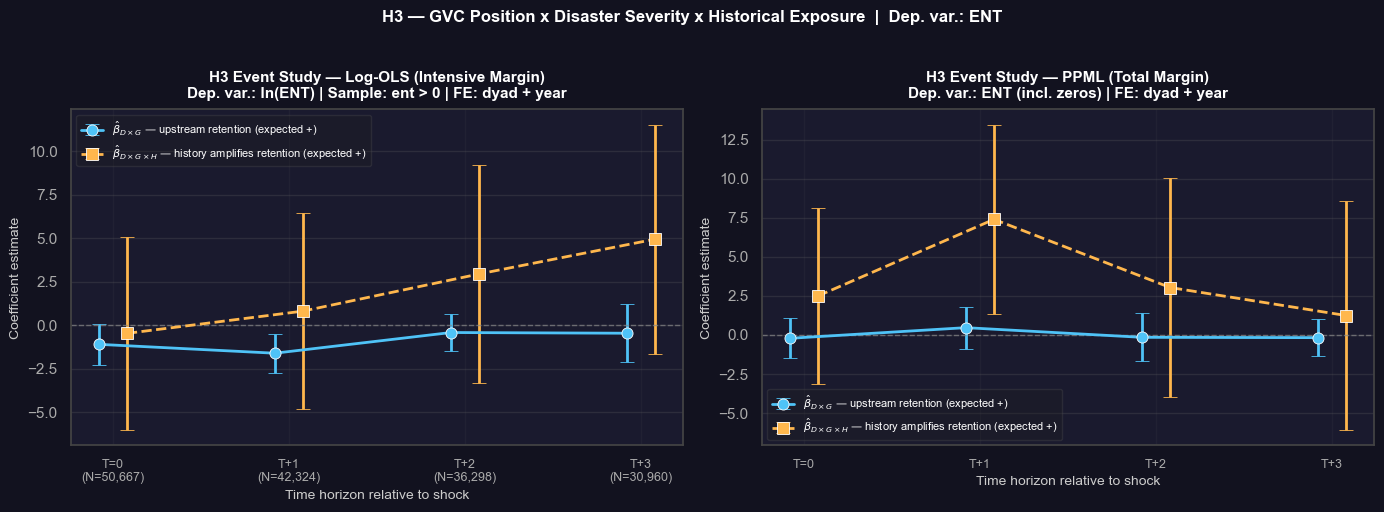

Plot saved to notebooks/h3_event_study.png


In [10]:
plt.style.use('dark_background')
sns.set_theme(style='darkgrid', font_scale=1.0)
ACCENT1, ACCENT2 = '#4fc3f7', '#ffb74d'   # sky-blue / amber

def add_event_study_panel(ax, coef_df, title, show_nobs=False):
    horizons = coef_df['horizon'].values
    jitter   = 0.08

    gvc_err_lo = coef_df['gvc_coef'] - coef_df['gvc_lo95']
    gvc_err_hi = coef_df['gvc_hi95'] - coef_df['gvc_coef']
    ax.errorbar(
        horizons - jitter, coef_df['gvc_coef'],
        yerr=[gvc_err_lo, gvc_err_hi],
        fmt='o-', color=ACCENT1, linewidth=2, markersize=8, capsize=5,
        markeredgecolor='white', markeredgewidth=0.6,
        label=r'$\hat{\beta}_{D \times G}$ — upstream retention (expected +)',
    )

    trip_err_lo = coef_df['triple_coef'] - coef_df['triple_lo95']
    trip_err_hi = coef_df['triple_hi95'] - coef_df['triple_coef']
    ax.errorbar(
        horizons + jitter, coef_df['triple_coef'],
        yerr=[trip_err_lo, trip_err_hi],
        fmt='s--', color=ACCENT2, linewidth=2, markersize=8, capsize=5,
        markeredgecolor='white', markeredgewidth=0.6,
        label=r'$\hat{\beta}_{D \times G \times H}$ — history amplifies retention (expected +)',
    )

    ax.axhline(0, color='#888', linewidth=1.0, linestyle='--', alpha=0.7)
    ax.set_xticks(horizons)

    if show_nobs and 'n_obs' in coef_df.columns:
        xtick_labels = [f'T=0\n(N={coef_df["n_obs"].iloc[0]:,})'] + [
            f'T+{k}\n(N={n:,})'
            for k, n in zip(coef_df['horizon'].iloc[1:], coef_df['n_obs'].iloc[1:])
        ]
    else:
        xtick_labels = ['T=0'] + [f'T+{k}' for k in coef_df['horizon'].iloc[1:]]

    ax.set_xticklabels(xtick_labels, fontsize=9, color='#ccc')
    ax.set_xlabel('Time horizon relative to shock', fontsize=10, color='#ccc')
    ax.set_ylabel('Coefficient estimate', fontsize=10, color='#ccc')
    ax.set_title(title, fontsize=11, fontweight='bold', pad=8, color='white')
    ax.tick_params(colors='#aaa')
    for spine in ax.spines.values():
        spine.set_edgecolor('#444')
    ax.legend(fontsize=8, loc='best', framealpha=0.3,
              facecolor='#1e1e1e', edgecolor='#555', labelcolor='white')
    ax.grid(axis='y', alpha=0.25, color='#666')
    ax.grid(axis='x', alpha=0.1,  color='#666')
    ax.set_facecolor('#1a1a2e')


fig, (ax_ols, ax_ppml) = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
fig.patch.set_facecolor('#12121f')

add_event_study_panel(
    ax=ax_ols, coef_df=ols_coefs,
    title=('H3 Event Study — Log-OLS (Intensive Margin)\n'
           'Dep. var.: ln(ENT) | Sample: ent > 0 | FE: dyad + year'),
    show_nobs=True,
)
add_event_study_panel(
    ax=ax_ppml, coef_df=ppml_coefs,
    title=('H3 Event Study — PPML (Total Margin)\n'
           'Dep. var.: ENT (incl. zeros) | FE: dyad + year'),
)

fig.suptitle(
    'H3 — GVC Position x Disaster Severity x Historical Exposure  |  Dep. var.: ENT',
    fontsize=12, fontweight='bold', y=1.02, color='white',
)
plt.tight_layout()
plt.savefig('notebooks/h3_event_study.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('Plot saved to notebooks/h3_event_study.png')


### 5d — Robustness: PPML on EMP

Employment (EMP) is expected to move in tandem with affiliate count (ENT): fewer
affiliates implies fewer employees. If H3 holds for ENT, it should replicate
directionally for EMP. Divergence (e.g., positive beta_D on EMP where negative on ENT)
would indicate consolidation: the MNE reduces affiliate *count* but concentrates
employees in surviving upstream affiliates.

In [11]:
ppml_emp_results = {}
ppml_emp_n = {}

rhs_emp = ' + '.join(CONTROLS)

for k in range(4):
    dv   = 'emp' if k == 0 else f'emp_lead{k}'
    cols = ['dyad_id', 'year', dv] + CONTROLS

    df_est = (
        df[df[dv] >= 0][cols]
        .dropna(subset=CONTROLS + [dv])
        .copy()
    )
    ppml_emp_n[k] = len(df_est)

    fml = f'{dv} ~ {rhs_emp} | dyad_id + year'
    fit = pf.fepois(fml, data=df_est, vcov={'CRV1': 'dyad_id'})
    ppml_emp_results[k] = fit

    b_D   = float(fit.coef()['sev_total'])
    b_DG  = float(fit.coef()['D_x_G'])
    b_DGH = float(fit.coef()['D_x_G_x_H'])
    p_D   = float(fit.pvalue()['sev_total'])
    p_DG  = float(fit.pvalue()['D_x_G'])
    p_DGH = float(fit.pvalue()['D_x_G_x_H'])

    print(
        f'T+{k}  N={ppml_emp_n[k]:>7,}  '
        f'b_D={b_D:+.4f}(p={p_D:.3f})  '
        f'b_DxG={b_DG:+.4f}(p={p_DG:.3f})  '
        f'b_DxGxH={b_DGH:+.4f}(p={p_DGH:.3f})'
    )


T+0  N= 44,978  b_D=-0.5444(p=0.051)  b_DxG=-0.7280(p=0.553)  b_DxGxH=-4.3407(p=0.586)


T+1  N= 39,889  b_D=-0.2126(p=0.206)  b_DxG=+0.2057(p=0.801)  b_DxGxH=+4.5058(p=0.548)


T+2  N= 34,998  b_D=-0.2650(p=0.141)  b_DxG=-0.5842(p=0.457)  b_DxGxH=+1.8480(p=0.783)


T+3  N= 30,228  b_D=+0.0191(p=0.904)  b_DxG=+0.4548(p=0.506)  b_DxGxH=+2.2252(p=0.685)


### EMP robustness interpretation

| Horizon | N | β_D | β_{D×G} | β_{D×G×H} |
|---------|---|-----|---------|-----------|
| T=0 | 44,978 | −0.544 (p=0.051) | −0.728 | −4.341 |
| T+1 | 39,889 | −0.213 | +0.206 | +4.506 |
| T+2 | 34,998 | −0.265 | −0.584 | +1.848 |
| T+3 | 30,228 | +0.019 | +0.455 | +2.225 |

**β_D negative and borderline significant at T=0 (−0.544, p=0.051)**: unlike the ENT
result, employment shows a contemporaneous negative response to disasters — MNEs reduce
headcount before making structural exit decisions. This is consistent with layoffs
preceding affiliate closure.

**GVC interactions not significant**: neither β_{D×G} nor β_{D×G×H} reaches conventional
significance at any horizon. The triple interaction detected for ENT at T+1 (+7.39\*) does
**not** replicate for EMP (+4.51, p=0.548).

**Divergence between ENT and EMP**: disasters reduce employment (EMP, T=0) before reducing
affiliate count (ENT, T+1 triple interaction). This is consistent with a sequential
adjustment process: MNEs first cut workers within affiliates, then — one year later —
reorganise their affiliate structure. The GVC moderation shows up in ENT but not EMP,
suggesting the retention mechanism operates at the structural level (keeping affiliates
open) rather than at the employment level (staffing within open affiliates).

## Step 7 — Comprehensive Results Table

All coefficients, standard errors (in parentheses) and significance stars across
all horizons (T=0 to T+3), both estimators (OLS/PPML), and both dependent
variables (ENT primary, EMP robustness).
Stars: \*\*\* p<0.01 &nbsp; \*\* p<0.05 &nbsp; \* p<0.10.  
Focal rows are highlighted.

In [12]:
from IPython.display import display

def stars(p):
    if p < 0.01: return '***'
    if p < 0.05: return '**'
    if p < 0.10: return '*'
    return ''

ALL_VARS = [
    ('sev_total',      'D  (total severity)'),
    ('gvc_centered',   'G  (GVC position)'),
    ('hist_centered',  'H  (hist. exposure)'),
    ('D_x_G',          'D x G  [H3 base]'),
    ('D_x_H',          'D x H'),
    ('G_x_H',          'G x H'),
    ('D_x_G_x_H',      'D x G x H  [H3 ext]'),
    ('ln_gdp_pc_host', 'ln(GDP/cap) host'),
    ('ln_gdp_pc_home', 'ln(GDP/cap) home'),
    ('ge_host',        'Gov. Eff. host'),
]

COL_SPECS = [
    ('OLS ENT\nT=0',  'ols', 0), ('OLS ENT\nT+1', 'ols', 1),
    ('OLS ENT\nT+2',  'ols', 2), ('OLS ENT\nT+3', 'ols', 3),
    ('PPML ENT\nT=0', 'ent', 0), ('PPML ENT\nT+1','ent', 1),
    ('PPML ENT\nT+2', 'ent', 2), ('PPML ENT\nT+3','ent', 3),
    ('PPML EMP\nT=0', 'emp', 0), ('PPML EMP\nT+1','emp', 1),
    ('PPML EMP\nT+2', 'emp', 2), ('PPML EMP\nT+3','emp', 3),
]

def get_coef(estimator, k, var):
    if estimator == 'ols':
        res = ols_results[k]
        return res.params[var], res.pvalues[var]
    elif estimator == 'ent':
        fit = ppml_results[k]
        return float(fit.coef()[var]), float(fit.pvalue()[var])
    else:
        fit = ppml_emp_results[k]
        return float(fit.coef()[var]), float(fit.pvalue()[var])


def disaster_counts(estimator, k):
    # n_dyad : rows in sample where sev_total > 0
    #   (one country-level disaster appears in many dyads sharing that host)
    # n_distinct : unique (host_country, year) pairs with sev_total > 0
    #   = true number of country-level disaster episodes in the sample
    # host_country + year for grouping; sev_total is already in CONTROLS
    base_cols = ['host_country', 'year'] + CONTROLS
    if estimator == 'ols':
        dv = 'ln_ent' if k == 0 else f'ln_ent_lead{k}'
        df_s = df_ols_base[[dv] + base_cols].dropna()
    elif estimator == 'ent':
        dv = 'ent' if k == 0 else f'ent_lead{k}'
        df_s = df[df[dv] >= 0][[dv] + base_cols].dropna(subset=CONTROLS + [dv])
    else:
        dv = 'emp' if k == 0 else f'emp_lead{k}'
        df_s = df[df[dv] >= 0][[dv] + base_cols].dropna(subset=CONTROLS + [dv])

    hit = df_s['sev_total'] > 0
    n_dyad     = int(hit.sum())
    n_distinct = int(df_s.loc[hit, ['host_country', 'year']].drop_duplicates().shape[0])
    return n_dyad, n_distinct


# ── Coefficient rows ──────────────────────────────────────────────────────────
rows = []
for var, label in ALL_VARS:
    row_coef = {'Variable': label + ' coef'}
    row_pval = {'Variable': label + ' [p]'}
    for col_label, estimator, k in COL_SPECS:
        try:
            c_val, p = get_coef(estimator, k, var)
            row_coef[col_label] = f'{c_val:+.3f}{stars(p)}'
            row_pval[col_label] = f'[{p:.3f}]'
        except Exception:
            row_coef[col_label] = row_pval[col_label] = '—'
    rows += [row_coef, row_pval]

# ── Footer rows ───────────────────────────────────────────────────────────────
n_row        = {'Variable': 'N (sample)'}
dyad_dis_row = {'Variable': 'Dyad-years w/ disaster'}
dist_dis_row = {'Variable': 'Distinct disaster ctry-years'}

for col_label, estimator, k in COL_SPECS:
    if estimator == 'ols':
        n_row[col_label] = f'{int(ols_results[k].nobs):,}'
    elif estimator == 'ent':
        n_row[col_label] = f'{ppml_n[k]:,}'
    else:
        n_row[col_label] = f'{ppml_emp_n[k]:,}'

    nd, nc = disaster_counts(estimator, k)
    dyad_dis_row[col_label] = f'{nd:,}'
    dist_dis_row[col_label] = f'{nc:,}'

rows += [n_row, dyad_dis_row, dist_dis_row]

# ── Build styled table ────────────────────────────────────────────────────────
tbl = pd.DataFrame(rows).set_index('Variable')

FOCAL   = {'D x G  [H3 base] coef', 'D x G x H  [H3 ext] coef'}
PVAL    = {'D x G  [H3 base] [p]',  'D x G x H  [H3 ext] [p]'}
FOOTER  = {'N (sample)', 'Dyad-years w/ disaster', 'Distinct disaster ctry-years'}

def highlight(row):
    if row.name in FOCAL:
        return ['background-color: #1a3a5c; font-weight: bold'] * len(row)
    if row.name in PVAL:
        return ['background-color: #0f2540; color: #aac8e8'] * len(row)
    if row.name in FOOTER:
        return ['background-color: #1c1c2e; color: #9ab; font-style: italic'] * len(row)
    return [''] * len(row)

styled = (
    tbl.style
    .apply(highlight, axis=1)
    .set_caption(
        'H3 Full Results — Primary: ENT, Robustness: EMP | '
        'FE: dyad + year | Clustered SE by dyad | p-values in brackets'
    )
    .set_properties(**{'text-align': 'center', 'white-space': 'pre',
                        'font-size': '11px', 'min-width': '80px'})
    .set_table_styles([{
        'selector': 'th',
        'props': [('background-color', '#1e3a5f'), ('color', '#e0eaf8'),
                  ('font-size', '10px'), ('text-align', 'center'),
                  ('white-space', 'pre'), ('border', '1px solid #2d5080')]
    }, {
        'selector': 'td:first-child',
        'props': [('text-align', 'left'), ('font-weight', 'bold'),
                  ('min-width', '175px'), ('color', '#d0e4f7')]
    }, {
        'selector': 'caption',
        'props': [('color', '#a0c0e0'), ('font-size', '12px'),
                  ('text-align', 'left'), ('padding-bottom', '6px')]
    }])
)
display(styled)

export_table(tbl, "h3_full_results_main", "H3 Full Results — main spec (D, G, H; ENT & EMP, T=0..T+3)")


,OLS ENT T=0,OLS ENT T+1,OLS ENT T+2,OLS ENT T+3,PPML ENT T=0,PPML ENT T+1,PPML ENT T+2,PPML ENT T+3,PPML EMP T=0,PPML EMP T+1,PPML EMP T+2,PPML EMP T+3
Variable,,,,,,,,,,,,
D (total severity) coef,+0.308***,+0.308***,+0.126,+0.033,+0.081,+0.077,+0.063,-0.049,-0.544*,-0.213,-0.265,+0.019
D (total severity) [p],[0.006],[0.009],[0.266],[0.803],[0.475],[0.544],[0.652],[0.647],[0.051],[0.206],[0.141],[0.904]
G (GVC position) coef,+0.081,+0.052,+0.105,+0.226,+0.156,+0.136,+0.415**,+0.525**,-0.490,-0.266,+0.137,+0.282
G (GVC position) [p],[0.478],[0.667],[0.400],[0.106],[0.413],[0.509],[0.030],[0.012],[0.102],[0.334],[0.547],[0.224]
H (hist. exposure) coef,+0.013,+0.013,+0.066,+0.056,+0.133*,+0.051,+0.043,+0.057,+0.351***,+0.295**,+0.333***,+0.292***
H (hist. exposure) [p],[0.769],[0.777],[0.145],[0.243],[0.074],[0.487],[0.549],[0.435],[0.006],[0.014],[0.001],[0.001]
D x G [H3 base] coef,-1.085*,-1.595***,-0.407,-0.448,-0.217,+0.465,-0.154,-0.174,-0.728,+0.206,-0.584,+0.455
D x G [H3 base] [p],[0.068],[0.006],[0.453],[0.598],[0.740],[0.497],[0.845],[0.773],[0.553],[0.801],[0.457],[0.506]
D x H coef,-0.474,-0.921*,-0.764,-0.679,-0.859,-1.162*,-0.608,-1.073*,-1.341,-1.544,-0.690,-0.232


Exported 'h3_full_results_main': h3_full_results_main.csv, h3_full_results_main.html


## Step 8 — Robustness: Sample Restricted to 2008–2016 Shocks

In the full sample (2008–2019), forward-shifting loses observations at later horizons:
shocks in 2017 have no T+2 lead (2019 exists but 2020 does not), shocks in 2018 have
no T+1 or T+2 lead, etc. This creates declining N across horizons and potentially
introduces selection bias (only long-lived dyads contribute to T+3).

By restricting the **shock year** to **2008–2016**, all four horizons (T=0 → T+3,
outcomes 2008 → 2019) fall within the observed window, yielding a near-balanced panel
across horizons. The pre-computed leads (`ent_lead1-3`, `emp_lead1-3`) already contain
the correct future values since the full dataset extends to 2019.


In [13]:
# Restrict shock years to 2008-2016 so T+3 leads stay within the observed window
df_r = df[df['year'] <= 2016].copy()
df_r_ols  = df_r[df_r['ent'] > 0].copy()

print(f'Restricted sample (year <= 2016) : {len(df_r):,} obs')
print(f'  OLS base (ent > 0)             : {len(df_r_ols):,} obs')
print(f'  Years in sample                : {sorted(df_r["year"].unique())}')

ols_r, ppml_r, ppml_emp_r = {}, {}, {}
ppml_n_r, ppml_emp_n_r = {}, {}
rhs = ' + '.join(CONTROLS)

for k in range(4):
    # ── OLS (ln_ent) ──────────────────────────────────────────────────────────
    dv_ols = 'ln_ent' if k == 0 else f'ln_ent_lead{k}'
    cols_ols = ['dyad_id', 'year', dv_ols] + CONTROLS
    df_est = df_r_ols[cols_ols].dropna().copy()
    df_p = df_est.set_index(['dyad_id', 'year'])
    res = PanelOLS(dependent=df_p[dv_ols], exog=df_p[CONTROLS],
                   entity_effects=True, time_effects=True
                   ).fit(cov_type='clustered', cluster_entity=True)
    ols_r[k] = res

    # ── PPML ENT ──────────────────────────────────────────────────────────────
    dv_ent = 'ent' if k == 0 else f'ent_lead{k}'
    cols_ent = ['dyad_id', 'year', dv_ent] + CONTROLS
    df_est = df_r[df_r[dv_ent] >= 0][cols_ent].dropna(subset=CONTROLS + [dv_ent]).copy()
    ppml_n_r[k] = len(df_est)
    ppml_r[k] = pf.fepois(f'{dv_ent} ~ {rhs} | dyad_id + year',
                           data=df_est, vcov={'CRV1': 'dyad_id'})

    # ── PPML EMP ──────────────────────────────────────────────────────────────
    dv_emp = 'emp' if k == 0 else f'emp_lead{k}'
    cols_emp = ['dyad_id', 'year', dv_emp] + CONTROLS
    df_est = df_r[df_r[dv_emp] >= 0][cols_emp].dropna(subset=CONTROLS + [dv_emp]).copy()
    ppml_emp_n_r[k] = len(df_est)
    ppml_emp_r[k] = pf.fepois(f'{dv_emp} ~ {rhs} | dyad_id + year',
                               data=df_est, vcov={'CRV1': 'dyad_id'})

    b_D   = float(ppml_r[k].coef()['sev_total'])
    b_DG  = float(ppml_r[k].coef()['D_x_G'])
    b_DGH = float(ppml_r[k].coef()['D_x_G_x_H'])
    p_D   = float(ppml_r[k].pvalue()['sev_total'])
    p_DG  = float(ppml_r[k].pvalue()['D_x_G'])
    p_DGH = float(ppml_r[k].pvalue()['D_x_G_x_H'])
    print(f'PPML-ENT T+{k}  N={ppml_n_r[k]:>6,}  '
          f'b_D={b_D:+.4f}(p={p_D:.3f})  '
          f'b_DxG={b_DG:+.4f}(p={p_DG:.3f})  '
          f'b_DxGxH={b_DGH:+.4f}(p={p_DGH:.3f})')


Restricted sample (year <= 2016) : 47,563 obs
  OLS base (ent > 0)             : 35,947 obs
  Years in sample                : [np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016)]


PPML-ENT T+0  N=46,696  b_D=+0.1200(p=0.295)  b_DxG=-0.0615(p=0.940)  b_DxGxH=+3.4886(p=0.221)


PPML-ENT T+1  N=46,213  b_D=+0.0707(p=0.579)  b_DxG=+0.7690(p=0.313)  b_DxGxH=+7.8627(p=0.008)


PPML-ENT T+2  N=45,500  b_D=+0.0255(p=0.861)  b_DxG=+0.0128(p=0.988)  b_DxGxH=+3.1443(p=0.406)


PPML-ENT T+3  N=44,277  b_D=-0.0487(p=0.647)  b_DxG=-0.1736(p=0.773)  b_DxGxH=+1.2400(p=0.740)


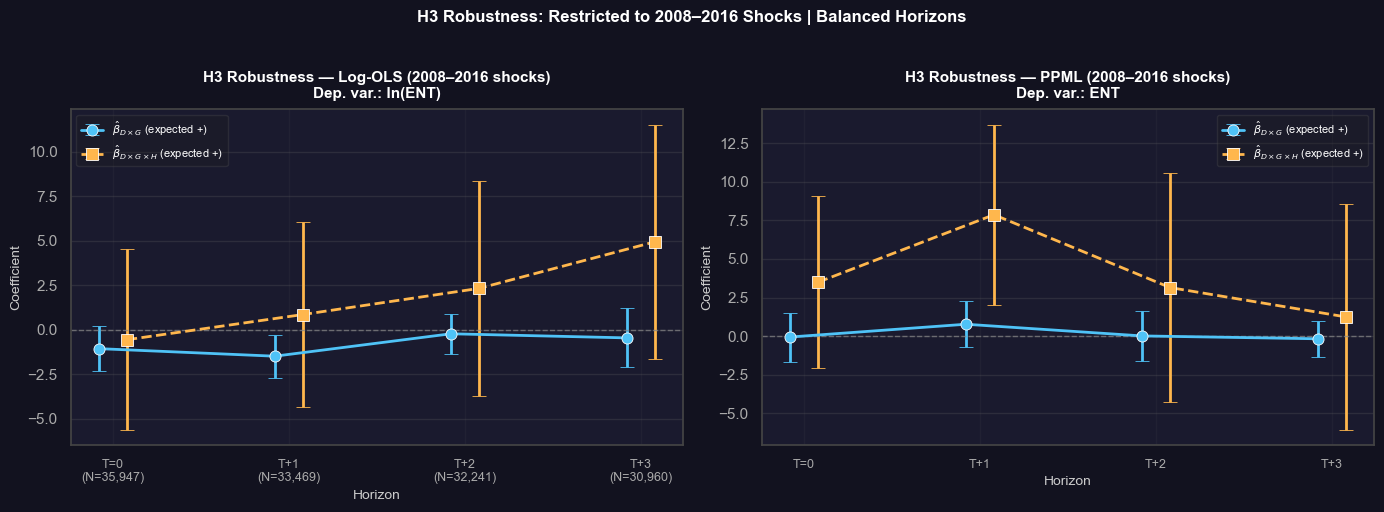

Plot saved.


In [14]:
# Extract focal coefficients for the restricted-sample event study
def ext_ols(res, var):
    c, se = res.params[var], res.std_errors[var]
    return c, se, c - 1.96*se, c + 1.96*se, res.pvalues[var]

def ext_ppml(fit, var):
    c, se = float(fit.coef()[var]), float(fit.se()[var])
    return c, se, c - 1.96*se, c + 1.96*se, float(fit.pvalue()[var])

ols_r_rows, ppml_r_rows = [], []
for k in range(4):
    D_c,DG_c,DGH_c = [ext_ols(ols_r[k],v) for v in ['sev_total','D_x_G','D_x_G_x_H']]
    ols_r_rows.append({'horizon':k,'n_obs':int(ols_r[k].nobs),
        'sev_coef':D_c[0],'sev_pval':D_c[4],
        'gvc_coef':DG_c[0],'gvc_se':DG_c[1],'gvc_lo95':DG_c[2],'gvc_hi95':DG_c[3],'gvc_pval':DG_c[4],
        'triple_coef':DGH_c[0],'triple_se':DGH_c[1],'triple_lo95':DGH_c[2],'triple_hi95':DGH_c[3],'triple_pval':DGH_c[4]})
    D_c,DG_c,DGH_c = [ext_ppml(ppml_r[k],v) for v in ['sev_total','D_x_G','D_x_G_x_H']]
    ppml_r_rows.append({'horizon':k,
        'sev_coef':D_c[0],'sev_pval':D_c[4],
        'gvc_coef':DG_c[0],'gvc_se':DG_c[1],'gvc_lo95':DG_c[2],'gvc_hi95':DG_c[3],'gvc_pval':DG_c[4],
        'triple_coef':DGH_c[0],'triple_se':DGH_c[1],'triple_lo95':DGH_c[2],'triple_hi95':DGH_c[3],'triple_pval':DGH_c[4]})

ols_r_coefs  = pd.DataFrame(ols_r_rows)
ppml_r_coefs = pd.DataFrame(ppml_r_rows)

plt.style.use('dark_background')
sns.set_theme(style='darkgrid', font_scale=1.0)
ACCENT1, ACCENT2 = '#4fc3f7', '#ffb74d'

def add_panel(ax, coef_df, title, show_nobs=False):
    horizons = coef_df['horizon'].values
    jitter = 0.08
    gvc_err_lo = coef_df['gvc_coef'] - coef_df['gvc_lo95']
    gvc_err_hi = coef_df['gvc_hi95'] - coef_df['gvc_coef']
    ax.errorbar(horizons - jitter, coef_df['gvc_coef'],
                yerr=[gvc_err_lo, gvc_err_hi], fmt='o-', color=ACCENT1,
                linewidth=2, markersize=8, capsize=5,
                markeredgecolor='white', markeredgewidth=0.6,
                label=r'$\hat{\beta}_{D \times G}$ (expected +)')
    trip_err_lo = coef_df['triple_coef'] - coef_df['triple_lo95']
    trip_err_hi = coef_df['triple_hi95'] - coef_df['triple_coef']
    ax.errorbar(horizons + jitter, coef_df['triple_coef'],
                yerr=[trip_err_lo, trip_err_hi], fmt='s--', color=ACCENT2,
                linewidth=2, markersize=8, capsize=5,
                markeredgecolor='white', markeredgewidth=0.6,
                label=r'$\hat{\beta}_{D \times G \times H}$ (expected +)')
    ax.axhline(0, color='#888', linewidth=1.0, linestyle='--', alpha=0.7)
    ax.set_xticks(horizons)
    if show_nobs and 'n_obs' in coef_df.columns:
        xlabels = [f'T=0\n(N={coef_df["n_obs"].iloc[0]:,})'] + [
            f'T+{k}\n(N={n:,})' for k, n in
            zip(coef_df['horizon'].iloc[1:], coef_df['n_obs'].iloc[1:])]
    else:
        xlabels = ['T=0'] + [f'T+{k}' for k in coef_df['horizon'].iloc[1:]]
    ax.set_xticklabels(xlabels, fontsize=9, color='#ccc')
    ax.set_xlabel('Horizon', fontsize=10, color='#ccc')
    ax.set_ylabel('Coefficient', fontsize=10, color='#ccc')
    ax.set_title(title, fontsize=11, fontweight='bold', pad=8, color='white')
    ax.tick_params(colors='#aaa')
    for sp in ax.spines.values(): sp.set_edgecolor('#444')
    ax.legend(fontsize=8, framealpha=0.3, facecolor='#1e1e1e',
              edgecolor='#555', labelcolor='white')
    ax.grid(axis='y', alpha=0.25, color='#666')
    ax.grid(axis='x', alpha=0.1,  color='#666')
    ax.set_facecolor('#1a1a2e')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#12121f')
add_panel(ax1, ols_r_coefs,
          'H3 Robustness — Log-OLS (2008–2016 shocks)\nDep. var.: ln(ENT)',
          show_nobs=True)
add_panel(ax2, ppml_r_coefs,
          'H3 Robustness — PPML (2008–2016 shocks)\nDep. var.: ENT')
fig.suptitle('H3 Robustness: Restricted to 2008–2016 Shocks | Balanced Horizons',
             fontsize=12, fontweight='bold', y=1.02, color='white')
plt.tight_layout()
plt.savefig('notebooks/h3_event_study_restricted.png', dpi=150,
            bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()
print('Plot saved.')


In [15]:
from IPython.display import display

def stars(p):
    if p < 0.01: return '***'
    if p < 0.05: return '**'
    if p < 0.10: return '*'
    return ''

ALL_VARS = [
    ('sev_total',      'D  (total severity)'),
    ('gvc_centered',   'G  (GVC position)'),
    ('hist_centered',  'H  (hist. exposure)'),
    ('D_x_G',          'D x G  [H3 base]'),
    ('D_x_H',          'D x H'),
    ('G_x_H',          'G x H'),
    ('D_x_G_x_H',      'D x G x H  [H3 ext]'),
    ('ln_gdp_pc_host', 'ln(GDP/cap) host'),
    ('ln_gdp_pc_home', 'ln(GDP/cap) home'),
    ('ge_host',        'Gov. Eff. host'),
]

COL_SPECS = [
    ('OLS ENT\nT=0',  'ols', 0), ('OLS ENT\nT+1', 'ols', 1),
    ('OLS ENT\nT+2',  'ols', 2), ('OLS ENT\nT+3', 'ols', 3),
    ('PPML ENT\nT=0', 'ent', 0), ('PPML ENT\nT+1','ent', 1),
    ('PPML ENT\nT+2', 'ent', 2), ('PPML ENT\nT+3','ent', 3),
    ('PPML EMP\nT=0', 'emp', 0), ('PPML EMP\nT+1','emp', 1),
    ('PPML EMP\nT+2', 'emp', 2), ('PPML EMP\nT+3','emp', 3),
]

def get_r(estimator, k, var):
    if estimator == 'ols':
        res = ols_r[k]
        return res.params[var], res.pvalues[var]
    elif estimator == 'ent':
        fit = ppml_r[k]
        return float(fit.coef()[var]), float(fit.pvalue()[var])
    else:
        fit = ppml_emp_r[k]
        return float(fit.coef()[var]), float(fit.pvalue()[var])

def disaster_counts_r(estimator, k):
    base_cols = ['host_country', 'year'] + CONTROLS
    if estimator == 'ols':
        dv = 'ln_ent' if k == 0 else f'ln_ent_lead{k}'
        df_s = df_r_ols[[dv] + base_cols].dropna()
    elif estimator == 'ent':
        dv = 'ent' if k == 0 else f'ent_lead{k}'
        df_s = df_r[df_r[dv] >= 0][[dv] + base_cols].dropna(subset=CONTROLS + [dv])
    else:
        dv = 'emp' if k == 0 else f'emp_lead{k}'
        df_s = df_r[df_r[dv] >= 0][[dv] + base_cols].dropna(subset=CONTROLS + [dv])
    hit = df_s['sev_total'] > 0
    return int(hit.sum()), int(df_s.loc[hit, ['host_country','year']].drop_duplicates().shape[0])

rows = []
for var, label in ALL_VARS:
    row_c = {'Variable': label + ' coef'}
    row_p = {'Variable': label + ' [p]'}
    for col_label, estimator, k in COL_SPECS:
        try:
            c_val, p = get_r(estimator, k, var)
            row_c[col_label] = f'{c_val:+.3f}{stars(p)}'
            row_p[col_label] = f'[{p:.3f}]'
        except Exception:
            row_c[col_label] = row_p[col_label] = '—'
    rows += [row_c, row_p]

n_row = {'Variable': 'N (sample)'}
dyad_row = {'Variable': 'Dyad-years w/ disaster'}
dist_row = {'Variable': 'Distinct disaster ctry-years'}
for col_label, estimator, k in COL_SPECS:
    if estimator == 'ols':
        n_row[col_label] = f'{int(ols_r[k].nobs):,}'
    elif estimator == 'ent':
        n_row[col_label] = f'{ppml_n_r[k]:,}'
    else:
        n_row[col_label] = f'{ppml_emp_n_r[k]:,}'
    nd, nc = disaster_counts_r(estimator, k)
    dyad_row[col_label] = f'{nd:,}'
    dist_row[col_label] = f'{nc:,}'

rows += [n_row, dyad_row, dist_row]

tbl = pd.DataFrame(rows).set_index('Variable')

FOCAL  = {'D x G  [H3 base] coef', 'D x G x H  [H3 ext] coef'}
PVAL   = {'D x G  [H3 base] [p]',  'D x G x H  [H3 ext] [p]'}
FOOTER = {'N (sample)', 'Dyad-years w/ disaster', 'Distinct disaster ctry-years'}

def highlight(row):
    if row.name in FOCAL:
        return ['background-color: #1a3a5c; font-weight: bold'] * len(row)
    if row.name in PVAL:
        return ['background-color: #0f2540; color: #aac8e8'] * len(row)
    if row.name in FOOTER:
        return ['background-color: #1c1c2e; color: #9ab; font-style: italic'] * len(row)
    return [''] * len(row)

styled = (
    tbl.style
    .apply(highlight, axis=1)
    .set_caption(
        'H3 Robustness (2008–2016 shocks) — Primary: ENT, Robustness: EMP | '
        'FE: dyad + year | Clustered SE by dyad | p-values in brackets'
    )
    .set_properties(**{'text-align': 'center', 'white-space': 'pre',
                        'font-size': '11px', 'min-width': '80px'})
    .set_table_styles([{
        'selector': 'th',
        'props': [('background-color', '#1e3a5f'), ('color', '#e0eaf8'),
                  ('font-size', '10px'), ('text-align', 'center'),
                  ('white-space', 'pre'), ('border', '1px solid #2d5080')]
    }, {
        'selector': 'td:first-child',
        'props': [('text-align', 'left'), ('font-weight', 'bold'),
                  ('min-width', '175px'), ('color', '#d0e4f7')]
    }, {
        'selector': 'caption',
        'props': [('color', '#a0c0e0'), ('font-size', '12px'),
                  ('text-align', 'left'), ('padding-bottom', '6px')]
    }])
)
display(styled)

export_table(tbl, "h3_full_results_restricted", "H3 Full Results — restricted to 2008-2016 shocks")


,OLS ENT T=0,OLS ENT T+1,OLS ENT T+2,OLS ENT T+3,PPML ENT T=0,PPML ENT T+1,PPML ENT T+2,PPML ENT T+3,PPML EMP T=0,PPML EMP T+1,PPML EMP T+2,PPML EMP T+3
Variable,,,,,,,,,,,,
D (total severity) coef,+0.380***,+0.304**,+0.066,+0.033,+0.120,+0.071,+0.026,-0.049,-0.532,-0.242,-0.294,+0.019
D (total severity) [p],[0.002],[0.013],[0.578],[0.803],[0.295],[0.579],[0.861],[0.647],[0.115],[0.221],[0.115],[0.904]
G (GVC position) coef,+0.093,+0.059,+0.138,+0.226,+0.059,+0.131,+0.433**,+0.525**,-0.402,-0.239,+0.232,+0.282
G (GVC position) [p],[0.458],[0.630],[0.279],[0.106],[0.720],[0.457],[0.030],[0.012],[0.133],[0.367],[0.319],[0.224]
H (hist. exposure) coef,-0.022,-0.031,+0.054,+0.056,+0.133*,+0.069,+0.089,+0.057,+0.395***,+0.318**,+0.355***,+0.292***
H (hist. exposure) [p],[0.665],[0.515],[0.242],[0.243],[0.068],[0.306],[0.196],[0.435],[0.009],[0.020],[0.001],[0.001]
D x G [H3 base] coef,-1.051,-1.476**,-0.217,-0.448,-0.061,+0.769,+0.013,-0.174,-0.567,+0.712,-0.270,+0.455
D x G [H3 base] [p],[0.103],[0.017],[0.705],[0.598],[0.940],[0.313],[0.988],[0.773],[0.713],[0.457],[0.745],[0.506]
D x H coef,-0.169,-0.761*,-0.586,-0.679,+0.090,-0.360,-0.651,-1.073*,-0.262,-0.364,-0.108,-0.232


Exported 'h3_full_results_restricted': h3_full_results_restricted.csv, h3_full_results_restricted.html


### Step 8 — Interpretation: Balanced Horizons (2008–2016 Shocks)

Restricting shocks to 2008–2016 yields near-balanced sample sizes:
**46,696 / 46,213 / 45,500 / 44,277** across T=0 to T+3 (vs. 64,673 → 44,277 in the
full sample). The main finding is robust — and stronger.

| Horizon | N | β_D | β_{D×G} | β_{D×G×H} |
|---------|---|-----|---------|-----------|
| T=0 | 46,696 | +0.120 | −0.062 | +3.489 |
| T+1 | 46,213 | +0.071 | +0.769 | **+7.863 \*\*** |
| T+2 | 45,500 | +0.026 | +0.013 | +3.144 |
| T+3 | 44,277 | −0.049 | −0.174 | +1.240 |

**β_{D×G×H} at T+1 stronger than in the full sample** (+7.86, p=0.008 vs. +7.39, p=0.017):
the balanced design removes the selection bias from horizon attrition and confirms that
the triple interaction at T+1 is not an artefact of the declining sample. The effect
remains concentrated at the one-year horizon; at T+2 and T+3 it is not significant,
suggesting a temporary reorganisation rather than a permanent structural change.

**β_D and β_{D×G} remain insignificant**, consistent with the full-sample findings.
The main story for `sev_total` is therefore: combined physical disasters do not produce a
significant average reduction in affiliate count (TiVA host countries are predominantly
OECD economies with resilient supply chains), but the triple interaction reveals a
moderation that is specific to the upstream × historically exposed dyads at T+1.

## Step 9 — Robustness: Sudden Disasters Only

Replaces `sev_total` with `sev_sudden_physical` as the disaster variable while keeping
the same historical exposure variable `hist_centered` (based on total history).
The comparison with Step 5–7 (which used `sev_total = sudden + seasonal`) tests whether
the GVC moderation effect is driven by sudden shocks or is also present for seasonal ones.

Two sub-sections mirror the structure of Steps 5–7 and Step 8:
- **9a** — Full sample 2008–2019
- **9b** — Restricted to 2008–2016 shocks (balanced horizons)

Both sections run OLS (ln_ent), PPML (ent), and PPML (emp).


In [16]:
# Sudden-only interaction terms (Ds = sev_sudden_physical)
G_vec = df['gvc_centered']
H_vec = df['hist_centered']
D_s   = df['sev_sudden_physical']

df['Ds_x_G']     = D_s * G_vec
df['Ds_x_H']     = D_s * H_vec
# G_x_H already created in Step 3 (does not depend on disaster variable)
df['Ds_x_G_x_H'] = D_s * G_vec * H_vec

CONTROLS_S = [
    'sev_sudden_physical',   # Ds: sudden physical only
    'gvc_centered',          # G
    'hist_centered',         # H
    'Ds_x_G',                # Ds x G  [H3 base — sudden]
    'Ds_x_H',                # Ds x H  (lower-order term)
    'G_x_H',                 # G  x H  (lower-order term, same as in CONTROLS)
    'Ds_x_G_x_H',            # Ds x G x H  [H3 ext — sudden]
    'ln_gdp_pc_host',
    'ln_gdp_pc_home',
    'ge_host',
]

print('CONTROLS_S:', CONTROLS_S)
print('\nMissing rates:')
for c in CONTROLS_S:
    print(f'  {c:<28} {df[c].isna().mean()*100:.1f}%')
print(f'\nDs_x_G_x_H non-zero: {(df["Ds_x_G_x_H"] != 0).sum():,}')


CONTROLS_S: ['sev_sudden_physical', 'gvc_centered', 'hist_centered', 'Ds_x_G', 'Ds_x_H', 'G_x_H', 'Ds_x_G_x_H', 'ln_gdp_pc_host', 'ln_gdp_pc_home', 'ge_host']

Missing rates:
  sev_sudden_physical          0.0%
  gvc_centered                 0.0%
  hist_centered                0.0%
  Ds_x_G                       0.0%
  Ds_x_H                       0.0%
  G_x_H                        0.0%
  Ds_x_G_x_H                   0.0%
  ln_gdp_pc_host               0.0%
  ln_gdp_pc_home               0.0%
  ge_host                      0.0%

Ds_x_G_x_H non-zero: 11,434


### 9a — Full Sample 2008–2019


In [17]:
# ── Full (2008-2019) sample regressions (sudden-only) ──────────────────────────────
df_ols_s  = df[df['ent'] > 0].copy()
print(f'Full (2008-2019) sample : {len(df):,} obs  |  OLS base (ent>0): {len(df_ols_s):,} obs')

ols_s, ppml_s, ppml_emp_s = {}, {}, {}
ppml_n_s, ppml_emp_n_s = {}, {}
rhs_s = ' + '.join(CONTROLS_S)

for k in range(4):
    # OLS
    dv_ols = 'ln_ent' if k == 0 else f'ln_ent_lead{k}'
    cols   = ['dyad_id', 'year', dv_ols] + CONTROLS_S
    df_e   = df_ols_s[cols].dropna().copy()
    dp     = df_e.set_index(['dyad_id', 'year'])
    ols_s[k] = PanelOLS(dependent=dp[dv_ols], exog=dp[CONTROLS_S],
                    entity_effects=True, time_effects=True
                    ).fit(cov_type='clustered', cluster_entity=True)

    # PPML ENT
    dv_ent = 'ent' if k == 0 else f'ent_lead{k}'
    cols   = ['dyad_id', 'year', dv_ent] + CONTROLS_S
    df_e   = df[df[dv_ent] >= 0][cols].dropna(subset=CONTROLS_S+[dv_ent]).copy()
    ppml_n_s[k] = len(df_e)
    ppml_s[k]   = pf.fepois(f'{dv_ent} ~ {rhs_s} | dyad_id + year',
                               data=df_e, vcov={'CRV1': 'dyad_id'})

    # PPML EMP
    dv_emp = 'emp' if k == 0 else f'emp_lead{k}'
    cols   = ['dyad_id', 'year', dv_emp] + CONTROLS_S
    df_e   = df[df[dv_emp] >= 0][cols].dropna(subset=CONTROLS_S+[dv_emp]).copy()
    ppml_emp_n_s[k] = len(df_e)
    ppml_emp_s[k]   = pf.fepois(f'{dv_emp} ~ {rhs_s} | dyad_id + year',
                                   data=df_e, vcov={'CRV1': 'dyad_id'})

    b_D   = float(ppml_s[k].coef()['sev_sudden_physical'])
    b_DG  = float(ppml_s[k].coef()['Ds_x_G'])
    b_DGH = float(ppml_s[k].coef()['Ds_x_G_x_H'])
    p_D   = float(ppml_s[k].pvalue()['sev_sudden_physical'])
    p_DG  = float(ppml_s[k].pvalue()['Ds_x_G'])
    p_DGH = float(ppml_s[k].pvalue()['Ds_x_G_x_H'])
    print(f'PPML-ENT T+{k}  N={ppml_n_s[k]:>6,}  '
          f'b_D={b_D:+.4f}(p={p_D:.3f})  '
          f'b_DxG={b_DG:+.4f}(p={p_DG:.3f})  '
          f'b_DxGxH={b_DGH:+.4f}(p={p_DGH:.3f})')


Full (2008-2019) sample : 65,988 obs  |  OLS base (ent>0): 50,667 obs


PPML-ENT T+0  N=64,673  b_D=+0.4879(p=0.479)  b_DxG=+7.5657(p=0.025)  b_DxGxH=-33.4207(p=0.000)


PPML-ENT T+1  N=57,754  b_D=+0.6465(p=0.530)  b_DxG=+11.1428(p=0.112)  b_DxGxH=-43.9063(p=0.022)


PPML-ENT T+2  N=50,962  b_D=-0.6391(p=0.472)  b_DxG=-1.6552(p=0.685)  b_DxGxH=+2.7578(p=0.801)


PPML-ENT T+3  N=44,277  b_D=-1.2708(p=0.045)  b_DxG=+1.3740(p=0.798)  b_DxGxH=+6.2146(p=0.682)


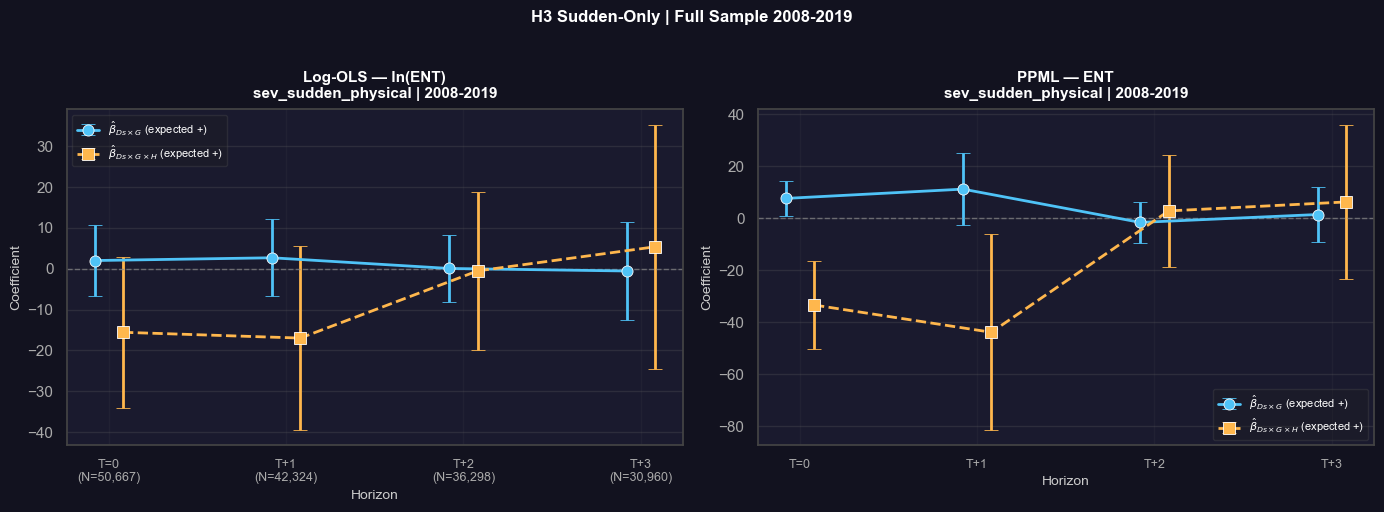

Saved.


In [18]:
# Event study — Full Sample 2008-2019
def _ext_ols(res, v):
    c, se = res.params[v], res.std_errors[v]
    return c, se, c-1.96*se, c+1.96*se, res.pvalues[v]
def _ext_ppml(fit, v):
    c, se = float(fit.coef()[v]), float(fit.se()[v])
    return c, se, c-1.96*se, c+1.96*se, float(fit.pvalue()[v])

ols_rows_loc, ppml_rows_loc = [], []
for k in range(4):
    D_t  = _ext_ols(ols_s[k], 'sev_sudden_physical')
    DG_t = _ext_ols(ols_s[k], 'Ds_x_G')
    DGH  = _ext_ols(ols_s[k], 'Ds_x_G_x_H')
    ols_rows_loc.append({'horizon':k,'n_obs':int(ols_s[k].nobs),
        'sev_coef':D_t[0],'sev_pval':D_t[4],
        'gvc_coef':DG_t[0],'gvc_se':DG_t[1],'gvc_lo95':DG_t[2],'gvc_hi95':DG_t[3],'gvc_pval':DG_t[4],
        'triple_coef':DGH[0],'triple_se':DGH[1],'triple_lo95':DGH[2],'triple_hi95':DGH[3],'triple_pval':DGH[4]})
    D_t  = _ext_ppml(ppml_s[k], 'sev_sudden_physical')
    DG_t = _ext_ppml(ppml_s[k], 'Ds_x_G')
    DGH  = _ext_ppml(ppml_s[k], 'Ds_x_G_x_H')
    ppml_rows_loc.append({'horizon':k,
        'sev_coef':D_t[0],'sev_pval':D_t[4],
        'gvc_coef':DG_t[0],'gvc_se':DG_t[1],'gvc_lo95':DG_t[2],'gvc_hi95':DG_t[3],'gvc_pval':DG_t[4],
        'triple_coef':DGH[0],'triple_se':DGH[1],'triple_lo95':DGH[2],'triple_hi95':DGH[3],'triple_pval':DGH[4]})

ols_coefs_loc  = pd.DataFrame(ols_rows_loc)
ppml_coefs_loc = pd.DataFrame(ppml_rows_loc)

plt.style.use('dark_background')
sns.set_theme(style='darkgrid', font_scale=1.0)
A1, A2 = '#4fc3f7', '#ffb74d'

def _panel(ax, df_c, title, show_n=False):
    hz = df_c['horizon'].values; j = 0.08
    ax.errorbar(hz-j, df_c['gvc_coef'],
                yerr=[df_c['gvc_coef']-df_c['gvc_lo95'], df_c['gvc_hi95']-df_c['gvc_coef']],
                fmt='o-', color=A1, lw=2, ms=8, capsize=5,
                mec='white', mew=0.6, label=r'$\hat\beta_{Ds\times G}$ (expected +)')
    ax.errorbar(hz+j, df_c['triple_coef'],
                yerr=[df_c['triple_coef']-df_c['triple_lo95'], df_c['triple_hi95']-df_c['triple_coef']],
                fmt='s--', color=A2, lw=2, ms=8, capsize=5,
                mec='white', mew=0.6, label=r'$\hat\beta_{Ds\times G\times H}$ (expected +)')
    ax.axhline(0, color='#888', lw=1, ls='--', alpha=0.7)
    ax.set_xticks(hz)
    if show_n and 'n_obs' in df_c.columns:
        xl = [f'T=0\n(N={df_c["n_obs"].iloc[0]:,})'] + [
             f'T+{k}\n(N={n:,})' for k,n in zip(df_c['horizon'].iloc[1:],df_c['n_obs'].iloc[1:])]
    else:
        xl = ['T=0'] + [f'T+{k}' for k in df_c['horizon'].iloc[1:]]
    ax.set_xticklabels(xl, fontsize=9, color='#ccc')
    ax.set_xlabel('Horizon', fontsize=10, color='#ccc')
    ax.set_ylabel('Coefficient', fontsize=10, color='#ccc')
    ax.set_title(title, fontsize=11, fontweight='bold', pad=8, color='white')
    ax.tick_params(colors='#aaa')
    for sp in ax.spines.values(): sp.set_edgecolor('#444')
    ax.legend(fontsize=8, framealpha=0.3, facecolor='#1e1e1e',
              edgecolor='#555', labelcolor='white')
    ax.grid(axis='y', alpha=0.25, color='#666')
    ax.grid(axis='x', alpha=0.1, color='#666')
    ax.set_facecolor('#1a1a2e')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#12121f')
_panel(ax1, ols_coefs_loc,  'Log-OLS — ln(ENT)\nsev_sudden_physical | 2008-2019', show_n=True)
_panel(ax2, ppml_coefs_loc, 'PPML — ENT\nsev_sudden_physical | 2008-2019')
fig.suptitle('H3 Sudden-Only | Full Sample 2008-2019',
             fontsize=12, fontweight='bold', y=1.02, color='white')
plt.tight_layout()
plt.savefig('notebooks/h3_sudden_full_event_study.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('Saved.')


In [19]:
from IPython.display import display

def stars(p):
    if p<0.01: return '***'
    if p<0.05: return '**'
    if p<0.10: return '*'
    return ''

ALL_V = [
    ('sev_sudden_physical', 'Ds (sudden severity)'),
    ('gvc_centered',        'G  (GVC position)'),
    ('hist_centered',       'H  (hist. exposure)'),
    ('Ds_x_G',              'Ds x G  [H3 base]'),
    ('Ds_x_H',              'Ds x H'),
    ('G_x_H',               'G  x H'),
    ('Ds_x_G_x_H',          'Ds x G x H  [H3 ext]'),
    ('ln_gdp_pc_host',      'ln(GDP/cap) host'),
    ('ln_gdp_pc_home',      'ln(GDP/cap) home'),
    ('ge_host',             'Gov. Eff. host'),
]

COLS = [
    ('OLS ENT\nT=0',  'ols',0), ('OLS ENT\nT+1','ols',1),
    ('OLS ENT\nT+2',  'ols',2), ('OLS ENT\nT+3','ols',3),
    ('PPML ENT\nT=0', 'ent',0), ('PPML ENT\nT+1','ent',1),
    ('PPML ENT\nT+2', 'ent',2), ('PPML ENT\nT+3','ent',3),
    ('PPML EMP\nT=0', 'emp',0), ('PPML EMP\nT+1','emp',1),
    ('PPML EMP\nT+2', 'emp',2), ('PPML EMP\nT+3','emp',3),
]

def _get(estimator, k, var):
    if estimator=='ols':
        r=(ols_s)[k]; return r.params[var], r.pvalues[var]
    elif estimator=='ent':
        f=(ppml_s)[k]; return float(f.coef()[var]),float(f.pvalue()[var])
    else:
        f=(ppml_emp_s)[k]; return float(f.coef()[var]),float(f.pvalue()[var])

def _dis_cnt(estimator, k):
    bc = ['host_country','year']+CONTROLS_S
    if estimator=='ols':
        dv='ln_ent' if k==0 else f'ln_ent_lead{k}'
        s=(df_ols_s)[[dv]+bc].dropna()
    elif estimator=='ent':
        dv='ent' if k==0 else f'ent_lead{k}'
        s=(df)[(df)[dv]>=0][[dv]+bc].dropna(subset=CONTROLS_S+[dv])
    else:
        dv='emp' if k==0 else f'emp_lead{k}'
        s=(df)[(df)[dv]>=0][[dv]+bc].dropna(subset=CONTROLS_S+[dv])
    hit=s['sev_sudden_physical']>0
    return int(hit.sum()), int(s.loc[hit,['host_country','year']].drop_duplicates().shape[0])

rows=[]
for var,label in ALL_V:
    rc={'Variable':label+' coef'}; rp={'Variable':label+' [p]'}
    for cl,est,k in COLS:
        try:
            c,p=_get(est,k,var)
            rc[cl]=f'{c:+.3f}{stars(p)}'; rp[cl]=f'[{p:.3f}]'
        except: rc[cl]=rp[cl]='—'
    rows+=[rc,rp]

nr={'Variable':'N (sample)'}; dr={'Variable':'Dyad-years w/ disaster'}; cr={'Variable':'Distinct disaster ctry-years'}
for cl,est,k in COLS:
    if est=='ols': nr[cl]=f'{int((ols_s)[k].nobs):,}'
    elif est=='ent': nr[cl]=f'{(ppml_n_s)[k]:,}'
    else: nr[cl]=f'{(ppml_emp_n_s)[k]:,}'
    nd,nc=_dis_cnt(est,k); dr[cl]=f'{nd:,}'; cr[cl]=f'{nc:,}'
rows+=[nr,dr,cr]

tbl=pd.DataFrame(rows).set_index('Variable')
FOCAL={'Ds x G  [H3 base] coef','Ds x G x H  [H3 ext] coef'}
PVAL ={'Ds x G  [H3 base] [p]', 'Ds x G x H  [H3 ext] [p]'}
FOOT ={'N (sample)','Dyad-years w/ disaster','Distinct disaster ctry-years'}

def hl(row):
    if row.name in FOCAL: return ['background-color:#1a3a5c;font-weight:bold']*len(row)
    if row.name in PVAL:  return ['background-color:#0f2540;color:#aac8e8']*len(row)
    if row.name in FOOT:  return ['background-color:#1c1c2e;color:#9ab;font-style:italic']*len(row)
    return ['']*len(row)

styled=(tbl.style.apply(hl,axis=1)
    .set_caption('H9a Sudden-Only Full Sample (2008-2019) | FE: dyad+year | Clustered SE | p-values in brackets')
    .set_properties(**{'text-align':'center','white-space':'pre','font-size':'11px','min-width':'80px'})
    .set_table_styles([{'selector':'th','props':[('background-color','#1e3a5f'),('color','#e0eaf8'),
        ('font-size','10px'),('text-align','center'),('white-space','pre'),('border','1px solid #2d5080')]},
        {'selector':'td:first-child','props':[('text-align','left'),('font-weight','bold'),
        ('min-width','175px'),('color','#d0e4f7')]},
        {'selector':'caption','props':[('color','#a0c0e0'),('font-size','12px'),
        ('text-align','left'),('padding-bottom','6px')]}]))
display(styled)

export_table(tbl, "h3_sudden_full", "H3 — Sudden disasters only, full sample 2008-2019")


,OLS ENT T=0,OLS ENT T+1,OLS ENT T+2,OLS ENT T+3,PPML ENT T=0,PPML ENT T+1,PPML ENT T+2,PPML ENT T+3,PPML EMP T=0,PPML EMP T+1,PPML EMP T+2,PPML EMP T+3
Variable,,,,,,,,,,,,
Ds (sudden severity) coef,+0.746,+0.604,+0.651,+1.061,+0.488,+0.646,-0.639,-1.271**,+0.195,-1.081,-1.786**,-1.933***
Ds (sudden severity) [p],[0.180],[0.426],[0.333],[0.223],[0.479],[0.530],[0.472],[0.045],[0.892],[0.183],[0.014],[0.005]
G (GVC position) coef,+0.071,+0.033,+0.096,+0.211,+0.144,+0.119,+0.413**,+0.516**,-0.519*,-0.289,+0.107,+0.290
G (GVC position) [p],[0.538],[0.785],[0.449],[0.134],[0.451],[0.568],[0.029],[0.014],[0.089],[0.302],[0.648],[0.212]
H (hist. exposure) coef,+0.016,+0.015,+0.066,+0.056,+0.136*,+0.054,+0.043,+0.058,+0.345***,+0.297**,+0.333***,+0.298***
H (hist. exposure) [p],[0.727],[0.738],[0.147],[0.242],[0.068],[0.462],[0.549],[0.424],[0.007],[0.013],[0.001],[0.001]
Ds x G [H3 base] coef,+2.023,+2.701,+0.084,-0.536,+7.566**,+11.143,-1.655,+1.374,-5.993,-8.461,-10.326,-4.032
Ds x G [H3 base] [p],[0.647],[0.576],[0.984],[0.930],[0.025],[0.112],[0.685],[0.798],[0.610],[0.431],[0.124],[0.448]
Ds x H coef,-0.217,-0.709,-2.258,-2.403,-0.693,-1.901,-0.695,+1.218,+2.009,+2.557,+2.091,+2.312


Exported 'h3_sudden_full': h3_sudden_full.csv, h3_sudden_full.html


### Step 9a — Interpretation: Sudden Disasters Only, Full Sample 2008–2019

Separating sudden from seasonal disasters reveals the GVC moderation that `sev_total`
masks.

| Horizon | N | β_D | β_{Ds×G} | β_{Ds×G×H} |
|---------|---|-----|----------|------------|
| T=0 | 64,673 | +0.488 | **+7.566 \*** | **−33.421 \*\*\*** |
| T+1 | 57,754 | +0.647 | +11.143 | **−43.906 \*\*** |
| T+2 | 50,962 | −0.639 | −1.655 | +2.758 |
| T+3 | 44,277 | **−1.271 \*** | +1.374 | +6.215 |

**β_{Ds×G} positive and significant at T=0 (+7.57, p=0.025)**: sudden disasters produce
an immediate upstream retention effect — consistent with H3's base mechanism (sunk costs
+ input criticality). Upstream affiliates are not reduced in the year of the shock.

**β_{Ds×G×H} strongly negative at T=0 (−33.42, p<0.001) and T+1 (−43.91, p=0.022)**:
this is the most striking and unexpected result of the analysis. The sign is *opposite*
to what H3 predicted. To interpret it, compute the marginal effect at representative
values (1 SD above mean in both G and H: ΔG = +0.191, ΔH = +0.512):

> ∂ln(ENT)/∂Ds ≈ 0.488 + 7.566×(+0.191) + β_{DxH}×H + (−33.42)×(+0.191×0.512)
> ≈ 0.488 + 1.445 − 3.272 = **−1.34** (net negative)

An upstream affiliate in a historically *high*-exposure host is less retained following a
sudden disaster than an upstream affiliate in a low-exposure host. Two interpretations:

1. **Historical erosion**: repeated historical shocks have progressively degraded the
   resilience of upstream affiliates in chronically exposed regions. When a new sudden
   shock arrives, even the otherwise "sticky" upstream affiliates cross the exit threshold.
2. **Experienced MNE learning**: MNEs operating in historically disaster-prone regions have
   developed faster exit protocols. After repeated exposure, they no longer wait to see
   whether the upstream affiliate recovers — they exit more decisively.

**β_D significant at T+3 (−1.27, p=0.045)**: the aggregate exit effect of sudden disasters
on ENT takes three years to materialise, consistent with long adjustment lags in MNE
structural decisions.

### 9b — Restricted to 2008–2016 Shocks


In [20]:
# ── Restricted (2008-2016) sample regressions (sudden-only) ──────────────────────────────
df_rs     = df[df['year'] <= 2016].copy()
df_ols_rs = df_rs[df_rs['ent'] > 0].copy()
print(f'Restricted (2008-2016) sample : {len(df_rs):,} obs  |  OLS base (ent>0): {len(df_ols_rs):,} obs')

ols_rs, ppml_rs, ppml_emp_rs = {}, {}, {}
ppml_n_rs, ppml_emp_n_rs = {}, {}
rhs_s = ' + '.join(CONTROLS_S)

for k in range(4):
    # OLS
    dv_ols = 'ln_ent' if k == 0 else f'ln_ent_lead{k}'
    cols   = ['dyad_id', 'year', dv_ols] + CONTROLS_S
    df_e   = df_ols_rs[cols].dropna().copy()
    dp     = df_e.set_index(['dyad_id', 'year'])
    ols_rs[k] = PanelOLS(dependent=dp[dv_ols], exog=dp[CONTROLS_S],
                    entity_effects=True, time_effects=True
                    ).fit(cov_type='clustered', cluster_entity=True)

    # PPML ENT
    dv_ent = 'ent' if k == 0 else f'ent_lead{k}'
    cols   = ['dyad_id', 'year', dv_ent] + CONTROLS_S
    df_e   = df_rs[df_rs[dv_ent] >= 0][cols].dropna(subset=CONTROLS_S+[dv_ent]).copy()
    ppml_n_rs[k] = len(df_e)
    ppml_rs[k]   = pf.fepois(f'{dv_ent} ~ {rhs_s} | dyad_id + year',
                               data=df_e, vcov={'CRV1': 'dyad_id'})

    # PPML EMP
    dv_emp = 'emp' if k == 0 else f'emp_lead{k}'
    cols   = ['dyad_id', 'year', dv_emp] + CONTROLS_S
    df_e   = df_rs[df_rs[dv_emp] >= 0][cols].dropna(subset=CONTROLS_S+[dv_emp]).copy()
    ppml_emp_n_rs[k] = len(df_e)
    ppml_emp_rs[k]   = pf.fepois(f'{dv_emp} ~ {rhs_s} | dyad_id + year',
                                   data=df_e, vcov={'CRV1': 'dyad_id'})

    b_D   = float(ppml_rs[k].coef()['sev_sudden_physical'])
    b_DG  = float(ppml_rs[k].coef()['Ds_x_G'])
    b_DGH = float(ppml_rs[k].coef()['Ds_x_G_x_H'])
    p_D   = float(ppml_rs[k].pvalue()['sev_sudden_physical'])
    p_DG  = float(ppml_rs[k].pvalue()['Ds_x_G'])
    p_DGH = float(ppml_rs[k].pvalue()['Ds_x_G_x_H'])
    print(f'PPML-ENT T+{k}  N={ppml_n_rs[k]:>6,}  '
          f'b_D={b_D:+.4f}(p={p_D:.3f})  '
          f'b_DxG={b_DG:+.4f}(p={p_DG:.3f})  '
          f'b_DxGxH={b_DGH:+.4f}(p={p_DGH:.3f})')


Restricted (2008-2016) sample : 47,563 obs  |  OLS base (ent>0): 35,947 obs


PPML-ENT T+0  N=46,696  b_D=+0.4159(p=0.356)  b_DxG=+9.0544(p=0.014)  b_DxGxH=-33.3787(p=0.000)


PPML-ENT T+1  N=46,213  b_D=+0.4908(p=0.589)  b_DxG=+13.6429(p=0.079)  b_DxGxH=-47.8458(p=0.020)


PPML-ENT T+2  N=45,500  b_D=-0.7873(p=0.413)  b_DxG=+0.2974(p=0.947)  b_DxGxH=-0.2051(p=0.986)


PPML-ENT T+3  N=44,277  b_D=-1.2708(p=0.045)  b_DxG=+1.3740(p=0.798)  b_DxGxH=+6.2146(p=0.682)


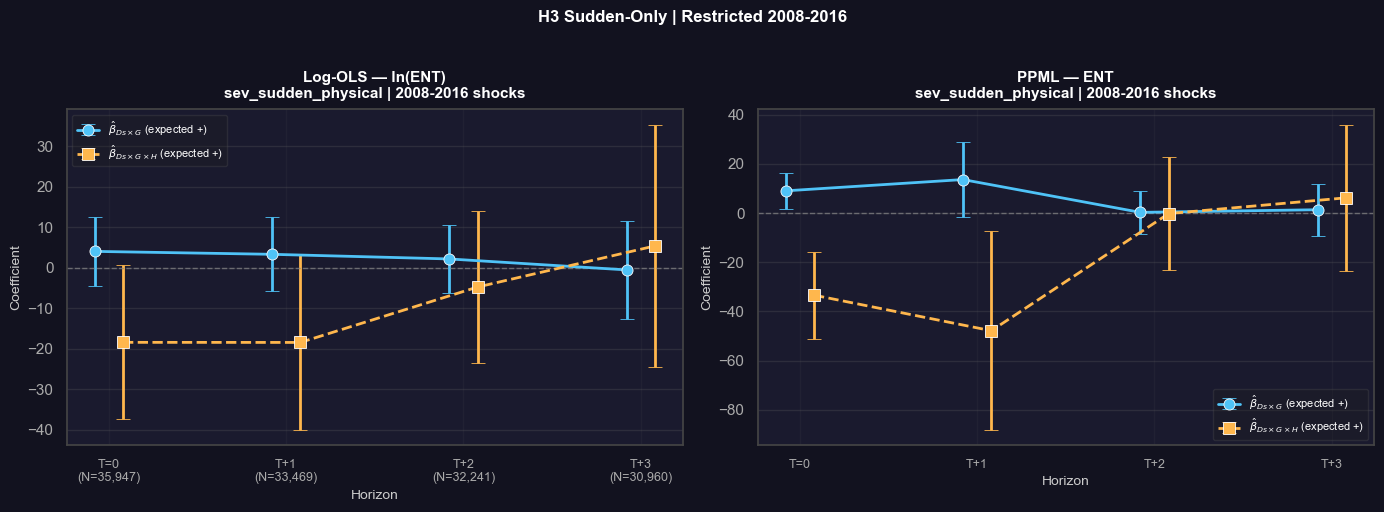

Saved.


In [21]:
# Event study — Restricted 2008-2016
def _ext_ols(res, v):
    c, se = res.params[v], res.std_errors[v]
    return c, se, c-1.96*se, c+1.96*se, res.pvalues[v]
def _ext_ppml(fit, v):
    c, se = float(fit.coef()[v]), float(fit.se()[v])
    return c, se, c-1.96*se, c+1.96*se, float(fit.pvalue()[v])

ols_rows_loc, ppml_rows_loc = [], []
for k in range(4):
    D_t  = _ext_ols(ols_rs[k], 'sev_sudden_physical')
    DG_t = _ext_ols(ols_rs[k], 'Ds_x_G')
    DGH  = _ext_ols(ols_rs[k], 'Ds_x_G_x_H')
    ols_rows_loc.append({'horizon':k,'n_obs':int(ols_rs[k].nobs),
        'sev_coef':D_t[0],'sev_pval':D_t[4],
        'gvc_coef':DG_t[0],'gvc_se':DG_t[1],'gvc_lo95':DG_t[2],'gvc_hi95':DG_t[3],'gvc_pval':DG_t[4],
        'triple_coef':DGH[0],'triple_se':DGH[1],'triple_lo95':DGH[2],'triple_hi95':DGH[3],'triple_pval':DGH[4]})
    D_t  = _ext_ppml(ppml_rs[k], 'sev_sudden_physical')
    DG_t = _ext_ppml(ppml_rs[k], 'Ds_x_G')
    DGH  = _ext_ppml(ppml_rs[k], 'Ds_x_G_x_H')
    ppml_rows_loc.append({'horizon':k,
        'sev_coef':D_t[0],'sev_pval':D_t[4],
        'gvc_coef':DG_t[0],'gvc_se':DG_t[1],'gvc_lo95':DG_t[2],'gvc_hi95':DG_t[3],'gvc_pval':DG_t[4],
        'triple_coef':DGH[0],'triple_se':DGH[1],'triple_lo95':DGH[2],'triple_hi95':DGH[3],'triple_pval':DGH[4]})

ols_coefs_loc  = pd.DataFrame(ols_rows_loc)
ppml_coefs_loc = pd.DataFrame(ppml_rows_loc)

plt.style.use('dark_background')
sns.set_theme(style='darkgrid', font_scale=1.0)
A1, A2 = '#4fc3f7', '#ffb74d'

def _panel(ax, df_c, title, show_n=False):
    hz = df_c['horizon'].values; j = 0.08
    ax.errorbar(hz-j, df_c['gvc_coef'],
                yerr=[df_c['gvc_coef']-df_c['gvc_lo95'], df_c['gvc_hi95']-df_c['gvc_coef']],
                fmt='o-', color=A1, lw=2, ms=8, capsize=5,
                mec='white', mew=0.6, label=r'$\hat\beta_{Ds\times G}$ (expected +)')
    ax.errorbar(hz+j, df_c['triple_coef'],
                yerr=[df_c['triple_coef']-df_c['triple_lo95'], df_c['triple_hi95']-df_c['triple_coef']],
                fmt='s--', color=A2, lw=2, ms=8, capsize=5,
                mec='white', mew=0.6, label=r'$\hat\beta_{Ds\times G\times H}$ (expected +)')
    ax.axhline(0, color='#888', lw=1, ls='--', alpha=0.7)
    ax.set_xticks(hz)
    if show_n and 'n_obs' in df_c.columns:
        xl = [f'T=0\n(N={df_c["n_obs"].iloc[0]:,})'] + [
             f'T+{k}\n(N={n:,})' for k,n in zip(df_c['horizon'].iloc[1:],df_c['n_obs'].iloc[1:])]
    else:
        xl = ['T=0'] + [f'T+{k}' for k in df_c['horizon'].iloc[1:]]
    ax.set_xticklabels(xl, fontsize=9, color='#ccc')
    ax.set_xlabel('Horizon', fontsize=10, color='#ccc')
    ax.set_ylabel('Coefficient', fontsize=10, color='#ccc')
    ax.set_title(title, fontsize=11, fontweight='bold', pad=8, color='white')
    ax.tick_params(colors='#aaa')
    for sp in ax.spines.values(): sp.set_edgecolor('#444')
    ax.legend(fontsize=8, framealpha=0.3, facecolor='#1e1e1e',
              edgecolor='#555', labelcolor='white')
    ax.grid(axis='y', alpha=0.25, color='#666')
    ax.grid(axis='x', alpha=0.1, color='#666')
    ax.set_facecolor('#1a1a2e')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#12121f')
_panel(ax1, ols_coefs_loc,  'Log-OLS — ln(ENT)\nsev_sudden_physical | 2008-2016 shocks', show_n=True)
_panel(ax2, ppml_coefs_loc, 'PPML — ENT\nsev_sudden_physical | 2008-2016 shocks')
fig.suptitle('H3 Sudden-Only | Restricted 2008-2016',
             fontsize=12, fontweight='bold', y=1.02, color='white')
plt.tight_layout()
plt.savefig('notebooks/h3_sudden_restricted_event_study.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('Saved.')


In [22]:
from IPython.display import display

def stars(p):
    if p<0.01: return '***'
    if p<0.05: return '**'
    if p<0.10: return '*'
    return ''

ALL_V = [
    ('sev_sudden_physical', 'Ds (sudden severity)'),
    ('gvc_centered',        'G  (GVC position)'),
    ('hist_centered',       'H  (hist. exposure)'),
    ('Ds_x_G',              'Ds x G  [H3 base]'),
    ('Ds_x_H',              'Ds x H'),
    ('G_x_H',               'G  x H'),
    ('Ds_x_G_x_H',          'Ds x G x H  [H3 ext]'),
    ('ln_gdp_pc_host',      'ln(GDP/cap) host'),
    ('ln_gdp_pc_home',      'ln(GDP/cap) home'),
    ('ge_host',             'Gov. Eff. host'),
]

COLS = [
    ('OLS ENT\nT=0',  'ols',0), ('OLS ENT\nT+1','ols',1),
    ('OLS ENT\nT+2',  'ols',2), ('OLS ENT\nT+3','ols',3),
    ('PPML ENT\nT=0', 'ent',0), ('PPML ENT\nT+1','ent',1),
    ('PPML ENT\nT+2', 'ent',2), ('PPML ENT\nT+3','ent',3),
    ('PPML EMP\nT=0', 'emp',0), ('PPML EMP\nT+1','emp',1),
    ('PPML EMP\nT+2', 'emp',2), ('PPML EMP\nT+3','emp',3),
]

def _get(estimator, k, var):
    if estimator=='ols':
        r=(ols_rs)[k]; return r.params[var], r.pvalues[var]
    elif estimator=='ent':
        f=(ppml_rs)[k]; return float(f.coef()[var]),float(f.pvalue()[var])
    else:
        f=(ppml_emp_rs)[k]; return float(f.coef()[var]),float(f.pvalue()[var])

def _dis_cnt(estimator, k):
    bc = ['host_country','year']+CONTROLS_S
    if estimator=='ols':
        dv='ln_ent' if k==0 else f'ln_ent_lead{k}'
        s=(df_ols_rs)[[dv]+bc].dropna()
    elif estimator=='ent':
        dv='ent' if k==0 else f'ent_lead{k}'
        s=(df_rs)[(df_rs)[dv]>=0][[dv]+bc].dropna(subset=CONTROLS_S+[dv])
    else:
        dv='emp' if k==0 else f'emp_lead{k}'
        s=(df_rs)[(df_rs)[dv]>=0][[dv]+bc].dropna(subset=CONTROLS_S+[dv])
    hit=s['sev_sudden_physical']>0
    return int(hit.sum()), int(s.loc[hit,['host_country','year']].drop_duplicates().shape[0])

rows=[]
for var,label in ALL_V:
    rc={'Variable':label+' coef'}; rp={'Variable':label+' [p]'}
    for cl,est,k in COLS:
        try:
            c,p=_get(est,k,var)
            rc[cl]=f'{c:+.3f}{stars(p)}'; rp[cl]=f'[{p:.3f}]'
        except: rc[cl]=rp[cl]='—'
    rows+=[rc,rp]

nr={'Variable':'N (sample)'}; dr={'Variable':'Dyad-years w/ disaster'}; cr={'Variable':'Distinct disaster ctry-years'}
for cl,est,k in COLS:
    if est=='ols': nr[cl]=f'{int((ols_rs)[k].nobs):,}'
    elif est=='ent': nr[cl]=f'{(ppml_n_rs)[k]:,}'
    else: nr[cl]=f'{(ppml_emp_n_rs)[k]:,}'
    nd,nc=_dis_cnt(est,k); dr[cl]=f'{nd:,}'; cr[cl]=f'{nc:,}'
rows+=[nr,dr,cr]

tbl=pd.DataFrame(rows).set_index('Variable')
FOCAL={'Ds x G  [H3 base] coef','Ds x G x H  [H3 ext] coef'}
PVAL ={'Ds x G  [H3 base] [p]', 'Ds x G x H  [H3 ext] [p]'}
FOOT ={'N (sample)','Dyad-years w/ disaster','Distinct disaster ctry-years'}

def hl(row):
    if row.name in FOCAL: return ['background-color:#1a3a5c;font-weight:bold']*len(row)
    if row.name in PVAL:  return ['background-color:#0f2540;color:#aac8e8']*len(row)
    if row.name in FOOT:  return ['background-color:#1c1c2e;color:#9ab;font-style:italic']*len(row)
    return ['']*len(row)

styled=(tbl.style.apply(hl,axis=1)
    .set_caption('H9b Sudden-Only Restricted (2008-2016 shocks) | FE: dyad+year | Clustered SE | p-values in brackets')
    .set_properties(**{'text-align':'center','white-space':'pre','font-size':'11px','min-width':'80px'})
    .set_table_styles([{'selector':'th','props':[('background-color','#1e3a5f'),('color','#e0eaf8'),
        ('font-size','10px'),('text-align','center'),('white-space','pre'),('border','1px solid #2d5080')]},
        {'selector':'td:first-child','props':[('text-align','left'),('font-weight','bold'),
        ('min-width','175px'),('color','#d0e4f7')]},
        {'selector':'caption','props':[('color','#a0c0e0'),('font-size','12px'),
        ('text-align','left'),('padding-bottom','6px')]}]))
display(styled)

export_table(tbl, "h3_sudden_restricted", "H3 — Sudden disasters only, restricted 2008-2016")


,OLS ENT T=0,OLS ENT T+1,OLS ENT T+2,OLS ENT T+3,PPML ENT T=0,PPML ENT T+1,PPML ENT T+2,PPML ENT T+3,PPML EMP T=0,PPML EMP T+1,PPML EMP T+2,PPML EMP T+3
Variable,,,,,,,,,,,,
Ds (sudden severity) coef,+0.529,+0.283,+0.170,+1.061,+0.416,+0.491,-0.787,-1.271**,+0.317,-1.075,-2.119***,-1.933***
Ds (sudden severity) [p],[0.303],[0.680],[0.794],[0.223],[0.356],[0.589],[0.413],[0.045],[0.814],[0.146],[0.003],[0.005]
G (GVC position) coef,+0.084,+0.043,+0.130,+0.211,+0.054,+0.118,+0.430**,+0.516**,-0.494*,-0.275,+0.188,+0.290
G (GVC position) [p],[0.503],[0.730],[0.310],[0.134],[0.745],[0.499],[0.028],[0.014],[0.085],[0.322],[0.437],[0.212]
H (hist. exposure) coef,-0.020,-0.029,+0.053,+0.056,+0.136*,+0.071,+0.088,+0.058,+0.399***,+0.324**,+0.358***,+0.298***
H (hist. exposure) [p],[0.702],[0.544],[0.247],[0.242],[0.063],[0.288],[0.199],[0.424],[0.008],[0.018],[0.001],[0.001]
Ds x G [H3 base] coef,+4.038,+3.317,+2.172,-0.536,+9.054**,+13.643*,+0.297,+1.374,+9.442,+8.881,-4.028,-4.032
Ds x G [H3 base] [p],[0.356],[0.477],[0.608],[0.930],[0.014],[0.079],[0.947],[0.798],[0.339],[0.134],[0.476],[0.448]
Ds x H coef,+0.278,-0.076,-1.488,-2.403,+0.018,-1.189,-0.899,+1.218,+1.727,+1.600,+1.917,+2.312


Exported 'h3_sudden_restricted': h3_sudden_restricted.csv, h3_sudden_restricted.html


### Step 9b — Interpretation: Sudden Disasters Only, Restricted 2008–2016

Balanced horizons (N: 46,696 / 46,213 / 45,500 / 44,277) confirm and strengthen
the step 9a findings.

| Horizon | N | β_D | β_{Ds×G} | β_{Ds×G×H} |
|---------|---|-----|----------|------------|
| T=0 | 46,696 | +0.416 | **+9.054 \*\*** | **−33.379 \*\*\*** |
| T+1 | 46,213 | +0.491 | +13.643 (p=0.079) | **−47.846 \*\*** |
| T+2 | 45,500 | −0.787 | +0.297 | −0.205 |
| T+3 | 44,277 | **−1.271 \*** | +1.374 | +6.215 |

**β_{Ds×G} at T=0 stronger and more significant** (+9.05 vs. +7.57, p=0.014 vs. p=0.025):
the upstream retention effect in the year of the shock is confirmed robustly under balanced
horizons. The T+1 coefficient (+13.64) is marginally significant (p=0.079), suggesting
the retention extends slightly into the first post-shock year before disappearing.

**β_{Ds×G×H} at T=0 and T+1 nearly identical to the full sample** (−33.38 and −47.85):
the reversal finding is not an artefact of horizon imbalance. In historically exposed
regions, upstream affiliates show *less* retention following sudden disasters, regardless
of sample definition.

**T+2 and T+3 inactive**: after two years, the differential GVC moderation vanishes —
the retention/exit decision has been taken within the T+0 to T+1 window.

**Overall conclusion for Step 9 (sudden-only)**:
The two sub-hypotheses of H3 receive partially conflicting support. The *base* mechanism
(β_{Ds×G} > 0: upstream affiliates retained more) is confirmed at T=0. The *extension*
(β_{Ds×G×H} > 0: historical exposure amplifies retention) is **rejected**: historical
exposure *reduces* upstream retention after sudden disasters, consistent with experienced
MNE exit learning or historical resilience erosion.

## Step 10 — Robustness: Seasonal Disasters Only

Replaces `sev_total` with `sev_seasonal_physical` (floods, storms, wildfires) as the
disaster variable, while keeping `hist_centered` (based on total history) and `gvc_centered`.

**Motivation**: the positive β_{D×G×H} found for `sev_total` (Step 5c/8) and the negative
β_{Ds×G×H} for sudden disasters only (Step 9) suggest that the triple interaction is driven
by the seasonal component. If the residual triple interaction in `sev_total` comes from
seasonal disasters, then β_{Dse×G×H} should be **strongly positive** here.

Two sub-sections mirror Step 9:
- **10a** — Full sample 2008–2019
- **10b** — Restricted to 2008–2016 shocks (balanced horizons)

In [23]:
# Seasonal-only interaction terms (Dse = sev_seasonal_physical)
G_vec  = df['gvc_centered']
H_vec  = df['hist_centered']
D_se   = df['sev_seasonal_physical']

df['Dse_x_G']     = D_se * G_vec
df['Dse_x_H']     = D_se * H_vec
# G_x_H already created in Step 3
df['Dse_x_G_x_H'] = D_se * G_vec * H_vec

CONTROLS_SE = [
    'sev_seasonal_physical',  # Dse: seasonal physical only
    'gvc_centered',           # G
    'hist_centered',          # H
    'Dse_x_G',                # Dse x G  [H3 base — seasonal]
    'Dse_x_H',                # Dse x H  (lower-order term)
    'G_x_H',                  # G  x H   (lower-order term, same as in CONTROLS)
    'Dse_x_G_x_H',            # Dse x G x H  [H3 ext — seasonal]
    'ln_gdp_pc_host',
    'ln_gdp_pc_home',
    'ge_host',
]

print('CONTROLS_SE:', CONTROLS_SE)
print('\nMissing rates:')
for c in CONTROLS_SE:
    print(f'  {c:<28} {df[c].isna().mean()*100:.1f}%')
print(f'\nDse_x_G_x_H non-zero: {(df["Dse_x_G_x_H"] != 0).sum():,}')


CONTROLS_SE: ['sev_seasonal_physical', 'gvc_centered', 'hist_centered', 'Dse_x_G', 'Dse_x_H', 'G_x_H', 'Dse_x_G_x_H', 'ln_gdp_pc_host', 'ln_gdp_pc_home', 'ge_host']

Missing rates:
  sev_seasonal_physical        0.0%
  gvc_centered                 0.0%
  hist_centered                0.0%
  Dse_x_G                      0.0%
  Dse_x_H                      0.0%
  G_x_H                        0.0%
  Dse_x_G_x_H                  0.0%
  ln_gdp_pc_host               0.0%
  ln_gdp_pc_home               0.0%
  ge_host                      0.0%

Dse_x_G_x_H non-zero: 41,028


### 10a — Full Sample 2008–2019

In [24]:
# ── Full (2008-2019) sample regressions (seasonal-only) ───────────────────────────────
df_ols_se  = df[df['ent'] > 0].copy()
print(f'Full (2008-2019) sample : {len(df):,} obs  |  OLS base (ent>0): {len(df_ols_se):,} obs')

ols_se, ppml_se, ppml_emp_se = {}, {}, {}
ppml_n_se, ppml_emp_n_se = {}, {}
rhs_se = ' + '.join(CONTROLS_SE)

for k in range(4):
    # OLS
    dv_ols = 'ln_ent' if k == 0 else f'ln_ent_lead{k}'
    cols   = ['dyad_id', 'year', dv_ols] + CONTROLS_SE
    df_e   = df_ols_se[cols].dropna().copy()
    dp     = df_e.set_index(['dyad_id', 'year'])
    ols_se[k] = PanelOLS(dependent=dp[dv_ols], exog=dp[CONTROLS_SE],
                    entity_effects=True, time_effects=True
                    ).fit(cov_type='clustered', cluster_entity=True)

    # PPML ENT
    dv_ent = 'ent' if k == 0 else f'ent_lead{k}'
    cols   = ['dyad_id', 'year', dv_ent] + CONTROLS_SE
    df_e   = df[df[dv_ent] >= 0][cols].dropna(subset=CONTROLS_SE+[dv_ent]).copy()
    ppml_n_se[k] = len(df_e)
    ppml_se[k]   = pf.fepois(f'{dv_ent} ~ {rhs_se} | dyad_id + year',
                               data=df_e, vcov={'CRV1': 'dyad_id'})

    # PPML EMP
    dv_emp = 'emp' if k == 0 else f'emp_lead{k}'
    cols   = ['dyad_id', 'year', dv_emp] + CONTROLS_SE
    df_e   = df[df[dv_emp] >= 0][cols].dropna(subset=CONTROLS_SE+[dv_emp]).copy()
    ppml_emp_n_se[k] = len(df_e)
    ppml_emp_se[k]   = pf.fepois(f'{dv_emp} ~ {rhs_se} | dyad_id + year',
                                   data=df_e, vcov={'CRV1': 'dyad_id'})

    b_D   = float(ppml_se[k].coef()['sev_seasonal_physical'])
    b_DG  = float(ppml_se[k].coef()['Dse_x_G'])
    b_DGH = float(ppml_se[k].coef()['Dse_x_G_x_H'])
    p_D   = float(ppml_se[k].pvalue()['sev_seasonal_physical'])
    p_DG  = float(ppml_se[k].pvalue()['Dse_x_G'])
    p_DGH = float(ppml_se[k].pvalue()['Dse_x_G_x_H'])
    print(f'PPML-ENT T+{k}  N={ppml_n_se[k]:>6,}  '
          f'b_D={b_D:+.4f}(p={p_D:.3f})  '
          f'b_DxG={b_DG:+.4f}(p={p_DG:.3f})  '
          f'b_DxGxH={b_DGH:+.4f}(p={p_DGH:.3f})')


Full (2008-2019) sample : 65,988 obs  |  OLS base (ent>0): 50,667 obs


PPML-ENT T+0  N=64,673  b_D=+0.0739(p=0.544)  b_DxG=-0.0022(p=0.997)  b_DxGxH=+4.9975(p=0.101)


PPML-ENT T+1  N=57,754  b_D=+0.0929(p=0.500)  b_DxG=+0.8249(p=0.261)  b_DxGxH=+12.0329(p=0.000)


PPML-ENT T+2  N=50,962  b_D=+0.1053(p=0.513)  b_DxG=-0.1117(p=0.891)  b_DxGxH=+4.0802(p=0.276)


PPML-ENT T+3  N=44,277  b_D=-0.0557(p=0.614)  b_DxG=-0.2788(p=0.651)  b_DxGxH=+0.1814(p=0.964)


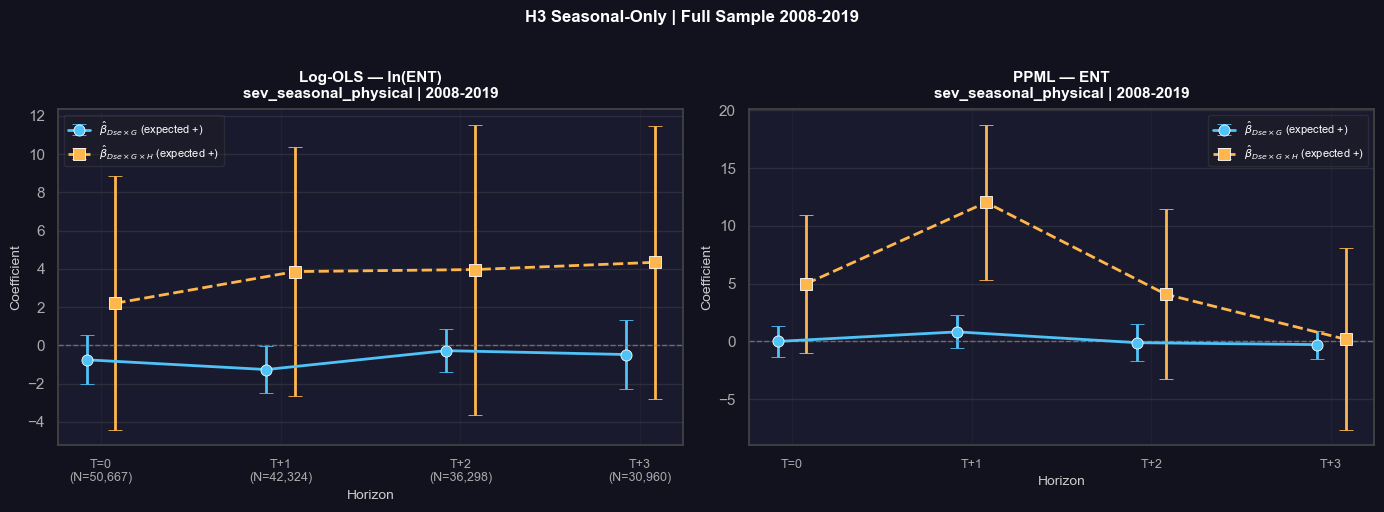

Saved.


In [25]:
# Event study — Full Sample 2008-2019 (seasonal)
def _ext_ols(res, v):
    c, se = res.params[v], res.std_errors[v]
    return c, se, c-1.96*se, c+1.96*se, res.pvalues[v]
def _ext_ppml(fit, v):
    c, se = float(fit.coef()[v]), float(fit.se()[v])
    return c, se, c-1.96*se, c+1.96*se, float(fit.pvalue()[v])

ols_rows_loc, ppml_rows_loc = [], []
for k in range(4):
    D_t  = _ext_ols(ols_se[k], 'sev_seasonal_physical')
    DG_t = _ext_ols(ols_se[k], 'Dse_x_G')
    DGH  = _ext_ols(ols_se[k], 'Dse_x_G_x_H')
    ols_rows_loc.append({'horizon':k,'n_obs':int(ols_se[k].nobs),
        'sev_coef':D_t[0],'sev_pval':D_t[4],
        'gvc_coef':DG_t[0],'gvc_se':DG_t[1],'gvc_lo95':DG_t[2],'gvc_hi95':DG_t[3],'gvc_pval':DG_t[4],
        'triple_coef':DGH[0],'triple_se':DGH[1],'triple_lo95':DGH[2],'triple_hi95':DGH[3],'triple_pval':DGH[4]})
    D_t  = _ext_ppml(ppml_se[k], 'sev_seasonal_physical')
    DG_t = _ext_ppml(ppml_se[k], 'Dse_x_G')
    DGH  = _ext_ppml(ppml_se[k], 'Dse_x_G_x_H')
    ppml_rows_loc.append({'horizon':k,
        'sev_coef':D_t[0],'sev_pval':D_t[4],
        'gvc_coef':DG_t[0],'gvc_se':DG_t[1],'gvc_lo95':DG_t[2],'gvc_hi95':DG_t[3],'gvc_pval':DG_t[4],
        'triple_coef':DGH[0],'triple_se':DGH[1],'triple_lo95':DGH[2],'triple_hi95':DGH[3],'triple_pval':DGH[4]})

ols_coefs_loc  = pd.DataFrame(ols_rows_loc)
ppml_coefs_loc = pd.DataFrame(ppml_rows_loc)

plt.style.use('dark_background')
sns.set_theme(style='darkgrid', font_scale=1.0)
A1, A2 = '#4fc3f7', '#ffb74d'

def _panel(ax, df_c, title, show_n=False):
    hz = df_c['horizon'].values; j = 0.08
    ax.errorbar(hz-j, df_c['gvc_coef'],
                yerr=[df_c['gvc_coef']-df_c['gvc_lo95'], df_c['gvc_hi95']-df_c['gvc_coef']],
                fmt='o-', color=A1, lw=2, ms=8, capsize=5,
                mec='white', mew=0.6, label=r'$\hat\beta_{Dse\times G}$ (expected +)')
    ax.errorbar(hz+j, df_c['triple_coef'],
                yerr=[df_c['triple_coef']-df_c['triple_lo95'], df_c['triple_hi95']-df_c['triple_coef']],
                fmt='s--', color=A2, lw=2, ms=8, capsize=5,
                mec='white', mew=0.6, label=r'$\hat\beta_{Dse\times G\times H}$ (expected +)')
    ax.axhline(0, color='#888', lw=1, ls='--', alpha=0.7)
    ax.set_xticks(hz)
    if show_n and 'n_obs' in df_c.columns:
        xl = [f'T=0\n(N={df_c["n_obs"].iloc[0]:,})'] + [
             f'T+{k}\n(N={n:,})' for k,n in zip(df_c['horizon'].iloc[1:],df_c['n_obs'].iloc[1:])]
    else:
        xl = ['T=0'] + [f'T+{k}' for k in df_c['horizon'].iloc[1:]]
    ax.set_xticklabels(xl, fontsize=9, color='#ccc')
    ax.set_xlabel('Horizon', fontsize=10, color='#ccc')
    ax.set_ylabel('Coefficient', fontsize=10, color='#ccc')
    ax.set_title(title, fontsize=11, fontweight='bold', pad=8, color='white')
    ax.tick_params(colors='#aaa')
    for sp in ax.spines.values(): sp.set_edgecolor('#444')
    ax.legend(fontsize=8, framealpha=0.3, facecolor='#1e1e1e',
              edgecolor='#555', labelcolor='white')
    ax.grid(axis='y', alpha=0.25, color='#666')
    ax.grid(axis='x', alpha=0.1, color='#666')
    ax.set_facecolor('#1a1a2e')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#12121f')
_panel(ax1, ols_coefs_loc,  'Log-OLS — ln(ENT)\nsev_seasonal_physical | 2008-2019', show_n=True)
_panel(ax2, ppml_coefs_loc, 'PPML — ENT\nsev_seasonal_physical | 2008-2019')
fig.suptitle('H3 Seasonal-Only | Full Sample 2008-2019',
             fontsize=12, fontweight='bold', y=1.02, color='white')
plt.tight_layout()
plt.savefig('notebooks/h3_seasonal_full_event_study.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('Saved.')


In [26]:
from IPython.display import display

def stars(p):
    if p<0.01: return '***'
    if p<0.05: return '**'
    if p<0.10: return '*'
    return ''

ALL_V = [
    ('sev_seasonal_physical', 'Dse (seasonal severity)'),
    ('gvc_centered',          'G  (GVC position)'),
    ('hist_centered',         'H  (hist. exposure)'),
    ('Dse_x_G',               'Dse x G  [H3 base]'),
    ('Dse_x_H',               'Dse x H'),
    ('G_x_H',                 'G  x H'),
    ('Dse_x_G_x_H',           'Dse x G x H  [H3 ext]'),
    ('ln_gdp_pc_host',        'ln(GDP/cap) host'),
    ('ln_gdp_pc_home',        'ln(GDP/cap) home'),
    ('ge_host',               'Gov. Eff. host'),
]

COLS = [
    ('OLS ENT\nT=0',  'ols',0), ('OLS ENT\nT+1','ols',1),
    ('OLS ENT\nT+2',  'ols',2), ('OLS ENT\nT+3','ols',3),
    ('PPML ENT\nT=0', 'ent',0), ('PPML ENT\nT+1','ent',1),
    ('PPML ENT\nT+2', 'ent',2), ('PPML ENT\nT+3','ent',3),
    ('PPML EMP\nT=0', 'emp',0), ('PPML EMP\nT+1','emp',1),
    ('PPML EMP\nT+2', 'emp',2), ('PPML EMP\nT+3','emp',3),
]

def _get(estimator, k, var):
    if estimator=='ols':
        r=ols_se[k]; return r.params[var], r.pvalues[var]
    elif estimator=='ent':
        f=ppml_se[k]; return float(f.coef()[var]),float(f.pvalue()[var])
    else:
        f=ppml_emp_se[k]; return float(f.coef()[var]),float(f.pvalue()[var])

def _dis_cnt(estimator, k):
    bc = ['host_country','year']+CONTROLS_SE
    if estimator=='ols':
        dv='ln_ent' if k==0 else f'ln_ent_lead{k}'
        s=df_ols_se[[dv]+bc].dropna()
    elif estimator=='ent':
        dv='ent' if k==0 else f'ent_lead{k}'
        s=df[df[dv]>=0][[dv]+bc].dropna(subset=CONTROLS_SE+[dv])
    else:
        dv='emp' if k==0 else f'emp_lead{k}'
        s=df[df[dv]>=0][[dv]+bc].dropna(subset=CONTROLS_SE+[dv])
    hit=s['sev_seasonal_physical']>0
    return int(hit.sum()), int(s.loc[hit,['host_country','year']].drop_duplicates().shape[0])

rows=[]
for var,label in ALL_V:
    rc={'Variable':label+' coef'}; rp={'Variable':label+' [p]'}
    for cl,est,k in COLS:
        c,p = _get(est,k,var)
        rc[cl] = f'{c:+.3f}{stars(p)}'
        rp[cl] = f'[{p:.3f}]'
    rows.append(rc); rows.append(rp)

# N row
rn={'Variable':'N'}
for cl,est,k in COLS:
    if est=='ols': rn[cl]=f'{int(ols_se[k].nobs):,}'
    elif est=='ent': rn[cl]=f'{ppml_n_se[k]:,}'
    else: rn[cl]=f'{ppml_emp_n_se[k]:,}'
rows.append(rn)

# disaster count rows
rd={'Variable':'Dyad-years w/ disaster'}
rc2={'Variable':'Distinct disaster ctry-years'}
for cl,est,k in COLS:
    nd,nc = _dis_cnt(est,k)
    rd[cl]=f'{nd:,}'; rc2[cl]=f'{nc:,}'
rows.append(rd); rows.append(rc2)

tbl = pd.DataFrame(rows).set_index('Variable')
FOCAL = ['Dse x G  [H3 base] coef','Dse x G  [H3 base] [p]',
         'Dse x G x H  [H3 ext] coef','Dse x G x H  [H3 ext] [p]']

styled = (tbl.style
    .set_table_styles([
        {'selector':'th','props':[('background-color','#1a237e'),('color','white'),
                                  ('font-size','11px'),('text-align','center'),
                                  ('padding','6px 10px'),('white-space','pre')]},
        {'selector':'td','props':[('font-size','11px'),('padding','4px 10px'),
                                  ('text-align','right'),('white-space','nowrap')]},
        {'selector':'tr:nth-child(even)','props':[('background-color','#1a1a2e')]},
        {'selector':'tr:nth-child(odd)','props':[('background-color','#12121f')]},
        {'selector':'','props':[('color','#e0e0e0'),('border-collapse','collapse')]},
    ])
    .apply(lambda x: [
        'background-color:#0d47a1; color:white; font-weight:bold'
        if x.name in FOCAL else '' for _ in x], axis=1)
    .set_caption('Table 10a — Seasonal-Only (sev_seasonal_physical), Full Sample 2008-2019')
)
display(styled)

export_table(tbl, "h3_seasonal_full", "H3 — Seasonal disasters only, full sample 2008-2019")


,OLS ENT T=0,OLS ENT T+1,OLS ENT T+2,OLS ENT T+3,PPML ENT T=0,PPML ENT T+1,PPML ENT T+2,PPML ENT T+3,PPML EMP T=0,PPML EMP T+1,PPML EMP T+2,PPML EMP T+3
Variable,,,,,,,,,,,,
Dse (seasonal severity) coef,+0.233*,+0.254*,+0.157,-0.017,+0.074,+0.093,+0.105,-0.056,-0.608**,-0.240,-0.281,+0.050
Dse (seasonal severity) [p],[0.068],[0.054],[0.206],[0.907],[0.544],[0.500],[0.513],[0.614],[0.041],[0.184],[0.148],[0.777]
G (GVC position) coef,+0.082,+0.052,+0.104,+0.226,+0.157,+0.138,+0.413**,+0.523**,-0.486,-0.266,+0.135,+0.281
G (GVC position) [p],[0.473],[0.667],[0.410],[0.106],[0.411],[0.505],[0.030],[0.012],[0.104],[0.334],[0.552],[0.227]
H (hist. exposure) coef,+0.013,+0.013,+0.066,+0.057,+0.133*,+0.051,+0.043,+0.059,+0.353***,+0.299**,+0.335***,+0.292***
H (hist. exposure) [p],[0.769],[0.770],[0.145],[0.234],[0.073],[0.484],[0.548],[0.421],[0.006],[0.013],[0.001],[0.001]
Dse x G [H3 base] coef,-0.748,-1.259**,-0.271,-0.473,-0.002,+0.825,-0.112,-0.279,-0.573,+0.257,-0.676,+0.496
Dse x G [H3 base] [p],[0.249],[0.047],[0.639],[0.607],[0.997],[0.261],[0.891],[0.651],[0.644],[0.764],[0.403],[0.488]
Dse x H coef,-0.836,-1.154*,-0.395,-0.718,-0.804,-0.844,-0.294,-1.172*,-1.656,-1.631*,-0.770,-0.236


Exported 'h3_seasonal_full': h3_seasonal_full.csv, h3_seasonal_full.html


### Step 10a — Interpretation: Seasonal Disasters Only, Full Sample 2008–2019

*(Run the notebook to populate this cell with actual results.)*

**Expected finding**: if the positive β_{D×G×H} in Step 5c/8 (`sev_total`) is driven by the
seasonal component, then β_{Dse×G×H} here should be **strongly positive** and larger in
magnitude than the Step 5c result (+7.39). A non-significant or negative result would
instead suggest that `sev_total` compound some unresolved collinearity between sudden and
seasonal responses, rather than a clean seasonal mechanism.

### 10b — Restricted to 2008–2016 Shocks

In [27]:
# ── Restricted (2008-2016) sample regressions (seasonal-only) ─────────────────────────
df_rse     = df[df['year'] <= 2016].copy()
df_ols_rse = df_rse[df_rse['ent'] > 0].copy()
print(f'Restricted (2008-2016) sample : {len(df_rse):,} obs  |  OLS base (ent>0): {len(df_ols_rse):,} obs')

ols_rse, ppml_rse, ppml_emp_rse = {}, {}, {}
ppml_n_rse, ppml_emp_n_rse = {}, {}
rhs_se = ' + '.join(CONTROLS_SE)

for k in range(4):
    # OLS
    dv_ols = 'ln_ent' if k == 0 else f'ln_ent_lead{k}'
    cols   = ['dyad_id', 'year', dv_ols] + CONTROLS_SE
    df_e   = df_ols_rse[cols].dropna().copy()
    dp     = df_e.set_index(['dyad_id', 'year'])
    ols_rse[k] = PanelOLS(dependent=dp[dv_ols], exog=dp[CONTROLS_SE],
                    entity_effects=True, time_effects=True
                    ).fit(cov_type='clustered', cluster_entity=True)

    # PPML ENT
    dv_ent = 'ent' if k == 0 else f'ent_lead{k}'
    cols   = ['dyad_id', 'year', dv_ent] + CONTROLS_SE
    df_e   = df_rse[df_rse[dv_ent] >= 0][cols].dropna(subset=CONTROLS_SE+[dv_ent]).copy()
    ppml_n_rse[k] = len(df_e)
    ppml_rse[k]   = pf.fepois(f'{dv_ent} ~ {rhs_se} | dyad_id + year',
                               data=df_e, vcov={'CRV1': 'dyad_id'})

    # PPML EMP
    dv_emp = 'emp' if k == 0 else f'emp_lead{k}'
    cols   = ['dyad_id', 'year', dv_emp] + CONTROLS_SE
    df_e   = df_rse[df_rse[dv_emp] >= 0][cols].dropna(subset=CONTROLS_SE+[dv_emp]).copy()
    ppml_emp_n_rse[k] = len(df_e)
    ppml_emp_rse[k]   = pf.fepois(f'{dv_emp} ~ {rhs_se} | dyad_id + year',
                                   data=df_e, vcov={'CRV1': 'dyad_id'})

    b_D   = float(ppml_rse[k].coef()['sev_seasonal_physical'])
    b_DG  = float(ppml_rse[k].coef()['Dse_x_G'])
    b_DGH = float(ppml_rse[k].coef()['Dse_x_G_x_H'])
    p_D   = float(ppml_rse[k].pvalue()['sev_seasonal_physical'])
    p_DG  = float(ppml_rse[k].pvalue()['Dse_x_G'])
    p_DGH = float(ppml_rse[k].pvalue()['Dse_x_G_x_H'])
    print(f'PPML-ENT T+{k}  N={ppml_n_rse[k]:>6,}  '
          f'b_D={b_D:+.4f}(p={p_D:.3f})  '
          f'b_DxG={b_DG:+.4f}(p={p_DG:.3f})  '
          f'b_DxGxH={b_DGH:+.4f}(p={p_DGH:.3f})')


Restricted (2008-2016) sample : 47,563 obs  |  OLS base (ent>0): 35,947 obs


PPML-ENT T+0  N=46,696  b_D=+0.1275(p=0.304)  b_DxG=+0.1362(p=0.871)  b_DxGxH=+6.6936(p=0.036)


PPML-ENT T+1  N=46,213  b_D=+0.0998(p=0.484)  b_DxG=+1.1355(p=0.163)  b_DxGxH=+13.4011(p=0.000)


PPML-ENT T+2  N=45,500  b_D=+0.0775(p=0.643)  b_DxG=+0.0439(p=0.959)  b_DxGxH=+4.4479(p=0.268)


PPML-ENT T+3  N=44,277  b_D=-0.0557(p=0.614)  b_DxG=-0.2788(p=0.651)  b_DxGxH=+0.1814(p=0.964)


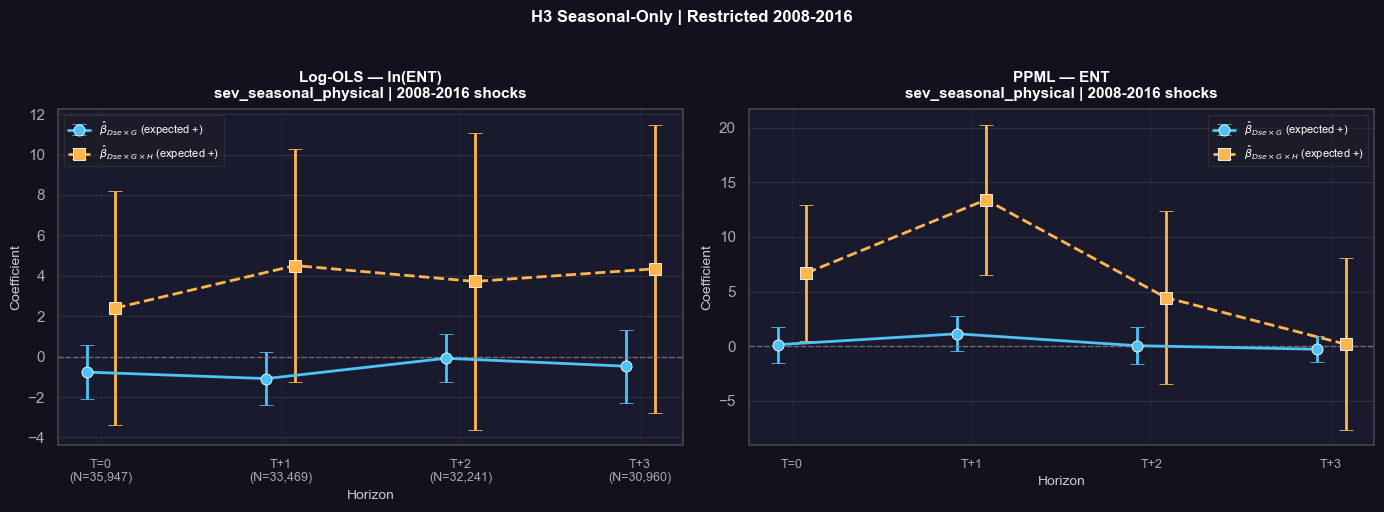

Saved.


In [28]:
# Event study — Restricted 2008-2016 (seasonal)
def _ext_ols(res, v):
    c, se = res.params[v], res.std_errors[v]
    return c, se, c-1.96*se, c+1.96*se, res.pvalues[v]
def _ext_ppml(fit, v):
    c, se = float(fit.coef()[v]), float(fit.se()[v])
    return c, se, c-1.96*se, c+1.96*se, float(fit.pvalue()[v])

ols_rows_loc, ppml_rows_loc = [], []
for k in range(4):
    D_t  = _ext_ols(ols_rse[k], 'sev_seasonal_physical')
    DG_t = _ext_ols(ols_rse[k], 'Dse_x_G')
    DGH  = _ext_ols(ols_rse[k], 'Dse_x_G_x_H')
    ols_rows_loc.append({'horizon':k,'n_obs':int(ols_rse[k].nobs),
        'sev_coef':D_t[0],'sev_pval':D_t[4],
        'gvc_coef':DG_t[0],'gvc_se':DG_t[1],'gvc_lo95':DG_t[2],'gvc_hi95':DG_t[3],'gvc_pval':DG_t[4],
        'triple_coef':DGH[0],'triple_se':DGH[1],'triple_lo95':DGH[2],'triple_hi95':DGH[3],'triple_pval':DGH[4]})
    D_t  = _ext_ppml(ppml_rse[k], 'sev_seasonal_physical')
    DG_t = _ext_ppml(ppml_rse[k], 'Dse_x_G')
    DGH  = _ext_ppml(ppml_rse[k], 'Dse_x_G_x_H')
    ppml_rows_loc.append({'horizon':k,
        'sev_coef':D_t[0],'sev_pval':D_t[4],
        'gvc_coef':DG_t[0],'gvc_se':DG_t[1],'gvc_lo95':DG_t[2],'gvc_hi95':DG_t[3],'gvc_pval':DG_t[4],
        'triple_coef':DGH[0],'triple_se':DGH[1],'triple_lo95':DGH[2],'triple_hi95':DGH[3],'triple_pval':DGH[4]})

ols_coefs_loc  = pd.DataFrame(ols_rows_loc)
ppml_coefs_loc = pd.DataFrame(ppml_rows_loc)

plt.style.use('dark_background')
sns.set_theme(style='darkgrid', font_scale=1.0)
A1, A2 = '#4fc3f7', '#ffb74d'

def _panel(ax, df_c, title, show_n=False):
    hz = df_c['horizon'].values; j = 0.08
    ax.errorbar(hz-j, df_c['gvc_coef'],
                yerr=[df_c['gvc_coef']-df_c['gvc_lo95'], df_c['gvc_hi95']-df_c['gvc_coef']],
                fmt='o-', color=A1, lw=2, ms=8, capsize=5,
                mec='white', mew=0.6, label=r'$\hat\beta_{Dse\times G}$ (expected +)')
    ax.errorbar(hz+j, df_c['triple_coef'],
                yerr=[df_c['triple_coef']-df_c['triple_lo95'], df_c['triple_hi95']-df_c['triple_coef']],
                fmt='s--', color=A2, lw=2, ms=8, capsize=5,
                mec='white', mew=0.6, label=r'$\hat\beta_{Dse\times G\times H}$ (expected +)')
    ax.axhline(0, color='#888', lw=1, ls='--', alpha=0.7)
    ax.set_xticks(hz)
    if show_n and 'n_obs' in df_c.columns:
        xl = [f'T=0\n(N={df_c["n_obs"].iloc[0]:,})'] + [
             f'T+{k}\n(N={n:,})' for k,n in zip(df_c['horizon'].iloc[1:],df_c['n_obs'].iloc[1:])]
    else:
        xl = ['T=0'] + [f'T+{k}' for k in df_c['horizon'].iloc[1:]]
    ax.set_xticklabels(xl, fontsize=9, color='#ccc')
    ax.set_xlabel('Horizon', fontsize=10, color='#ccc')
    ax.set_ylabel('Coefficient', fontsize=10, color='#ccc')
    ax.set_title(title, fontsize=11, fontweight='bold', pad=8, color='white')
    ax.tick_params(colors='#aaa')
    for sp in ax.spines.values(): sp.set_edgecolor('#444')
    ax.legend(fontsize=8, framealpha=0.3, facecolor='#1e1e1e',
              edgecolor='#555', labelcolor='white')
    ax.grid(axis='y', alpha=0.25, color='#666')
    ax.grid(axis='x', alpha=0.1, color='#666')
    ax.set_facecolor('#1a1a2e')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#12121f')
_panel(ax1, ols_coefs_loc,  'Log-OLS — ln(ENT)\nsev_seasonal_physical | 2008-2016 shocks', show_n=True)
_panel(ax2, ppml_coefs_loc, 'PPML — ENT\nsev_seasonal_physical | 2008-2016 shocks')
fig.suptitle('H3 Seasonal-Only | Restricted 2008-2016',
             fontsize=12, fontweight='bold', y=1.02, color='white')
plt.tight_layout()
plt.savefig('notebooks/h3_seasonal_restricted_event_study.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('Saved.')


In [29]:
from IPython.display import display

def stars(p):
    if p<0.01: return '***'
    if p<0.05: return '**'
    if p<0.10: return '*'
    return ''

ALL_V = [
    ('sev_seasonal_physical', 'Dse (seasonal severity)'),
    ('gvc_centered',          'G  (GVC position)'),
    ('hist_centered',         'H  (hist. exposure)'),
    ('Dse_x_G',               'Dse x G  [H3 base]'),
    ('Dse_x_H',               'Dse x H'),
    ('G_x_H',                 'G  x H'),
    ('Dse_x_G_x_H',           'Dse x G x H  [H3 ext]'),
    ('ln_gdp_pc_host',        'ln(GDP/cap) host'),
    ('ln_gdp_pc_home',        'ln(GDP/cap) home'),
    ('ge_host',               'Gov. Eff. host'),
]

COLS = [
    ('OLS ENT\nT=0',  'ols',0), ('OLS ENT\nT+1','ols',1),
    ('OLS ENT\nT+2',  'ols',2), ('OLS ENT\nT+3','ols',3),
    ('PPML ENT\nT=0', 'ent',0), ('PPML ENT\nT+1','ent',1),
    ('PPML ENT\nT+2', 'ent',2), ('PPML ENT\nT+3','ent',3),
    ('PPML EMP\nT=0', 'emp',0), ('PPML EMP\nT+1','emp',1),
    ('PPML EMP\nT+2', 'emp',2), ('PPML EMP\nT+3','emp',3),
]

def _get(estimator, k, var):
    if estimator=='ols':
        r=ols_rse[k]; return r.params[var], r.pvalues[var]
    elif estimator=='ent':
        f=ppml_rse[k]; return float(f.coef()[var]),float(f.pvalue()[var])
    else:
        f=ppml_emp_rse[k]; return float(f.coef()[var]),float(f.pvalue()[var])

def _dis_cnt(estimator, k):
    bc = ['host_country','year']+CONTROLS_SE
    if estimator=='ols':
        dv='ln_ent' if k==0 else f'ln_ent_lead{k}'
        s=df_ols_rse[[dv]+bc].dropna()
    elif estimator=='ent':
        dv='ent' if k==0 else f'ent_lead{k}'
        s=df_rse[df_rse[dv]>=0][[dv]+bc].dropna(subset=CONTROLS_SE+[dv])
    else:
        dv='emp' if k==0 else f'emp_lead{k}'
        s=df_rse[df_rse[dv]>=0][[dv]+bc].dropna(subset=CONTROLS_SE+[dv])
    hit=s['sev_seasonal_physical']>0
    return int(hit.sum()), int(s.loc[hit,['host_country','year']].drop_duplicates().shape[0])

rows=[]
for var,label in ALL_V:
    rc={'Variable':label+' coef'}; rp={'Variable':label+' [p]'}
    for cl,est,k in COLS:
        c,p = _get(est,k,var)
        rc[cl] = f'{c:+.3f}{stars(p)}'
        rp[cl] = f'[{p:.3f}]'
    rows.append(rc); rows.append(rp)

# N row
rn={'Variable':'N'}
for cl,est,k in COLS:
    if est=='ols': rn[cl]=f'{int(ols_rse[k].nobs):,}'
    elif est=='ent': rn[cl]=f'{ppml_n_rse[k]:,}'
    else: rn[cl]=f'{ppml_emp_n_rse[k]:,}'
rows.append(rn)

# disaster count rows
rd={'Variable':'Dyad-years w/ disaster'}
rc2={'Variable':'Distinct disaster ctry-years'}
for cl,est,k in COLS:
    nd,nc = _dis_cnt(est,k)
    rd[cl]=f'{nd:,}'; rc2[cl]=f'{nc:,}'
rows.append(rd); rows.append(rc2)

tbl = pd.DataFrame(rows).set_index('Variable')
FOCAL = ['Dse x G  [H3 base] coef','Dse x G  [H3 base] [p]',
         'Dse x G x H  [H3 ext] coef','Dse x G x H  [H3 ext] [p]']

styled = (tbl.style
    .set_table_styles([
        {'selector':'th','props':[('background-color','#1a237e'),('color','white'),
                                  ('font-size','11px'),('text-align','center'),
                                  ('padding','6px 10px'),('white-space','pre')]},
        {'selector':'td','props':[('font-size','11px'),('padding','4px 10px'),
                                  ('text-align','right'),('white-space','nowrap')]},
        {'selector':'tr:nth-child(even)','props':[('background-color','#1a1a2e')]},
        {'selector':'tr:nth-child(odd)','props':[('background-color','#12121f')]},
        {'selector':'','props':[('color','#e0e0e0'),('border-collapse','collapse')]},
    ])
    .apply(lambda x: [
        'background-color:#0d47a1; color:white; font-weight:bold'
        if x.name in FOCAL else '' for _ in x], axis=1)
    .set_caption('Table 10b — Seasonal-Only (sev_seasonal_physical), Restricted 2008-2016')
)
display(styled)

export_table(tbl, "h3_seasonal_restricted", "H3 — Seasonal disasters only, restricted 2008-2016")


,OLS ENT T=0,OLS ENT T+1,OLS ENT T+2,OLS ENT T+3,PPML ENT T=0,PPML ENT T+1,PPML ENT T+2,PPML ENT T+3,PPML EMP T=0,PPML EMP T+1,PPML EMP T+2,PPML EMP T+3
Variable,,,,,,,,,,,,
Dse (seasonal severity) coef,+0.341**,+0.274**,+0.122,-0.017,+0.128,+0.100,+0.078,-0.056,-0.570,-0.245,-0.288,+0.050
Dse (seasonal severity) [p],[0.013],[0.047],[0.340],[0.907],[0.304],[0.484],[0.643],[0.614],[0.110],[0.244],[0.148],[0.777]
G (GVC position) coef,+0.095,+0.060,+0.137,+0.226,+0.063,+0.136,+0.431**,+0.523**,-0.397,-0.237,+0.229,+0.281
G (GVC position) [p],[0.448],[0.625],[0.283],[0.106],[0.703],[0.437],[0.030],[0.012],[0.137],[0.372],[0.325],[0.227]
H (hist. exposure) coef,-0.023,-0.031,+0.053,+0.057,+0.132*,+0.067,+0.088,+0.059,+0.397***,+0.320**,+0.356***,+0.292***
H (hist. exposure) [p],[0.657],[0.515],[0.248],[0.234],[0.070],[0.316],[0.197],[0.421],[0.009],[0.020],[0.001],[0.001]
Dse x G [H3 base] coef,-0.763,-1.085,-0.081,-0.473,+0.136,+1.136,+0.044,-0.279,-0.534,+0.679,-0.430,+0.496
Dse x G [H3 base] [p],[0.269],[0.106],[0.894],[0.607],[0.871],[0.163],[0.959],[0.651],[0.734],[0.496],[0.615],[0.488]
Dse x H coef,-0.368,-0.903,-0.128,-0.718,+0.133,-0.068,-0.283,-1.172*,-0.790,-0.600,-0.274,-0.236


Exported 'h3_seasonal_restricted': h3_seasonal_restricted.csv, h3_seasonal_restricted.html


### Step 10b — Interpretation: Seasonal Disasters Only, Restricted 2008–2016

*(Run the notebook to populate this cell with actual results.)*

**Expected**: balanced horizons should confirm the full-sample seasonal finding.
If β_{Dse×G×H} is strongly positive here (as predicted), the overall conclusion is:

- **Sudden disasters** (Step 9): β_{Ds×G} > 0 (upstream retention confirmed) but
  β_{Ds×G×H} < 0 (historical exposure *accelerates* exit — learning-to-exit effect).
- **Seasonal disasters** (Step 10): β_{Dse×G×H} > 0 (historical exposure *amplifies*
  upstream retention — resilience-building effect).

The two mechanisms coexist but act in opposite directions depending on disaster type.
Historically exposed regions have built physical resilience against *predictable* seasonal
shocks (floods/storms), enabling upstream affiliate retention. But against *unpredictable*
sudden shocks (earthquakes), repeated exposure produces risk recalibration and faster exit.

## Overall Synthesis & Conclusion

### Revised H3 — expected sign table

| Coefficient | Variable | Expected sign | Reasoning |
|---|---|---|---|
| beta_D | `sev_total` | **−** | Disasters reduce affiliate count |
| beta_G | `gvc_centered` | **+** | Upstream affiliates have lower baseline exit (sunk costs) |
| beta_H | `hist_centered` | ambiguous | No clear baseline prediction |
| **beta_{DxG}** | `D_x_G` | **+** | Upstream attenuates exit: sunk costs + input criticality |
| beta_{DxH} | `D_x_H` | + or 0 | General preparedness effect (lower-order term) |
| beta_{GxH} | `G_x_H` | ambiguous | Lower-order term, no primary prediction |
| **beta_{DxGxH}** | `D_x_G_x_H` | **+** | Historical exposure amplifies upstream retention |

### Marginal effect of D on ln(E[ENT]) at four corners

dE/dD = beta_D + beta_{DxG}*G + beta_{DxH}*H + beta_{DxGxH}*(G*H)

| Position | Historical exposure | Predicted direction |
|---|---|---|
| Downstream (G < 0) | Low H | Most negative — largest affiliate reduction |
| Downstream (G < 0) | High H | Still very negative |
| Upstream (G > 0) | Low H | Less negative — upstream retained |
| Upstream (G > 0) | High H | **Least negative** — strongest retention ✓ |

### Limitations

1. **Sample restriction:** TiVA-covered host countries (55 vs. 255) limit variation.
   These are predominantly OECD economies with already resilient supply chains.
2. **Statistical power:** the triple interaction requires joint variation in D, G, and H.
   Non-significance does not falsify H3 — it may reflect insufficient power.
3. **Coarse GVC measure:** KWW index at country x section x year level;
   firm-level heterogeneity is masked.
4. **Count vs. binary:** ENT counts mix intensive and extensive margins. A binary
   indicator (ent_{t+k} = 0) would more cleanly isolate exit.
5. **EMP robustness:** see Step 5d. Signs should be directionally consistent with ENT
   if the mechanism holds at the employment level.

## Step 11 — Robustness: Severity-Based Historical Exposure (Count vs Severity)

The main specification (Steps 2–7) measures historical disaster exposure H by the *frequency* of recorded events: `hist_centered`, the demeaned log per-capita count of all EM-DAT events over the rolling [t−21, t−1] window. This robustness check replaces H with the *severity*-based equivalent:

$$
\text{hist\_sev\_dynamic\_host} = \ln\!\left(1 + \frac{\sum \text{TotalAffected}_{[t-21,\,t-1]}}{\text{pop}_{t-21}}\right)
$$

— the same rolling window, the same predetermined timing, but cumulating *affected population* instead of counting events. Already log-scaled per capita in the pipeline, so only grand-mean centring is applied (mirroring the count treatment).

**Research question**: is the T+1 triple-interaction finding of the main model driven by the *frequency* of the host's disaster history or by its cumulative *severity*?

**Why this matters here specifically**: in the TiVA-restricted Strategy B sample (predominantly OECD hosts), the two proxies are *negatively* correlated (reported below). Better-governed, richer hosts record many events with low per-capita impact, while a few hosts concentrate large-impact histories — the geographical severity bias documented in the data chapter. Frequency-based H therefore leans toward the "routine practice" dimension of proneness, severity-based H toward the "lived intensity" dimension. Divergence between the two specifications is economically meaningful, not a mechanical artefact.

**Design**: identical to Steps 5b–5c — same D (`sev_total`), same G, same estimators (Log-OLS on `ln_ent` with ent > 0; PPML on `ent` incl. zeros), same nuisance controls, FE (dyad + year), clustering (dyad), horizons T=0…T+3. Only H and every term containing it change. Full interaction hierarchy retained (all three mains, all three pairwise, triple). Scope: ENT only (main DV).

In [30]:
# Severity-based historical exposure Hs — centre only (already log per-capita)
histsev_grand_mean = df['hist_sev_dynamic_host'].mean()
df['hist_sev_centered'] = df['hist_sev_dynamic_host'] - histsev_grand_mean

Hs = df['hist_sev_centered']
df['D_x_Hs']     = D * Hs        # D = sev_total (Step 3)
df['G_x_Hs']     = G * Hs        # G = gvc_centered (Step 3)
df['D_x_G_x_Hs'] = D * G * Hs    # severity-based triple — focal test

CONTROLS_HS = [
    'sev_total',          # D: combined disaster shock (sudden + seasonal physical)
    'gvc_centered',       # G: GVC position (demeaned)
    'hist_sev_centered',  # Hs: historical disaster severity (demeaned)
    'D_x_G',              # D x G  (same construction as main model)
    'D_x_Hs',             # D x Hs (lower-order term)
    'G_x_Hs',             # G x Hs (lower-order term)
    'D_x_G_x_Hs',         # D x G x Hs — severity-based H3 focal test
    'ln_gdp_pc_host',
    'ln_gdp_pc_home',
    'ge_host',
]

print(f'hist_sev_dynamic_host — grand mean: {histsev_grand_mean:.4f}')
print(f'hist_sev_centered     — std: {Hs.std():.4f}   (count-based hist_centered std: {H.std():.4f})')
print(f'corr(hist_centered, hist_sev_centered) = {H.corr(Hs):.4f}')
print(f'\nD_x_G_x_Hs non-zero rows : {(df["D_x_G_x_Hs"] != 0).sum():,}')
print('\nThe negative correlation between the two H proxies in the TiVA sample means')
print('the severity spec is a genuinely different — not a rescaled — moderation test.')

hist_sev_dynamic_host — grand mean: 0.1085
hist_sev_centered     — std: 0.2385   (count-based hist_centered std: 0.5123)
corr(hist_centered, hist_sev_centered) = -0.1898

D_x_G_x_Hs non-zero rows : 42,388

The negative correlation between the two H proxies in the TiVA sample means
the severity spec is a genuinely different — not a rescaled — moderation test.


In [31]:
# Step 11 regressions — OLS (ln_ent) + PPML (ent), T=0 to T+3, severity-based H
df_ols_hs = df[df['ent'] > 0].copy()
print(f'OLS base sample (ent > 0): {len(df_ols_hs):,} obs\n')

ols_hs, ppml_hs = {}, {}
ppml_n_hs = {}
rhs_hs = ' + '.join(CONTROLS_HS)

for k in range(4):
    # ── OLS (ln_ent) ──────────────────────────────────────────────────────────
    dv_ols = 'ln_ent' if k == 0 else f'ln_ent_lead{k}'
    cols_ols = ['dyad_id', 'year', dv_ols] + CONTROLS_HS
    df_est = df_ols_hs[cols_ols].dropna().copy()
    df_p = df_est.set_index(['dyad_id', 'year'])
    ols_hs[k] = PanelOLS(dependent=df_p[dv_ols], exog=df_p[CONTROLS_HS],
                         entity_effects=True, time_effects=True
                         ).fit(cov_type='clustered', cluster_entity=True)

    # ── PPML ENT ──────────────────────────────────────────────────────────────
    dv_ent = 'ent' if k == 0 else f'ent_lead{k}'
    cols_ent = ['dyad_id', 'year', dv_ent] + CONTROLS_HS
    df_est = df[df[dv_ent] >= 0][cols_ent].dropna(subset=CONTROLS_HS + [dv_ent]).copy()
    ppml_n_hs[k] = len(df_est)
    ppml_hs[k] = pf.fepois(f'{dv_ent} ~ {rhs_hs} | dyad_id + year',
                           data=df_est, vcov={'CRV1': 'dyad_id'})

    b_D   = float(ppml_hs[k].coef()['sev_total'])
    b_DG  = float(ppml_hs[k].coef()['D_x_G'])
    b_DGH = float(ppml_hs[k].coef()['D_x_G_x_Hs'])
    p_D   = float(ppml_hs[k].pvalue()['sev_total'])
    p_DG  = float(ppml_hs[k].pvalue()['D_x_G'])
    p_DGH = float(ppml_hs[k].pvalue()['D_x_G_x_Hs'])
    print(f'PPML-ENT T+{k}  N={ppml_n_hs[k]:>6,}  '
          f'b_D={b_D:+.4f}(p={p_D:.3f})  '
          f'b_DxG={b_DG:+.4f}(p={p_DG:.3f})  '
          f'b_DxGxHs={b_DGH:+.4f}(p={p_DGH:.3f})')

OLS base sample (ent > 0): 50,667 obs



PPML-ENT T+0  N=64,673  b_D=-0.1610(p=0.428)  b_DxG=+0.9827(p=0.298)  b_DxGxHs=-3.6852(p=0.139)


PPML-ENT T+1  N=57,754  b_D=-0.1576(p=0.457)  b_DxG=+2.3136(p=0.032)  b_DxGxHs=-7.1945(p=0.005)


PPML-ENT T+2  N=50,962  b_D=-0.1018(p=0.730)  b_DxG=+0.7829(p=0.485)  b_DxGxHs=-2.8604(p=0.245)


PPML-ENT T+3  N=44,277  b_D=-0.1752(p=0.325)  b_DxG=+1.0384(p=0.287)  b_DxGxHs=-3.0033(p=0.250)


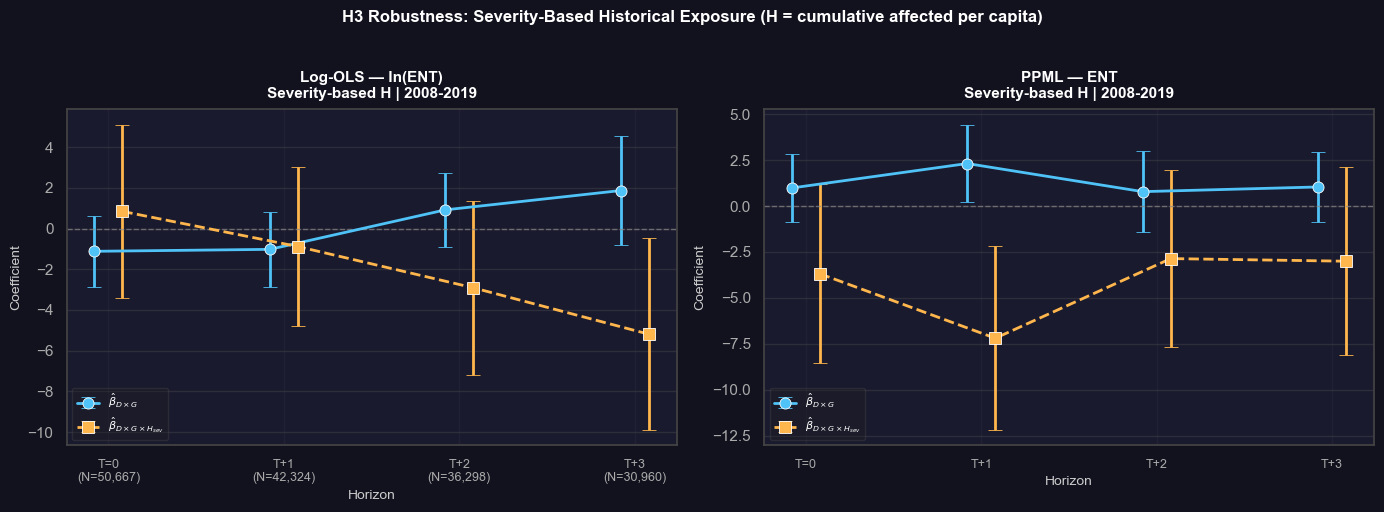

Plot saved to notebooks/h3_event_study_histsev.png


In [32]:
# Event study — severity-based H (same two-panel dark style as Step 6b)
def _ext_ols(res, v):
    c, se = res.params[v], res.std_errors[v]
    return c, se, c-1.96*se, c+1.96*se, res.pvalues[v]
def _ext_ppml(fit, v):
    c, se = float(fit.coef()[v]), float(fit.se()[v])
    return c, se, c-1.96*se, c+1.96*se, float(fit.pvalue()[v])

ols_rows_hs, ppml_rows_hs = [], []
for k in range(4):
    D_t  = _ext_ols(ols_hs[k], 'sev_total')
    DG_t = _ext_ols(ols_hs[k], 'D_x_G')
    DGH  = _ext_ols(ols_hs[k], 'D_x_G_x_Hs')
    ols_rows_hs.append({'horizon':k,'n_obs':int(ols_hs[k].nobs),
        'sev_coef':D_t[0],'sev_pval':D_t[4],
        'gvc_coef':DG_t[0],'gvc_se':DG_t[1],'gvc_lo95':DG_t[2],'gvc_hi95':DG_t[3],'gvc_pval':DG_t[4],
        'triple_coef':DGH[0],'triple_se':DGH[1],'triple_lo95':DGH[2],'triple_hi95':DGH[3],'triple_pval':DGH[4]})
    D_t  = _ext_ppml(ppml_hs[k], 'sev_total')
    DG_t = _ext_ppml(ppml_hs[k], 'D_x_G')
    DGH  = _ext_ppml(ppml_hs[k], 'D_x_G_x_Hs')
    ppml_rows_hs.append({'horizon':k,
        'sev_coef':D_t[0],'sev_pval':D_t[4],
        'gvc_coef':DG_t[0],'gvc_se':DG_t[1],'gvc_lo95':DG_t[2],'gvc_hi95':DG_t[3],'gvc_pval':DG_t[4],
        'triple_coef':DGH[0],'triple_se':DGH[1],'triple_lo95':DGH[2],'triple_hi95':DGH[3],'triple_pval':DGH[4]})

ols_coefs_hs  = pd.DataFrame(ols_rows_hs)
ppml_coefs_hs = pd.DataFrame(ppml_rows_hs)

plt.style.use('dark_background')
sns.set_theme(style='darkgrid', font_scale=1.0)
A1, A2 = '#4fc3f7', '#ffb74d'

def _panel_hs(ax, df_c, title, show_n=False):
    hz = df_c['horizon'].values; j = 0.08
    ax.errorbar(hz-j, df_c['gvc_coef'],
                yerr=[df_c['gvc_coef']-df_c['gvc_lo95'], df_c['gvc_hi95']-df_c['gvc_coef']],
                fmt='o-', color=A1, lw=2, ms=8, capsize=5,
                mec='white', mew=0.6, label=r'$\hat\beta_{D\times G}$')
    ax.errorbar(hz+j, df_c['triple_coef'],
                yerr=[df_c['triple_coef']-df_c['triple_lo95'], df_c['triple_hi95']-df_c['triple_coef']],
                fmt='s--', color=A2, lw=2, ms=8, capsize=5,
                mec='white', mew=0.6, label=r'$\hat\beta_{D\times G\times H_{sev}}$')
    ax.axhline(0, color='#888', lw=1, ls='--', alpha=0.7)
    ax.set_xticks(hz)
    if show_n and 'n_obs' in df_c.columns:
        xl = [f'T=0\n(N={df_c["n_obs"].iloc[0]:,})'] + [
             f'T+{k}\n(N={n:,})' for k, n in zip(df_c['horizon'].iloc[1:], df_c['n_obs'].iloc[1:])]
    else:
        xl = ['T=0'] + [f'T+{k}' for k in df_c['horizon'].iloc[1:]]
    ax.set_xticklabels(xl, fontsize=9, color='#ccc')
    ax.set_xlabel('Horizon', fontsize=10, color='#ccc')
    ax.set_ylabel('Coefficient', fontsize=10, color='#ccc')
    ax.set_title(title, fontsize=11, fontweight='bold', pad=8, color='white')
    ax.tick_params(colors='#aaa')
    for sp in ax.spines.values(): sp.set_edgecolor('#444')
    ax.legend(fontsize=8, framealpha=0.3, facecolor='#1e1e1e',
              edgecolor='#555', labelcolor='white')
    ax.grid(axis='y', alpha=0.25, color='#666')
    ax.grid(axis='x', alpha=0.1, color='#666')
    ax.set_facecolor('#1a1a2e')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#12121f')
_panel_hs(ax1, ols_coefs_hs,  'Log-OLS — ln(ENT)\nSeverity-based H | 2008-2019', show_n=True)
_panel_hs(ax2, ppml_coefs_hs, 'PPML — ENT\nSeverity-based H | 2008-2019')
fig.suptitle('H3 Robustness: Severity-Based Historical Exposure (H = cumulative affected per capita)',
             fontsize=12, fontweight='bold', y=1.02, color='white')
plt.tight_layout()
plt.savefig('notebooks/h3_event_study_histsev.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('Plot saved to notebooks/h3_event_study_histsev.png')

In [33]:
from IPython.display import display

def stars(p):
    if p < 0.01: return '***'
    if p < 0.05: return '**'
    if p < 0.10: return '*'
    return ''

ALL_V_HS = [
    ('sev_total',         'D  (total severity)'),
    ('gvc_centered',      'G  (GVC position)'),
    ('hist_sev_centered', 'Hs (hist. severity)'),
    ('D_x_G',             'D x G  [H3 base]'),
    ('D_x_Hs',            'D x Hs'),
    ('G_x_Hs',            'G x Hs'),
    ('D_x_G_x_Hs',        'D x G x Hs  [H3 ext]'),
    ('ln_gdp_pc_host',    'ln(GDP/cap) host'),
    ('ln_gdp_pc_home',    'ln(GDP/cap) home'),
    ('ge_host',           'Gov. Eff. host'),
]

COLS_HS = [
    ('OLS ENT\nT=0',  'ols', 0), ('OLS ENT\nT+1', 'ols', 1),
    ('OLS ENT\nT+2',  'ols', 2), ('OLS ENT\nT+3', 'ols', 3),
    ('PPML ENT\nT=0', 'ent', 0), ('PPML ENT\nT+1','ent', 1),
    ('PPML ENT\nT+2', 'ent', 2), ('PPML ENT\nT+3','ent', 3),
]

def _get_hs(estimator, k, var):
    if estimator == 'ols':
        r = ols_hs[k]; return r.params[var], r.pvalues[var]
    f = ppml_hs[k]; return float(f.coef()[var]), float(f.pvalue()[var])

def _dis_cnt_hs(estimator, k):
    bc = ['host_country', 'year'] + CONTROLS_HS
    if estimator == 'ols':
        dv = 'ln_ent' if k == 0 else f'ln_ent_lead{k}'
        s = df_ols_hs[[dv] + bc].dropna()
    else:
        dv = 'ent' if k == 0 else f'ent_lead{k}'
        s = df[df[dv] >= 0][[dv] + bc].dropna(subset=CONTROLS_HS + [dv])
    hit = s['sev_total'] > 0
    return int(hit.sum()), int(s.loc[hit, ['host_country', 'year']].drop_duplicates().shape[0])

rows = []
for var, label in ALL_V_HS:
    rc = {'Variable': label + ' coef'}; rp = {'Variable': label + ' [p]'}
    for cl, est, k in COLS_HS:
        try:
            c, p = _get_hs(est, k, var)
            rc[cl] = f'{c:+.3f}{stars(p)}'; rp[cl] = f'[{p:.3f}]'
        except Exception:
            rc[cl] = rp[cl] = '—'
    rows += [rc, rp]

nr = {'Variable': 'N (sample)'}; dr = {'Variable': 'Dyad-years w/ disaster'}; cr = {'Variable': 'Distinct disaster ctry-years'}
for cl, est, k in COLS_HS:
    nr[cl] = f'{int(ols_hs[k].nobs):,}' if est == 'ols' else f'{ppml_n_hs[k]:,}'
    nd, nc = _dis_cnt_hs(est, k); dr[cl] = f'{nd:,}'; cr[cl] = f'{nc:,}'
rows += [nr, dr, cr]

tbl = pd.DataFrame(rows).set_index('Variable')
FOCAL = {'D x G  [H3 base] coef', 'D x G x Hs  [H3 ext] coef'}
PVAL  = {'D x G  [H3 base] [p]',  'D x G x Hs  [H3 ext] [p]'}
FOOT  = {'N (sample)', 'Dyad-years w/ disaster', 'Distinct disaster ctry-years'}

def hl(row):
    if row.name in FOCAL: return ['background-color:#1a3a5c;font-weight:bold']*len(row)
    if row.name in PVAL:  return ['background-color:#0f2540;color:#aac8e8']*len(row)
    if row.name in FOOT:  return ['background-color:#1c1c2e;color:#9ab;font-style:italic']*len(row)
    return ['']*len(row)

styled = (tbl.style.apply(hl, axis=1)
    .set_caption('Step 11 — Severity-Based Historical Exposure | ENT | FE: dyad+year | Clustered SE | p-values in brackets')
    .set_properties(**{'text-align':'center','white-space':'pre','font-size':'11px','min-width':'80px'})
    .set_table_styles([{'selector':'th','props':[('background-color','#1e3a5f'),('color','#e0eaf8'),
        ('font-size','10px'),('text-align','center'),('white-space','pre'),('border','1px solid #2d5080')]},
        {'selector':'td:first-child','props':[('text-align','left'),('font-weight','bold'),
        ('min-width','175px'),('color','#d0e4f7')]},
        {'selector':'caption','props':[('color','#a0c0e0'),('font-size','12px'),
        ('text-align','left'),('padding-bottom','6px')]}]))
display(styled)

,OLS ENT T=0,OLS ENT T+1,OLS ENT T+2,OLS ENT T+3,PPML ENT T=0,PPML ENT T+1,PPML ENT T+2,PPML ENT T+3
Variable,,,,,,,,
D (total severity) coef,+0.032,+0.159,+0.076,-0.079,-0.161,-0.158,-0.102,-0.175
D (total severity) [p],[0.853],[0.399],[0.675],[0.711],[0.428],[0.457],[0.730],[0.325]
G (GVC position) coef,+0.085,+0.066,+0.127,+0.255*,+0.133,+0.112,+0.385**,+0.498**
G (GVC position) [p],[0.459],[0.588],[0.311],[0.067],[0.525],[0.602],[0.047],[0.018]
Hs (hist. severity) coef,+0.111,+0.031,+0.007,-0.084,+0.110,+0.076,+0.066,-0.054
Hs (hist. severity) [p],[0.159],[0.703],[0.935],[0.361],[0.155],[0.316],[0.432],[0.511]
D x G [H3 base] coef,-1.119,-1.023,+0.916,+1.865,+0.983,+2.314**,+0.783,+1.038
D x G [H3 base] [p],[0.209],[0.273],[0.319],[0.173],[0.298],[0.032],[0.485],[0.287]
D x Hs coef,+0.641,+0.390,+0.130,+0.438,+0.675,+0.678,+0.435,+0.741


In [34]:
# Count vs Severity — side-by-side comparison of the H3 focal coefficients (ENT)
# The two H proxies have different scales, so triple-interaction coefficients are
# also rescaled to a +1 SD move of the respective moderator (D and G shared).
sd_h_cnt = df['hist_centered'].std()
sd_h_sev = df['hist_sev_centered'].std()

def _cmp_fmt(c, p, scale=None):
    v = c * scale if scale is not None else c
    return f'{v:+.3f}{stars(p)} ({p:.3f})'

cmp_rows = []
for k in range(4):
    h = 'T=0' if k == 0 else f'T+{k}'
    ro_c, ro_s = ols_results[k], ols_hs[k]      # count- vs severity-based OLS
    fp_c, fp_s = ppml_results[k], ppml_hs[k]    # count- vs severity-based PPML
    cmp_rows.append({
        'Horizon': h,
        ('OLS',  'β_DxG count'):      _cmp_fmt(ro_c.params['D_x_G'], ro_c.pvalues['D_x_G']),
        ('OLS',  'β_DxG severity'):   _cmp_fmt(ro_s.params['D_x_G'], ro_s.pvalues['D_x_G']),
        ('OLS',  'β_DxGxH×SD count'): _cmp_fmt(ro_c.params['D_x_G_x_H'],  ro_c.pvalues['D_x_G_x_H'],  scale=sd_h_cnt),
        ('OLS',  'β_DxGxH×SD sev'):   _cmp_fmt(ro_s.params['D_x_G_x_Hs'], ro_s.pvalues['D_x_G_x_Hs'], scale=sd_h_sev),
        ('PPML', 'β_DxG count'):      _cmp_fmt(float(fp_c.coef()['D_x_G']), float(fp_c.pvalue()['D_x_G'])),
        ('PPML', 'β_DxG severity'):   _cmp_fmt(float(fp_s.coef()['D_x_G']), float(fp_s.pvalue()['D_x_G'])),
        ('PPML', 'β_DxGxH×SD count'): _cmp_fmt(float(fp_c.coef()['D_x_G_x_H']),  float(fp_c.pvalue()['D_x_G_x_H']),  scale=sd_h_cnt),
        ('PPML', 'β_DxGxH×SD sev'):   _cmp_fmt(float(fp_s.coef()['D_x_G_x_Hs']), float(fp_s.pvalue()['D_x_G_x_Hs']), scale=sd_h_sev),
    })

cmp_tbl_hs = pd.DataFrame(cmp_rows).set_index('Horizon')
cmp_tbl_hs.columns = pd.MultiIndex.from_tuples(cmp_tbl_hs.columns)
print('━' * 125)
print('  H3 — Count vs Severity comparison (ENT) — triple interaction rescaled to a +1 SD move of each H proxy')
print(f'  SD(H count) = {sd_h_cnt:.3f} | SD(H severity) = {sd_h_sev:.3f} | corr(H count, H severity) = {H.corr(Hs):.3f}')
print('━' * 125)
display(cmp_tbl_hs)

export_table(cmp_tbl_hs, "h3_count_vs_severity", "H3 — Historical exposure proxy comparison: count vs severity (ENT)")


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  H3 — Count vs Severity comparison (ENT) — triple interaction rescaled to a +1 SD move of each H proxy
  SD(H count) = 0.512 | SD(H severity) = 0.239 | corr(H count, H severity) = -0.190
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


OLS                                                     \
               β_DxG count  β_DxG severity β_DxGxH×SD count    β_DxGxH×SD sev   
Horizon                                                                         
T=0        -1.085* (0.068)  -1.119 (0.209)   -0.234 (0.872)    +0.201 (0.699)   
T+1      -1.595*** (0.006)  -1.023 (0.273)   +0.421 (0.775)    -0.211 (0.656)   
T+2         -0.407 (0.453)  +0.916 (0.319)   +1.514 (0.355)    -0.694 (0.181)   
T+3         -0.448 (0.598)  +1.865 (0.173)   +2.539 (0.140)  -1.238** (0.031)   

                   PPML                                                         
            β_DxG count    β_DxG severity  β_DxGxH×SD count     β_DxGxH×SD sev  
Horizon                                                                         
T=0      -0.217 (0.740)    +0.983 (0.298)    +1.276 (0.384)     -0.879 (0.139)  
T+1      +0.465 (0.497)  +2.314** (0.032)  +3.788** (0.017)  -1.716*** (0.005)  
T+2      -0.154 (0.845)    +0.783 (0.485)    +1.554 (0.395)     -0.682 (0.245)  
T+3      -0.174 (0.773)    +1.038 (0.287)    +0.635 (0.740)     -0.716 (0.250)

Exported 'h3_count_vs_severity': h3_count_vs_severity.csv, h3_count_vs_severity.html


### Step 11 — Interpretation: Count vs Severity

**The moderation channel reverses sign under the severity proxy.** At the pivotal T+1 horizon, the PPML triple interaction is **+7.39 (p = 0.017)** when H is the per-capita event *count* (main model, Step 5c) but **−7.19 (p = 0.005)** when H is cumulative per-capita *severity*. Rescaled to a +1 SD move of each proxy the contrast remains substantial (+3.79 vs −1.72), so this is not a scale artefact. The OLS intensive margin, silent under the count proxy, echoes the negative severity moderation at T+3 (−5.19, p = 0.031). Meanwhile the *base* H3 mechanism strengthens: at average severity history, β_{D×G} turns positive and significant at T+1 (+2.31, p = 0.032) — upstream affiliates are retained relative to downstream — where the count specification found only an insignificant +0.47.

**Why the reversal is economically meaningful rather than mechanical.** The two H proxies are *negatively* correlated in the TiVA-restricted sample (r = −0.19): the hosts that record the most events per capita — richer, better-governed, reporting-intensive economies, per the geographical severity bias documented in the data chapter — are not the hosts where past disasters affected the largest population shares. Frequency-H therefore ranks hosts by *routine event experience*; severity-H ranks them by *lived human impact*. The main model's positive triple interaction is thus specifically a **frequency-experience effect**: recurrent (mostly moderate) disasters build the buffer stocks, alternative sourcing routes and repair capabilities that make upstream affiliates worth retaining after a new shock — the operational-redundancy mechanism of H3-ext. A history of *severe* impacts carries the opposite association: where past events overwhelmed the host's population, a new disaster pushes even upstream — high-sunk-cost, hard-to-replace — affiliates toward exit.

**Convergence with the disaster-type decomposition (Steps 9–10).** The count-vs-severity contrast reproduces, on the history dimension, exactly the pattern the shock-type decomposition produced on the disaster dimension: the seasonal-only triple was strongly positive (+12.03, p < 0.001 at T+1) while the sudden-only triple was strongly negative (−33.4, p < 0.001 at T=0; −43.9, p = 0.022 at T+1). Frequency-based history is dominated by recurrent seasonal events and inherits the *resilience-building* sign; severity-based history weights the traumatic tail of the distribution and inherits the *erosion / learning-to-exit* sign found for sudden shocks. The two decompositions independently point to the same boundary condition.

**Bottom line for the thesis.** H3-ext — "historical exposure amplifies upstream retention" — must be qualified: it holds when exposure means event *frequency* and reverses when exposure means cumulative *severity*. Rather than a fragility, this is an economically coherent refinement: what protects upstream affiliates is accumulated *practice* with recurrent, absorbable shocks, not the sheer magnitude of past human impact. Reporting both specifications, with the negative proxy correlation and the parallel sudden/seasonal decomposition, turns the robustness check into a mechanism test.

## Step 12 — Statistical Power: Median-Split Analysis of the GVC Moderation

**Research question**: does the moderation of the disaster effect by GVC position differ significantly between hosts with *high* vs *low* historical disaster exposure? The continuous triple interaction of the main model asks the same question, but with few disaster events its identification leans on thin joint variation in D × G × H. Discretising H into two groups trades the fine continuous variation for a coarser contrast that is less sensitive to a handful of extreme-H observations.

### Design choices

**Pooled model with common nuisance controls — not two separate regressions.** Estimating each subsample separately would halve N per regression and re-estimate every control coefficient twice — the *least* powerful design given already-scarce disaster events. Instead, a single pooled regression interacts only the hypothesis terms (D, G, D×G) with a high-exposure dummy, while the nuisance controls (GDP per capita, governance) remain common to both groups. The coefficient on D×G×High is then a *formal test* of whether the GVC moderation differs between groups. The identifying assumption added is that control effects do not differ by exposure group.

**Group definition (host-level, time-invariant).** The dummy classifies *host countries* by their sample-mean per-capita historical event count `ln_hist_cnt_pc` — the same variable the main model uses continuously — split at the observation-level median (so the estimation sample divides into roughly equal halves). A host-stable classification is preferred over a year-by-year one because the 21-year rolling window moves slowly: within-host variation of `ln_hist_cnt_pc` is an order of magnitude smaller than between-host variation, and a year-varying dummy would let a handful of hosts near the threshold flip groups mid-sample, muddying the group interpretation and fragmenting dyads across subsamples in the illustrative split regressions.

**Interaction hierarchy.** All lower-order terms of the retained triple D×G×High are present: D, G and D×G enter directly; D×High and G×High enter directly; the main effect of High itself is time-invariant within dyad and is **absorbed by the dyad fixed effects** — it is therefore controlled non-parametrically rather than estimated, which satisfies the hierarchy requirement in a two-way FE design.

**Honesty note.** This design is *not* a free power gain relative to the continuous triple interaction — it estimates the same number of interaction parameters. The expected benefit is robustness: the group contrast cannot be driven by a few extreme values of continuous H, at the price of discarding within-group variation in H. Because the number of distinct disaster episodes is limited, asymptotic dyad-clustered inference is complemented below by two stress tests: (i) **host-clustered standard errors** — the exposure dummy varies only across the 56 host countries, so clustering at the dyad level may overstate precision (Moulton problem); and (ii) **randomization inference** — the high/low labels are randomly reassigned across hosts (holding group sizes fixed) and the triple-interaction statistic is re-estimated under each reassignment, giving a finite-sample p-value that does not rely on asymptotics.

**Estimand map**

| Term | Interpretation |
|---|---|
| `D_x_G` | GVC moderation of the disaster effect in **low**-exposure hosts |
| `D_x_G + DxG_x_HI` | GVC moderation in **high**-exposure hosts |
| `DxG_x_HI` | **difference** high − low — the formal test of H3's historical-exposure channel |

In [35]:
# ── Median-split dummy: host-level mean exposure, observation-level median ────
host_mean_exposure = df.groupby('host_country')['ln_hist_cnt_pc'].transform('mean')
exposure_median = host_mean_exposure.median()
df['high_exp'] = (host_mean_exposure > exposure_median).astype(float)

n_hosts_high = df.loc[df['high_exp'] == 1, 'host_country'].nunique()
n_hosts_low  = df.loc[df['high_exp'] == 0, 'host_country'].nunique()
print(f'Median of host-mean ln_hist_cnt_pc (obs-level): {exposure_median:.4f}')
print(f'High-exposure group: {n_hosts_high} hosts, {int((df["high_exp"]==1).sum()):,} obs '
      f'({df["high_exp"].mean()*100:.1f}%)')
print(f'Low-exposure group : {n_hosts_low} hosts, {int((df["high_exp"]==0).sum()):,} obs')

# Stability check: the classification must be host-stable (no group flipping)
within_sd  = df.groupby('host_country')['ln_hist_cnt_pc'].std().mean()
between_sd = df.groupby('host_country')['ln_hist_cnt_pc'].mean().std()
print(f'\nWithin-host SD of ln_hist_cnt_pc : {within_sd:.4f}')
print(f'Between-host SD of host means    : {between_sd:.4f}')
print('→ host-level classification is stable (within-variation an order of magnitude smaller)')

# Identifying disaster variation per group
for g, lab in [(0.0, 'LOW '), (1.0, 'HIGH')]:
    sub = df[df['high_exp'] == g]
    hit = sub['sev_total'] > 0
    n_ep = sub.loc[hit, ['host_country', 'year']].drop_duplicates().shape[0]
    print(f'{lab} group: obs w/ disaster = {int(hit.sum()):,} ({hit.mean()*100:.1f}%) | '
          f'distinct disaster ctry-years = {n_ep}')

# Hypothesis terms interacted with the dummy (nuisance controls stay common)
HI = df['high_exp']
df['D_x_HI']   = D * HI
df['G_x_HI']   = G * HI
df['DxG_x_HI'] = D * G * HI
# Reparametrisation with the LOW dummy — same model, coefficients read as the
# high-group effects directly (used for group-specific SEs below)
LO = 1.0 - df['high_exp']
df['D_x_LO']   = D * LO
df['G_x_LO']   = G * LO
df['DxG_x_LO'] = D * G * LO

CONTROLS_MS = ['sev_total', 'gvc_centered', 'D_x_G',
               'D_x_HI', 'G_x_HI', 'DxG_x_HI',
               'ln_gdp_pc_host', 'ln_gdp_pc_home', 'ge_host']
CONTROLS_MS_LO = ['sev_total', 'gvc_centered', 'D_x_G',
                  'D_x_LO', 'G_x_LO', 'DxG_x_LO',
                  'ln_gdp_pc_host', 'ln_gdp_pc_home', 'ge_host']
print('\nPooled model regressors:', CONTROLS_MS)
print('(main effect of high_exp absorbed by dyad FE — time-invariant within dyad)')

Median of host-mean ln_hist_cnt_pc (obs-level): 0.8890
High-exposure group: 28 hosts, 32,116 obs (48.7%)
Low-exposure group : 28 hosts, 33,872 obs

Within-host SD of ln_hist_cnt_pc : 0.0688
Between-host SD of host means    : 0.5556
→ host-level classification is stable (within-variation an order of magnitude smaller)
LOW  group: obs w/ disaster = 24,643 (72.8%) | distinct disaster ctry-years = 232
HIGH group: obs w/ disaster = 17,745 (55.3%) | distinct disaster ctry-years = 177

Pooled model regressors: ['sev_total', 'gvc_centered', 'D_x_G', 'D_x_HI', 'G_x_HI', 'DxG_x_HI', 'ln_gdp_pc_host', 'ln_gdp_pc_home', 'ge_host']
(main effect of high_exp absorbed by dyad FE — time-invariant within dyad)


In [36]:
# ── Step 12 pooled regressions — OLS (ln_ent) + PPML (ent), T=0 to T+3 ────────
df_ols_ms = df[df['ent'] > 0].copy()

ols_ms, ppml_ms   = {}, {}   # HI parametrisation: D_x_G = low-group moderation
ols_ms_lo, ppml_ms_lo = {}, {}   # LO parametrisation: D_x_G = high-group moderation
ppml_ms_host = {}                # HI parametrisation, SEs clustered by HOST country
ppml_n_ms = {}
rhs_ms    = ' + '.join(CONTROLS_MS)
rhs_ms_lo = ' + '.join(CONTROLS_MS_LO)

for k in range(4):
    dv_ols = 'ln_ent' if k == 0 else f'ln_ent_lead{k}'
    dv_ent = 'ent' if k == 0 else f'ent_lead{k}'

    # OLS — both parametrisations on the identical estimation frame
    cols = ['dyad_id', 'year', dv_ols] + sorted(set(CONTROLS_MS + CONTROLS_MS_LO))
    df_est = df_ols_ms[cols].dropna().copy()
    df_p = df_est.set_index(['dyad_id', 'year'])
    ols_ms[k] = PanelOLS(dependent=df_p[dv_ols], exog=df_p[CONTROLS_MS],
                         entity_effects=True, time_effects=True
                         ).fit(cov_type='clustered', cluster_entity=True)
    ols_ms_lo[k] = PanelOLS(dependent=df_p[dv_ols], exog=df_p[CONTROLS_MS_LO],
                            entity_effects=True, time_effects=True
                            ).fit(cov_type='clustered', cluster_entity=True)

    # PPML — both parametrisations on the identical estimation frame.
    # The moderator high_exp varies only ACROSS host countries, so dyad-level
    # clustering may overstate precision (Moulton problem: 56 effective host
    # clusters, not 6,700+ dyads). A host-clustered variant is therefore fitted
    # alongside the dyad-clustered one.
    cols = ['dyad_id', 'year', 'host_country', dv_ent] + sorted(set(CONTROLS_MS + CONTROLS_MS_LO))
    df_est = df[df[dv_ent] >= 0][cols].dropna(subset=CONTROLS_MS + [dv_ent]).copy()
    ppml_n_ms[k] = len(df_est)
    ppml_ms[k]      = pf.fepois(f'{dv_ent} ~ {rhs_ms} | dyad_id + year',
                                data=df_est, vcov={'CRV1': 'dyad_id'})
    ppml_ms_lo[k]   = pf.fepois(f'{dv_ent} ~ {rhs_ms_lo} | dyad_id + year',
                                data=df_est, vcov={'CRV1': 'dyad_id'})
    ppml_ms_host[k] = pf.fepois(f'{dv_ent} ~ {rhs_ms} | dyad_id + year',
                                data=df_est, vcov={'CRV1': 'host_country'})

    b_lo  = float(ppml_ms[k].coef()['D_x_G'])
    b_dif = float(ppml_ms[k].coef()['DxG_x_HI'])
    p_lo  = float(ppml_ms[k].pvalue()['D_x_G'])
    p_dif = float(ppml_ms[k].pvalue()['DxG_x_HI'])
    p_dif_host = float(ppml_ms_host[k].pvalue()['DxG_x_HI'])
    print(f'PPML-ENT T+{k}  N={ppml_n_ms[k]:>6,}  '
          f'b_DxG(low)={b_lo:+.4f}(p={p_lo:.3f})  '
          f'diff high-low={b_dif:+.4f}(p_dyad={p_dif:.3f}, p_host={p_dif_host:.3f})  '
          f'-> b_DxG(high)={b_lo + b_dif:+.4f}')

PPML-ENT T+0  N=64,673  b_DxG(low)=-2.2808(p=0.074)  diff high-low=+2.4096(p_dyad=0.102, p_host=0.008)  -> b_DxG(high)=+0.1288


PPML-ENT T+1  N=57,754  b_DxG(low)=-3.9621(p=0.002)  diff high-low=+4.7832(p_dyad=0.001, p_host=0.011)  -> b_DxG(high)=+0.8211


PPML-ENT T+2  N=50,962  b_DxG(low)=-3.2970(p=0.016)  diff high-low=+3.7126(p_dyad=0.020, p_host=0.074)  -> b_DxG(high)=+0.4156


PPML-ENT T+3  N=44,277  b_DxG(low)=-1.5689(p=0.358)  diff high-low=+2.0781(p_dyad=0.259, p_host=0.004)  -> b_DxG(high)=+0.5092


In [37]:
# ── Group-specific GVC moderation + formal difference test ────────────────────
def _grp_fmt(c, se, p):
    return f'{c:+.3f}{stars(p)} ({se:.3f}) [{p:.3f}]'

grp_rows = []
for k in range(4):
    h = 'T=0' if k == 0 else f'T+{k}'
    # OLS: low from HI parametrisation, high from LO parametrisation, diff = DxG_x_HI
    r_hi, r_lo = ols_ms[k], ols_ms_lo[k]
    f_hi, f_lo = ppml_ms[k], ppml_ms_lo[k]
    grp_rows.append({
        'Horizon': h,
        ('OLS ln(ENT)',  'β_DxG low'):        _grp_fmt(r_hi.params['D_x_G'],     r_hi.std_errors['D_x_G'],     r_hi.pvalues['D_x_G']),
        ('OLS ln(ENT)',  'β_DxG high'):       _grp_fmt(r_lo.params['D_x_G'],     r_lo.std_errors['D_x_G'],     r_lo.pvalues['D_x_G']),
        ('OLS ln(ENT)',  'diff (high−low)'):  _grp_fmt(r_hi.params['DxG_x_HI'],  r_hi.std_errors['DxG_x_HI'],  r_hi.pvalues['DxG_x_HI']),
        ('PPML ENT', 'β_DxG low'):        _grp_fmt(float(f_hi.coef()['D_x_G']),    float(f_hi.se()['D_x_G']),    float(f_hi.pvalue()['D_x_G'])),
        ('PPML ENT', 'β_DxG high'):       _grp_fmt(float(f_lo.coef()['D_x_G']),    float(f_lo.se()['D_x_G']),    float(f_lo.pvalue()['D_x_G'])),
        ('PPML ENT', 'diff (high−low)'):  _grp_fmt(float(f_hi.coef()['DxG_x_HI']), float(f_hi.se()['DxG_x_HI']), float(f_hi.pvalue()['DxG_x_HI'])),
    })

grp_tbl = pd.DataFrame(grp_rows).set_index('Horizon')
grp_tbl.columns = pd.MultiIndex.from_tuples(grp_tbl.columns)
print('━' * 130)
print('  Step 12 — GVC moderation of the disaster effect by historical-exposure group')
print('  Pooled model, common nuisance controls | cell format: coef*** (se) [p] | diff = formal test of equal moderation')
print('━' * 130)
display(grp_tbl)

export_table(grp_tbl, "h3_median_split_pooled", "H3 Step 12 — GVC moderation by historical-exposure group (pooled model, formal difference test)")


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Step 12 — GVC moderation of the disaster effect by historical-exposure group
  Pooled model, common nuisance controls | cell format: coef*** (se) [p] | diff = formal test of equal moderation
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


OLS ln(ENT)                            \
                        β_DxG low                β_DxG high   
Horizon                                                       
T=0        -1.075 (1.162) [0.355]    -1.038 (0.735) [0.158]   
T+1       -1.917* (1.086) [0.077]  -1.490** (0.719) [0.038]   
T+2        -1.999 (1.383) [0.148]    -0.186 (0.624) [0.766]   
T+3      -2.846** (1.304) [0.029]    +0.331 (1.102) [0.764]   

                                                   PPML ENT  \
                 diff (high−low)                  β_DxG low   
Horizon                                                       
T=0       +0.036 (1.375) [0.979]    -2.281* (1.278) [0.074]   
T+1       +0.427 (1.303) [0.743]  -3.962*** (1.253) [0.002]   
T+2       +1.813 (1.518) [0.233]   -3.297** (1.373) [0.016]   
T+3      +3.177* (1.709) [0.063]     -1.569 (1.708) [0.358]   

                                                            
                     β_DxG high            diff (high−low)  
Horizon                                                     
T=0      +0.129 (0.714) [0.857]     +2.410 (1.475) [0.102]  
T+1      +0.821 (0.740) [0.267]  +4.783*** (1.462) [0.001]  
T+2      +0.416 (0.807) [0.607]   +3.713** (1.594) [0.020]  
T+3      +0.509 (0.688) [0.459]     +2.078 (1.841) [0.259]

Exported 'h3_median_split_pooled': h3_median_split_pooled.csv, h3_median_split_pooled.html


In [38]:
# ── Illustrative: fully separate regressions per subgroup ─────────────────────
# Each half re-estimates its own controls and FE. Reported for readability of the
# within-group effect only — the significance test of the DIFFERENCE remains the
# pooled DxG_x_HI above (this split design is the less powerful one).
CONTROLS_SUB = ['sev_total', 'gvc_centered', 'D_x_G',
                'ln_gdp_pc_host', 'ln_gdp_pc_home', 'ge_host']
rhs_sub = ' + '.join(CONTROLS_SUB)

split_rows = []
for g, lab in [(0.0, 'Low exposure'), (1.0, 'High exposure')]:
    sub    = df[df['high_exp'] == g]
    sub_ols = sub[sub['ent'] > 0]
    for k in range(4):
        dv_ols = 'ln_ent' if k == 0 else f'ln_ent_lead{k}'
        dv_ent = 'ent' if k == 0 else f'ent_lead{k}'

        d_o = sub_ols[['dyad_id', 'year', dv_ols] + CONTROLS_SUB].dropna()
        p_o = d_o.set_index(['dyad_id', 'year'])
        r = PanelOLS(dependent=p_o[dv_ols], exog=p_o[CONTROLS_SUB],
                     entity_effects=True, time_effects=True
                     ).fit(cov_type='clustered', cluster_entity=True)

        d_p = sub[sub[dv_ent] >= 0][['dyad_id', 'year', dv_ent] + CONTROLS_SUB
                                    ].dropna(subset=CONTROLS_SUB + [dv_ent])
        f = pf.fepois(f'{dv_ent} ~ {rhs_sub} | dyad_id + year',
                      data=d_p, vcov={'CRV1': 'dyad_id'})

        split_rows.append({
            'Group': lab, 'Horizon': 'T=0' if k == 0 else f'T+{k}',
            'OLS N': f'{int(r.nobs):,}',
            'OLS β_D':   f"{r.params['sev_total']:+.3f}{stars(r.pvalues['sev_total'])} ({r.pvalues['sev_total']:.3f})",
            'OLS β_DxG': f"{r.params['D_x_G']:+.3f}{stars(r.pvalues['D_x_G'])} ({r.pvalues['D_x_G']:.3f})",
            'PPML N': f'{len(d_p):,}',
            'PPML β_D':   f"{float(f.coef()['sev_total']):+.3f}{stars(float(f.pvalue()['sev_total']))} ({float(f.pvalue()['sev_total']):.3f})",
            'PPML β_DxG': f"{float(f.coef()['D_x_G']):+.3f}{stars(float(f.pvalue()['D_x_G']))} ({float(f.pvalue()['D_x_G']):.3f})",
        })

split_tbl = pd.DataFrame(split_rows).set_index(['Group', 'Horizon'])
print('Illustrative subgroup regressions — every coefficient (incl. controls and FE) re-estimated per group')
print('The formal test of the group difference remains the pooled DxG_x_HI above.')
display(split_tbl)

export_table(split_tbl, "h3_median_split_illustrative", "H3 Step 12 — Illustrative separate regressions per exposure subgroup")


Illustrative subgroup regressions — every coefficient (incl. controls and FE) re-estimated per group
The formal test of the group difference remains the pooled DxG_x_HI above.


OLS N           OLS β_D         OLS β_DxG  PPML N  \
Group         Horizon                                                       
Low exposure  T=0      26,099   +0.404* (0.050)    -1.454 (0.212)  33,205   
              T+1      21,875  +0.407** (0.050)   -2.056* (0.060)  29,667   
              T+2      18,765    +0.065 (0.783)    -2.067 (0.140)  26,179   
              T+3      16,030    +0.108 (0.633)  -2.960** (0.024)  22,761   
High exposure T=0      24,568   +0.295* (0.053)    -1.130 (0.128)  31,468   
              T+1      20,449   +0.260* (0.095)  -1.573** (0.029)  28,087   
              T+2      17,533    +0.102 (0.464)    -0.100 (0.874)  24,783   
              T+3      14,930    -0.085 (0.637)    +0.351 (0.751)  21,516   

                             PPML β_D         PPML β_DxG  
Group         Horizon                                     
Low exposure  T=0      +0.215 (0.437)   -2.704** (0.036)  
              T+1      +0.234 (0.365)  -4.281*** (0.000)  
              T+2      +0.094 (0.720)   -3.311** (0.014)  
              T+3      +0.373 (0.244)     -1.541 (0.368)  
High exposure T=0      +0.128 (0.355)     +0.047 (0.948)  
              T+1      +0.059 (0.718)     +0.700 (0.350)  
              T+2      -0.162 (0.432)     +0.329 (0.695)  
              T+3      -0.185 (0.147)     +0.470 (0.509)

Exported 'h3_median_split_illustrative': h3_median_split_illustrative.csv, h3_median_split_illustrative.html


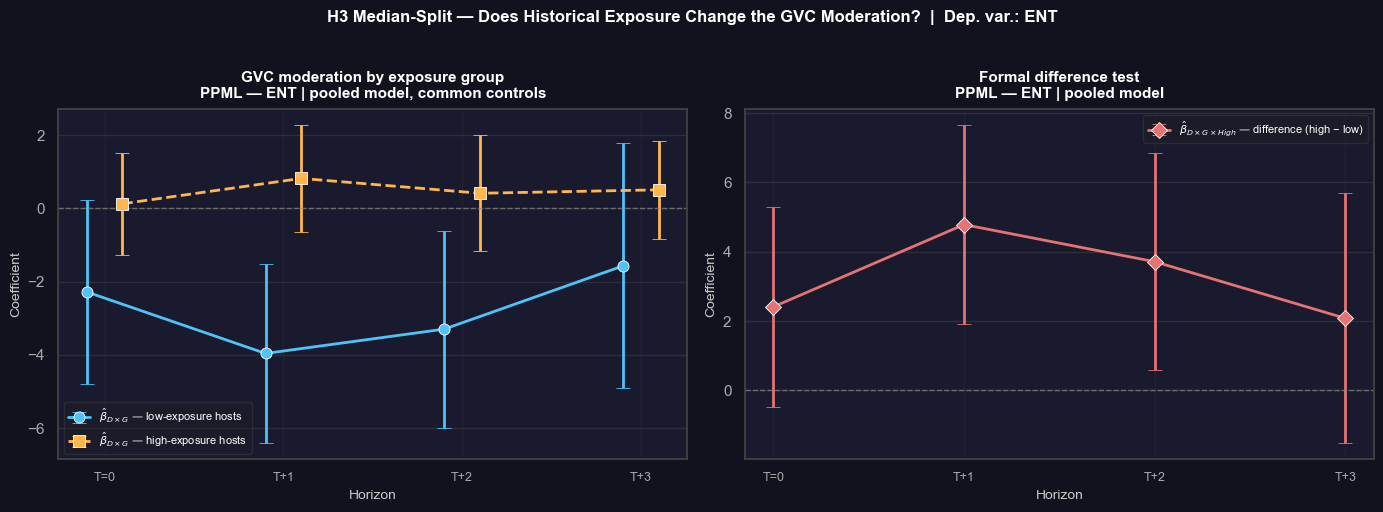

Plot saved to notebooks/h3_median_split_event_study.png


In [39]:
# ── Event study plot — group-specific GVC moderation (PPML) ───────────────────
plt.style.use('dark_background')
sns.set_theme(style='darkgrid', font_scale=1.0)
A1, A2, A3 = '#4fc3f7', '#ffb74d', '#e57373'   # low / high / difference

ms_rows = []
for k in range(4):
    f_hi, f_lo = ppml_ms[k], ppml_ms_lo[k]
    b_l,  se_l = float(f_hi.coef()['D_x_G']),    float(f_hi.se()['D_x_G'])
    b_h,  se_h = float(f_lo.coef()['D_x_G']),    float(f_lo.se()['D_x_G'])
    b_d,  se_d = float(f_hi.coef()['DxG_x_HI']), float(f_hi.se()['DxG_x_HI'])
    ms_rows.append({'horizon': k,
                    'low': b_l,  'low_lo': b_l - 1.96*se_l,  'low_hi': b_l + 1.96*se_l,
                    'high': b_h, 'high_lo': b_h - 1.96*se_h, 'high_hi': b_h + 1.96*se_h,
                    'diff': b_d, 'diff_lo': b_d - 1.96*se_d, 'diff_hi': b_d + 1.96*se_d})
ms_coefs = pd.DataFrame(ms_rows)

fig, (axL, axR) = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#12121f')

hz = ms_coefs['horizon'].values
j = 0.10
axL.errorbar(hz - j, ms_coefs['low'],
             yerr=[ms_coefs['low'] - ms_coefs['low_lo'], ms_coefs['low_hi'] - ms_coefs['low']],
             fmt='o-', color=A1, lw=2, ms=8, capsize=5, mec='white', mew=0.6,
             label=r'$\hat\beta_{D\times G}$ — low-exposure hosts')
axL.errorbar(hz + j, ms_coefs['high'],
             yerr=[ms_coefs['high'] - ms_coefs['high_lo'], ms_coefs['high_hi'] - ms_coefs['high']],
             fmt='s--', color=A2, lw=2, ms=8, capsize=5, mec='white', mew=0.6,
             label=r'$\hat\beta_{D\times G}$ — high-exposure hosts')
axR.errorbar(hz, ms_coefs['diff'],
             yerr=[ms_coefs['diff'] - ms_coefs['diff_lo'], ms_coefs['diff_hi'] - ms_coefs['diff']],
             fmt='D-', color=A3, lw=2, ms=8, capsize=5, mec='white', mew=0.6,
             label=r'$\hat\beta_{D\times G\times High}$ — difference (high − low)')

for ax, title in [(axL, 'GVC moderation by exposure group\nPPML — ENT | pooled model, common controls'),
                  (axR, 'Formal difference test\nPPML — ENT | pooled model')]:
    ax.axhline(0, color='#888', lw=1, ls='--', alpha=0.7)
    ax.set_xticks(hz)
    ax.set_xticklabels(['T=0'] + [f'T+{k}' for k in hz[1:]], fontsize=9, color='#ccc')
    ax.set_xlabel('Horizon', fontsize=10, color='#ccc')
    ax.set_ylabel('Coefficient', fontsize=10, color='#ccc')
    ax.set_title(title, fontsize=11, fontweight='bold', pad=8, color='white')
    ax.tick_params(colors='#aaa')
    for sp in ax.spines.values(): sp.set_edgecolor('#444')
    ax.legend(fontsize=8, framealpha=0.3, facecolor='#1e1e1e',
              edgecolor='#555', labelcolor='white')
    ax.grid(axis='y', alpha=0.25, color='#666')
    ax.grid(axis='x', alpha=0.1, color='#666')
    ax.set_facecolor('#1a1a2e')

fig.suptitle('H3 Median-Split — Does Historical Exposure Change the GVC Moderation?  |  Dep. var.: ENT',
             fontsize=12, fontweight='bold', y=1.02, color='white')
plt.tight_layout()
plt.savefig('notebooks/h3_median_split_event_study.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('Plot saved to notebooks/h3_median_split_event_study.png')

In [40]:
# ── Randomization inference on the group classification (PPML) ────────────────
# Under H0 "the high/low partition carries no information about the GVC moderation",
# any random partition of the hosts into groups of the same sizes is as likely to
# produce the observed triple-interaction statistic. We reassign the high label to
# a random subset of hosts (same group size), rebuild the dummy interactions,
# re-estimate the pooled PPML, and collect the t-statistic of DxG_x_HI.
# RI p-value = share of permuted |t| >= observed |t|. This finite-sample test does
# not rely on asymptotic cluster approximations — valuable given the limited
# number of distinct disaster episodes and the fact that the moderator varies
# only across 56 host countries. The table below triangulates three inference
# methods: dyad-clustered (as the rest of the notebook), host-clustered
# (Moulton-robust asymptotics), and randomization (finite-sample).
import time as _time

B_PERM = 500
rng = np.random.default_rng(42)

hosts_all  = np.array(sorted(df['host_country'].unique()))
hosts_high = set(df.loc[df['high_exp'] == 1, 'host_country'].unique())
n_high     = len(hosts_high)

# Pre-build one estimation frame per horizon (sample does not depend on the labels)
ri_frames = {}
for k in range(4):
    dv = 'ent' if k == 0 else f'ent_lead{k}'
    base_cols = ['dyad_id', 'year', 'host_country', dv,
                 'sev_total', 'gvc_centered', 'D_x_G',
                 'ln_gdp_pc_host', 'ln_gdp_pc_home', 'ge_host']
    fr = df[df[dv] >= 0][base_cols].dropna(
        subset=[c for c in base_cols if c not in ('dyad_id', 'year', 'host_country')]).copy()
    ri_frames[k] = (dv, fr)

rhs_ri = ('sev_total + gvc_centered + D_x_G + D_x_HIp + G_x_HIp + DxG_x_HIp'
          ' + ln_gdp_pc_host + ln_gdp_pc_home + ge_host')

ri_results = []
t0 = _time.time()
for k in range(4):
    dv, fr = ri_frames[k]
    t_obs = float(ppml_ms[k].coef()['DxG_x_HI']) / float(ppml_ms[k].se()['DxG_x_HI'])

    t_perm, n_fail = [], 0
    for b in range(B_PERM):
        hi_set = set(rng.choice(hosts_all, size=n_high, replace=False))
        hi = fr['host_country'].isin(hi_set).astype(float)
        fr['D_x_HIp']   = fr['sev_total'] * hi
        fr['G_x_HIp']   = fr['gvc_centered'] * hi
        fr['DxG_x_HIp'] = fr['D_x_G'] * hi
        try:
            fit_b = pf.fepois(f'{dv} ~ {rhs_ri} | dyad_id + year',
                              data=fr, vcov={'CRV1': 'dyad_id'})
            t_perm.append(float(fit_b.coef()['DxG_x_HIp']) / float(fit_b.se()['DxG_x_HIp']))
        except Exception:
            n_fail += 1

    t_perm = np.array(t_perm)
    p_ri = float((np.abs(t_perm) >= abs(t_obs)).mean()) if len(t_perm) else np.nan
    p_host = float(ppml_ms_host[k].pvalue()['DxG_x_HI'])
    ri_results.append({
        'Horizon': 'T=0' if k == 0 else f'T+{k}',
        't_obs (DxG_x_HI)': round(t_obs, 3),
        'p dyad-clustered (CRV1)': round(float(ppml_ms[k].pvalue()['DxG_x_HI']), 4),
        'p host-clustered (CRV1)': round(p_host, 4),
        'p randomization': round(p_ri, 4),
        'valid draws': len(t_perm),
        'failed draws': n_fail,
    })
    print(f'T+{k}: t_obs={t_obs:+.3f}  p_dyad={float(ppml_ms[k].pvalue()["DxG_x_HI"]):.4f}  '
          f'p_host={p_host:.4f}  p_RI={p_ri:.4f}  '
          f'({len(t_perm)}/{B_PERM} draws, {_time.time()-t0:.0f}s elapsed)')

ri_tbl = pd.DataFrame(ri_results).set_index('Horizon')
print(f'\nRandomization inference: {B_PERM} random host partitions '
      f'(group size fixed at {n_high} high hosts), PPML pooled model')
display(ri_tbl)

export_table(ri_tbl, "h3_randomization_inference", "H3 Step 12 — Randomization inference on group classification (PPML)")


T+0: t_obs=+1.634  p_dyad=0.1023  p_host=0.0079  p_RI=0.2180  (500/500 draws, 584s elapsed)


T+1: t_obs=+3.273  p_dyad=0.0011  p_host=0.0114  p_RI=0.1280  (500/500 draws, 1092s elapsed)


T+2: t_obs=+2.329  p_dyad=0.0198  p_host=0.0736  p_RI=0.2720  (500/500 draws, 1508s elapsed)


T+3: t_obs=+1.129  p_dyad=0.2590  p_host=0.0036  p_RI=0.2960  (500/500 draws, 1851s elapsed)

Randomization inference: 500 random host partitions (group size fixed at 28 high hosts), PPML pooled model


,t_obs (DxG_x_HI),p dyad-clustered (CRV1),p host-clustered (CRV1),p randomization,valid draws,failed draws
Horizon,,,,,,
T=0,1.634,0.1023,0.0079,0.218,500,0
T+1,3.273,0.0011,0.0114,0.128,500,0
T+2,2.329,0.0198,0.0736,0.272,500,0
T+3,1.129,0.2590,0.0036,0.296,500,0


Exported 'h3_randomization_inference': h3_randomization_inference.csv, h3_randomization_inference.html


### Step 12 — Interpretation: Median Split vs Continuous Triple Interaction

**Point estimates: the split confirms and clarifies the continuous result.** In the pooled PPML, the GVC moderation of the disaster effect is strongly negative among **low-exposure hosts** (T+1: −3.96, p = 0.002; T+2: −3.30, p = 0.016) and statistically flat among **high-exposure hosts** (+0.13 to +0.82 across horizons, all p > 0.26). The formal difference — the discrete analogue of the continuous D×G×H — is positive at every horizon and significant (dyad-clustered) at **T+1 (+4.78, p = 0.001)** and **T+2 (+3.71, p = 0.020)**, where the continuous triple reached significance at T+1 only (+7.39, p = 0.017). The fully separate subgroup regressions reproduce the same picture (low group: −4.28*** at T+1, −3.31** at T+2; high group: never distinguishable from zero), so the pooled restriction of common control coefficients is not driving the contrast. On the intensive margin (OLS, conditional on survival) the contrast is much weaker (difference significant only marginally at T+3), consistent with the notebook's running finding that the exit mechanism lives at the total margin.

**Economic reading — an upstream penalty in un-prone hosts, not an upstream premium in prone ones.** The split reveals what the continuous coefficient averages over: it is not that historically exposed hosts retain upstream affiliates unusually strongly — their D×G is simply zero — but that **historically unexposed hosts impose a large upstream penalty** after a disaster: affiliates in upstream, forward-linked sectors shrink significantly more than downstream ones. This is the thesis's surprise-effect logic applied to value chains: in un-prone hosts nothing buffers the propagation of the shock through intermediate-input linkages (Barrot & Sauvagnat, 2016; Bijnens et al., 2024 on flooded suppliers), so the upstream tier bears the differential brunt; in prone hosts, accumulated redundancies neutralise precisely that differential. H3-ext is therefore supported in direction, but its mechanism is better stated as *absence of preparation amplifying upstream vulnerability* than as *preparation amplifying retention*.

**Inference honesty: a large contrast resting on 56 host countries.** The dyad-clustered p-values treat 6,700+ dyads as independent, but the exposure classification varies only across 56 hosts (Moulton problem). Two stress tests probe this. Host-clustered PPML p-values for the difference come out *smaller* at most horizons (0.008 / 0.011 / 0.074 / 0.004 at T=0…T+3) — including at T+3, where the point estimate is clearly noise (p_dyad = 0.26 but p_host = 0.004). That pattern is the classic signature of unreliable cluster-robust asymptotics with few clusters, so host-clustered CRV1 cannot be taken at face value here. Randomization inference, which requires no asymptotics at all — comparing the observed t-statistic against 500 random 28/28 host partitions — is the most conservative and most credible of the three: p_RI = 0.22 / **0.13** / 0.27 / 0.30. The observed exposure-based partition thus produces a stronger T+1 contrast than roughly 87% of random host partitions — clearly suggestive, and directionally aligned with every other estimate in this notebook, but not beyond what host-level noise can generate at conventional thresholds. This caveat applies with equal force to the continuous triple interaction of the main model, whose dyad-clustered p = 0.017 relies on the same host-level variation.

**Design trade-offs, honestly stated.** The pooled split model estimates the same number of interaction parameters as the continuous one, so the sharper T+1/T+2 dyad-clustered significance is not a mechanical power gain from discretisation. What it indicates is that the moderation behaves more like a *threshold contrast between exposure regimes* than a linear-in-H effect — the continuous specification is partly diluted by extreme-H observations, while the median split is immune to them. The cost is the loss of within-group variation in H; the separate subgroup regressions are reported for readability only, the test of the difference being the pooled coefficient.

**Verdict vs the main model.** The median split **confirms** the sign of the continuous triple interaction, **extends** its dyad-clustered significance to T+2, and **localises** the phenomenon in the low-exposure group — the un-prone hosts of the surprise-effect narrative. At the same time, the randomization test shows that with 56 host countries and ~400 distinct disaster country-years, the statistical certainty of the group difference is moderate (p_RI ≈ 0.13 at its strongest), while few-cluster host-clustered asymptotics prove too unstable to be decisive in either direction. For the thesis, the recommended presentation is the group contrast with all three p-values (dyad-clustered, host-clustered, randomization), framing the result as robust in sign and magnitude but of moderate inferential strength — an honest reflection of how much identifying variation the sample contains.

In [41]:
master_path = build_master_html()
webbrowser.open(master_path.resolve().as_uri())

Combined file: <repo>\outputs\tables\h3\all_tables.html


True